# Project 2: dataset screening EDA

This notebook runs the same set of checks on each candidate dataset, so you can pick one for **Project 2 (Version 2, with data)**.

| # | Dataset | Source | Type |
|---|---|---|---|
| A | Machine Predictive Maintenance (AI4I 2020, synthetic) | Kaggle `shivamb/machine-predictive-maintenance-classification` | Tabular, 10k rows |
| B | Semiconductor Wafer Defect Classification (synthetic) | Kaggle `meruvakodandasuraj/semiconductor-wafer-defect-classification-dataset` | Tabular |
| C | Detecting Anomalies in Wafer Manufacturing (MachineHack #18) | Kaggle `arbazkhan971/anomaly-detection` | Tabular, 1,558 anonymous features |
| D | WM-811K wafer maps | Kaggle `qingyi/wm811k-wafer-map` | Images (wafer maps) → engineered tabular features |
| E | Steel Plates Faults (Semeion / UCI) | Kaggle `uciml/faulty-steel-plates` | Tabular, 1,941 rows, 27 named features |
| F | Machine Failure Prediction using Sensor Data | Kaggle `umerrtx/machine-failure-prediction-using-sensor-data` | Tabular, 944 rows, 9 sensor features |
| G | Predicting Manufacturing Defects (synthetic) | Kaggle `rabieelkharoua/predicting-manufacturing-defects-dataset` | Tabular, ~3k rows, named process KPIs |
| H | APS Failure at Scania Trucks | Kaggle `uciml/aps-failure-at-scania-trucks-data-set` | Tabular, 60k rows, 170 anonymous features, official cost matrix |
| I | SECOM semiconductor process | Kaggle `paresh2047/uci-semcom` | Tabular, 1,567 rows, 590 anonymous sensors |
| J | Singapore daily weather: rain tomorrow (optional) | data.gov.sg `d_03bb2eb67ad645d0188342fa74ad7066` | Tabular, built from NEA station records |
| K | MixedWM38 mixed-type wafer maps | Kaggle `co1d7era/mixedtype-wafer-defect-datasets` | 38k uniform 52×52 wafer maps → engineered tabular features |
| L | Semiconductor Sensor Data for Predictive Quality (simulated) | Kaggle `programmer3/semiconductor-sensor-data-for-predictive-quality` | Tabular, ~4.2k wafers, litho/etch/deposition sensors |

E–J were added in the first review, and K–L in the second (semiconductor) round. Their slugs come from public references. If a slug has moved, the section prints the error and is skipped (download by hand and set `LOCAL_DIRS`).

## What the slides require, and the check that tests each one

| Slide requirement | EDA check in this notebook |
|---|---|
| Avoid **large datasets** | Rows, columns, memory footprint |
| Avoid **missing data** | Missing cells overall and per column |
| Avoid **data cleaning** | Duplicates, conflicting duplicate labels, constant / ID / duplicate columns, text columns |
| Avoid **severe imbalance** | Positive rate, plus the number of positives you'd have in validation (for AUC, threshold and calibration bins) |
| "Almost perfect prediction → delete features" | 5-fold CV AUC of an untuned glassbox and blackbox, plus a *difficulty probe* that drops the strongest features |
| Glassbox + blackbox, **each with L2 vs surrogate train loss** | *(added)* Check 10: out-of-fold AUC of ridge-on-0/1 vs logistic, and GBM squared error vs GBM log loss |
| Calibration (reliability diagram, ECE, Platt) | *(added)* Check 11: reliability diagram, Brier, ECE and cross-fitted Platt scaling of the untuned models |
| Compare with **validation AUC** and make a decision; don't overfit validation | *(added)* Check 12: how much a validation-sized AUC and the blackbox − glassbox gap move between splits |
| Evaluation loss **deviates from misclassification**; tune the threshold | *(added)* Check 13: expected-cost curve under a stated cost ratio, best threshold vs 0.5 |
| Local + global **tree SHAP** on a tree-based blackbox | *(added)* Check 14: runs tree SHAP, plots global and local attributions, flags a single dominating feature |
| Find datasets with **high Kaggle usability ratings**; copying Kaggle examples hurts the grade | Not checkable from code. Fill in the usability table below by hand. |
| "Find some Singapore-related datasets" | Section J (optional) |

**Good-habit note (overfitting in validation):** each dataset's **test split is held out before any check that uses the labels**. Label-driven checks such as single-feature AUC and baseline CV run on the development split only. The baselines are untuned, so they're a feasibility check, not model selection.

### How to run
1. `pip install kagglehub pandas numpy scikit-learn scipy matplotlib shap requests` (Python 3.10+).
2. Each Kaggle dataset downloads through `kagglehub`. If it asks for credentials, put your Kaggle API token in `~/.kaggle/kaggle.json`. Alternatively, download the dataset by hand and paste its folder into `LOCAL_DIRS` below.
3. Run all cells. A dataset that fails to load is skipped, and the scorecard at the end is built from whichever ones loaded.

## 0. Setup

In [1]:
import os, re, sys, glob, pickle, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown
from scipy import ndimage

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

SEED = 42
TEST_SIZE = 0.20   # held out before any label-driven check
VAL_SIZE = 0.20    # share of the full data you plan to use for validation

# Where each dataset lives. None means download with kagglehub.
# To use a manual download, paste the folder path, e.g. r"C:\data\wm811k".
LOCAL_DIRS = {
    "ai4i":  os.environ.get("AI4I_DIR"),
    "synth": os.environ.get("SYNTH_DIR"),
    "mh":    os.environ.get("MH_DIR"),
    "wm":    os.environ.get("WM_DIR"),
    "steel": os.environ.get("STEEL_DIR"),
    "mfs":   os.environ.get("MFS_DIR"),
    "mdef":  os.environ.get("MDEF_DIR"),
    "aps":   os.environ.get("APS_DIR"),
    "secom": os.environ.get("SECOM_DIR"),
    "sg":    os.environ.get("SG_DIR"),
    "mixed": os.environ.get("MIXED_DIR"),
    "ssq":   os.environ.get("SSQ_DIR"),     # folder holding the data.gov.sg CSV; None = download through the API
}
KAGGLE_SLUGS = {
    "ai4i":  "shivamb/machine-predictive-maintenance-classification",
    "synth": "meruvakodandasuraj/semiconductor-wafer-defect-classification-dataset",
    "mh":    "arbazkhan971/anomaly-detection",
    "wm":    "qingyi/wm811k-wafer-map",
    "steel": "uciml/faulty-steel-plates",
    "mfs":   "umerrtx/machine-failure-prediction-using-sensor-data",
    "mdef":  "rabieelkharoua/predicting-manufacturing-defects-dataset",
    "aps":   "uciml/aps-failure-at-scania-trucks-data-set",
    "secom": "paresh2047/uci-semcom",
    "mixed": "co1d7era/mixedtype-wafer-defect-datasets",
    "ssq":   "programmer3/semiconductor-sensor-data-for-predictive-quality",
}

# Screening thresholds (judgement calls tuned to the slide guidance; change them if you disagree)
TH = dict(
    rows_large=100_000,      # more rows than this counts as a "large dataset"
    missing_warn=0.01,       # >1% of cells missing -> warn
    missing_bad=0.05,        # >5% of cells missing -> bad
    pos_severe=0.02,         # minority share <2% -> severe imbalance
    pos_moderate=0.10,       # 2-10% -> moderate (needs stratified split + threshold tuning)
    min_val_pos=50,          # fewer positives than this in validation makes AUC/threshold/calibration noisy
    leak_auc=0.95,           # one feature alone giving AUC >= this -> leakage suspect
    near_perfect=0.98,       # baseline CV AUC >= this -> "almost perfect", plan to delete features
    too_hard=0.60,           # baseline CV AUC <= this -> little signal
    glassbox_features=50,    # more features than this makes a glassbox hard to read
)

# Plot style: light surface, recessive axes, two fixed class colours (0 = blue, 1 = orange)
C0, C1 = "#2a78d6", "#eb6834"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "axes.axisbelow": True, "legend.fontsize": 8, "figure.dpi": 100,
})
print("Setup OK. pandas", pd.__version__)

Setup OK. pandas 2.1.4


### Shared EDA helpers
Every dataset section calls these helpers. Each one prints a ✅ / ⚠️ / ❌ verdict and saves its result into `SCORECARD` for the comparison at the end.

In [2]:
SCORECARD = {}
ICON = {"ok": "✅", "warn": "⚠️", "bad": "❌", "info": "ℹ️"}

def record(ds, **kv):
    SCORECARD.setdefault(ds, {}).update(kv)

def say(level, msg):
    display(Markdown(f"{ICON[level]} {msg}"))
    return level

def header(txt):
    display(Markdown(f"#### {txt}"))

# ---------- data access ----------
def get_dataset_dir(key):
    if LOCAL_DIRS.get(key):
        return LOCAL_DIRS[key]
    import kagglehub  # pip install kagglehub
    return kagglehub.dataset_download(KAGGLE_SLUGS[key])

def find_files(root, exts=(".csv",), must=None):
    hits = []
    for dp, _, fns in os.walk(root):
        for fn in fns:
            if fn.lower().endswith(exts) and (must is None or re.search(must, fn, re.I)):
                hits.append(os.path.join(dp, fn))
    return sorted(hits, key=lambda p: -os.path.getsize(p))

# ---------- 1. size ----------
def overview(df, ds, file_mb=None):
    header("Size and structure")
    n, p = df.shape
    mem = df.memory_usage(deep=True).sum() / 1e6
    kinds = df.dtypes.astype(str).value_counts().to_dict()
    print(f"rows={n:,}  columns={p:,}  in-memory={mem:,.1f} MB" + (f"  file={file_mb:,.1f} MB" if file_mb else ""))
    print("dtypes:", kinds)
    display(df.head(5))
    lvl = say("ok", f"Size is fine ({n:,} rows).") if n <= TH["rows_large"] else \
          say("bad", f"Large: {n:,} rows. You'd need to subsample.")
    record(ds, rows=n, columns=p, size=lvl)

# ---------- 2. missing ----------
def missing_report(df, ds, top=20):
    header("Missing data")
    na = df.isna().sum()
    frac = na.sum() / df.size
    cols = na[na > 0].sort_values(ascending=False)
    print(f"missing cells: {na.sum():,} ({frac:.2%}); columns with any missing: {len(cols)}/{df.shape[1]}")
    if len(cols):
        show = (cols.head(top) / len(df)).rename("share_missing")
        display(show.to_frame())
        fig, ax = plt.subplots(figsize=(7, 0.25 * len(show) + 1))
        ax.barh(show.index[::-1].astype(str), show.values[::-1], color=C0, height=0.6)
        ax.set_xlabel("share of rows missing"); ax.set_title("Columns with missing values (top 20)")
        ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()
    lvl = "ok" if frac <= TH["missing_warn"] else ("warn" if frac <= TH["missing_bad"] else "bad")
    say(lvl, {"ok": "No meaningful missing data.", "warn": "Some missing data. Plan imputation.",
              "bad": "Heavy missing data. The slides say to avoid this."}[lvl])
    record(ds, missing_pct=round(100 * frac, 2), missing=lvl)

# ---------- 3. cleaning ----------
def cleaning_report(df, target, ds, id_hint=r"(^id$|_id$|^id_|uid|udi|product id|wafer_id|serial)"):
    header("Data-cleaning load")
    X = df.drop(columns=[target])
    n = len(df)
    dup_rows = int(df.duplicated().sum())
    h = pd.util.hash_pandas_object(X, index=False)
    g = pd.DataFrame({"h": h.values, "y": df[target].values}).groupby("h")["y"].nunique()
    conflicting = int((g > 1).sum())                     # identical features, different labels
    dup_feature_rows = int(h.duplicated().sum())
    nun = X.nunique(dropna=False)
    constant = nun[nun <= 1].index.tolist()
    top_share = X.apply(lambda s: s.value_counts(dropna=False, normalize=True).iloc[0])
    near_const = [c for c in top_share[top_share >= 0.99].index if c not in constant]
    col_hash = X.apply(lambda s: hash(pd.util.hash_pandas_object(s, index=False).values.tobytes()))
    dup_cols = col_hash[col_hash.duplicated()].index.tolist()
    id_like = [c for c in X.columns if (nun[c] == n and X[c].dtype == object) or re.search(id_hint, str(c), re.I)]
    text_cols = [c for c in X.select_dtypes(exclude="number").columns if c not in id_like]
    binary = int((nun == 2).sum())
    rep = pd.DataFrame({"check": ["exact duplicate rows", "duplicate feature rows", "…of which with conflicting labels",
                                  "constant columns", "near-constant columns (≥99% one value)", "duplicate columns",
                                  "ID-like columns", "categorical/text columns", "binary columns"],
                        "count": [dup_rows, dup_feature_rows, conflicting, len(constant), len(near_const),
                                  len(dup_cols), len(id_like), len(text_cols), binary]})
    display(rep)
    if id_like: print("ID-like (drop before modelling):", id_like)
    if text_cols: print("categorical:", {c: int(nun[c]) for c in text_cols}, "(unique values)")
    issues = (dup_rows > 0.01 * n) + (conflicting > 0) + (len(constant) + len(dup_cols) > 0.05 * X.shape[1])
    lvl = "ok" if issues == 0 else ("warn" if issues == 1 else "bad")
    say(lvl, {"ok": "Little cleaning needed beyond dropping IDs.", "warn": "Some cleaning needed (see table).",
              "bad": "Substantial cleaning needed (see table)."}[lvl])
    record(ds, cleaning=lvl, dup_rows=dup_rows, conflicting_dups=conflicting,
           constant_cols=len(constant), dup_cols=len(dup_cols))
    return dict(id_like=id_like, constant=constant, near_const=near_const, dup_cols=dup_cols, text=text_cols)

# ---------- 4. target / imbalance ----------
def to_binary(y, positive=None):
    # Map a label column to 0/1. The positive class is the 'bad' outcome when it can be identified, else the minority class.
    y = pd.Series(y)
    vals = list(pd.unique(y.dropna()))
    if len(vals) != 2:
        raise ValueError(f"target has {len(vals)} classes: {vals[:10]}; pick a binary target")
    if positive is None:
        bad = [v for v in vals if re.search(r"(fail|defect|anomal|bad|faulty|reject|^1$|^1\.0$|^yes$|^true$)", str(v), re.I)]
        positive = bad[0] if len(bad) == 1 else y.value_counts().idxmin()
    return (y == positive).astype(int), positive

def target_report(y, ds, label="target"):
    header("Class balance")
    n = len(y); pos = int(y.sum()); rate = pos / n
    minority = min(rate, 1 - rate)
    val_pos = int(round(pos * VAL_SIZE)); test_pos = int(round(pos * TEST_SIZE))
    print(f"positives={pos:,} / {n:,}  rate={rate:.2%}  imbalance ratio ≈ 1:{(n - pos) / max(pos, 1):.0f}")
    print(f"expected positives: validation≈{val_pos}, test≈{test_pos}; per calibration bin (10 bins)≈{val_pos / 10:.0f}")
    fig, ax = plt.subplots(figsize=(6, 1.6))
    ax.barh(["0 (negative)", "1 (positive)"], [n - pos, pos], color=[C0, C1], height=0.55)
    for i, v in enumerate([n - pos, pos]):
        ax.text(v, i, f"  {v:,} ({v / n:.1%})", va="center", fontsize=8, color=INK2)
    ax.set_title(f"{label}: class counts"); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, n * 1.25); plt.tight_layout(); plt.show()
    lvl = "ok" if minority >= TH["pos_moderate"] else ("warn" if minority >= TH["pos_severe"] else "bad")
    say(lvl, {"ok": "Balance is fine.",
              "warn": "Moderate imbalance. Use a stratified split, report AUC, and tune the threshold.",
              "bad": "Severe imbalance. The slides say to avoid this."}[lvl])
    lvl2 = "ok" if val_pos >= TH["min_val_pos"] else "warn"
    say(lvl2, f"About {val_pos} positives in validation" +
        ("." if lvl2 == "ok" else ": AUC, threshold and calibration estimates will be noisy. Keep the grids small and consider CV."))
    record(ds, pos_rate_pct=round(100 * rate, 2), imbalance=lvl, val_positives=val_pos, val_size=lvl2)

def hold_out(df, y, ds):
    dev_idx, test_idx = train_test_split(np.arange(len(df)), test_size=TEST_SIZE, stratify=y, random_state=SEED)
    print(f"Held out test: {len(test_idx):,} rows ({int(y.iloc[test_idx].sum())} positives). "
          f"Development split for label-driven checks: {len(dev_idx):,} rows.")
    return dev_idx, test_idx

def make_X(df, drop, max_card=20):
    # Numeric features plus one-hot encoding of low-cardinality categoricals; drops IDs/leakage/target.
    X = df.drop(columns=[c for c in drop if c in df.columns])
    cat = [c for c in X.select_dtypes(exclude="number").columns if X[c].nunique() <= max_card]
    other_text = [c for c in X.select_dtypes(exclude="number").columns if c not in cat]
    X = X.drop(columns=other_text)
    X = pd.get_dummies(X, columns=cat, drop_first=False, dtype=float)
    return X.astype(float)

# ---------- 5. leakage ----------
def leakage_scan(X, y, ds, top=15):
    header("Leakage scan: single-feature AUC (development split)")
    scores = {}
    for c in X.columns:
        s = X[c]
        if s.nunique() < 2: continue
        s = s.fillna(s.median())
        a = roc_auc_score(y, s)
        scores[c] = max(a, 1 - a)
    s = pd.Series(scores).sort_values(ascending=False)
    show = s.head(top)
    fig, ax = plt.subplots(figsize=(7, 0.28 * len(show) + 1))
    ax.barh(show.index[::-1].astype(str), show.values[::-1] - 0.5, left=0.5, color=C0, height=0.6)
    ax.axvline(TH["leak_auc"], color=INK2, lw=1, ls="--"); ax.text(TH["leak_auc"], len(show) - 0.4, " leak line", fontsize=7, color=INK2)
    ax.set_xlim(0.5, 1.0); ax.set_xlabel("AUC from this feature alone (0.5 = no signal)")
    ax.set_title(f"Strongest single features (top {len(show)})"); ax.grid(axis="y", visible=False)
    plt.tight_layout(); plt.show()
    leaks = s[s >= TH["leak_auc"]].index.tolist()
    lvl = say("bad", f"Leakage suspects (AUC ≥ {TH['leak_auc']}): {leaks}. Drop them, or explain why they're legitimate.") if leaks \
          else say("ok", f"No single feature is suspiciously predictive (max AUC {s.iloc[0]:.3f}, from `{s.index[0]}`).")
    record(ds, max_single_auc=round(float(s.iloc[0]), 3), leakage=lvl)
    return s

# ---------- 6. distributions ----------
def class_distributions(X, y, cols, title="Feature distributions by class"):
    cols = list(cols)[:8]
    if not cols: return
    nc = 4; nr = int(np.ceil(len(cols) / nc))
    fig, axes = plt.subplots(nr, nc, figsize=(12, 2.4 * nr)); axes = np.atleast_1d(axes).ravel()
    for ax, c in zip(axes, cols):
        v = X[c]
        bins = np.histogram_bin_edges(v.dropna(), bins=30)
        ax.hist(v[y == 0].dropna(), bins=bins, density=True, histtype="step", lw=2, color=C0, label="0")
        ax.hist(v[y == 1].dropna(), bins=bins, density=True, histtype="step", lw=2, color=C1, label="1")
        ax.set_title(str(c)[:32], fontsize=9); ax.set_yticks([])
    for ax in axes[len(cols):]: ax.axis("off")
    axes[0].legend(title="class")
    fig.suptitle(title, fontweight="bold"); plt.tight_layout(); plt.show()

# ---------- 7. correlation ----------
def correlation_check(X, ds, thr=0.95):
    header("Correlated features (glassbox stability)")
    Xn = X.loc[:, X.nunique() > 1]
    corr = Xn.corr().abs()
    iu = np.triu_indices_from(corr, k=1)
    vals = corr.values[iu]
    pairs = [(corr.index[i], corr.columns[j], corr.values[i, j]) for i, j in zip(*iu) if corr.values[i, j] >= thr]
    print(f"{Xn.shape[1]} features; pairs with |r| ≥ {thr}: {len(pairs)}")
    if Xn.shape[1] <= 25:
        fig, ax = plt.subplots(figsize=(0.45 * Xn.shape[1] + 2.5, 0.45 * Xn.shape[1] + 1.5))
        im = ax.imshow(Xn.corr().values, cmap="RdBu_r", vmin=-1, vmax=1)
        ax.set_xticks(range(Xn.shape[1])); ax.set_xticklabels([str(c)[:18] for c in Xn.columns], rotation=90)
        ax.set_yticks(range(Xn.shape[1])); ax.set_yticklabels([str(c)[:18] for c in Xn.columns])
        ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.7, label="Pearson r"); ax.set_title("Correlation matrix")
        plt.tight_layout(); plt.show()
    else:
        fig, ax = plt.subplots(figsize=(6, 2.4))
        ax.hist(vals[~np.isnan(vals)], bins=50, color=C0); ax.set_xlabel("|r| between feature pairs")
        ax.set_title("Distribution of pairwise |correlation|"); plt.tight_layout(); plt.show()
    if pairs:
        display(pd.DataFrame(pairs[:15], columns=["feature_a", "feature_b", "|r|"]))
    lvl = say("ok", "No near-duplicate features.") if not pairs else \
          say("warn", f"{len(pairs)} highly correlated pairs. Use LASSO or a ridge penalty, or drop one of each pair, before reading glassbox coefficients.")
    record(ds, corr_pairs=len(pairs))

# ---------- 8. difficulty (near-perfect?) ----------
def _models():
    glass = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                          LogisticRegression(max_iter=3000, C=1.0))
    black = HistGradientBoostingClassifier(random_state=SEED)
    return {"glassbox: logistic regression": glass, "blackbox: gradient boosting": black}

def baseline_check(X, y, ds):
    header("Difficulty check: untuned 5-fold CV AUC (development split)")
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    res = {}
    for name, m in _models().items():
        t = time.time()
        s = cross_val_score(m, X, y, cv=cv, scoring="roc_auc", n_jobs=-1)
        res[name] = s
        print(f"{name:32s} AUC = {s.mean():.3f} ± {s.std():.3f}   ({time.time() - t:.1f}s)")
    best = max(v.mean() for v in res.values())
    if best >= TH["near_perfect"]:
        lvl = say("warn", f"Almost perfect (AUC {best:.3f}). The slides say to delete some features to make it harder. See the difficulty probe.")
    elif best <= TH["too_hard"]:
        lvl = say("bad", f"Weak signal (AUC {best:.3f}). The model comparison would be mostly noise.")
    else:
        lvl = say("ok", f"Room to compare models (best AUC {best:.3f}).")
    gap = res["blackbox: gradient boosting"].mean() - res["glassbox: logistic regression"].mean()
    print(f"blackbox − glassbox AUC gap: {gap:+.3f} (a positive gap gives you an interpretability-vs-performance story)")
    record(ds, auc_glass=round(res["glassbox: logistic regression"].mean(), 3),
           auc_black=round(res["blackbox: gradient boosting"].mean(), 3), difficulty=lvl)
    return res

def difficulty_probe(X, y, ranking, ks=(0, 1, 2, 3)):
    header("Difficulty probe: GBM AUC after dropping the k strongest single features")
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    rows = []
    for k in ks:
        drop = list(ranking.index[:k])
        Xk = X.drop(columns=drop)
        s = cross_val_score(HistGradientBoostingClassifier(random_state=SEED), Xk, y, cv=cv, scoring="roc_auc", n_jobs=-1)
        rows.append({"k dropped": k, "dropped": ", ".join(map(str, drop)) or "—", "GBM CV AUC": round(s.mean(), 3)})
    out = pd.DataFrame(rows); display(out)
    return out

# ---------- 9. high-dimensional view ----------
def pca_view(X, y, title="PCA (standardised)"):
    Xs = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X))
    p = PCA(n_components=min(50, Xs.shape[1]), random_state=SEED).fit(Xs)
    Z = p.transform(Xs)[:, :2]
    cum = np.cumsum(p.explained_variance_ratio_)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    axes[0].scatter(Z[y == 0, 0], Z[y == 0, 1], s=9, color=C0, alpha=0.5, label="0", edgecolor="none")
    axes[0].scatter(Z[y == 1, 0], Z[y == 1, 1], s=12, color=C1, alpha=0.8, label="1", edgecolor="#fcfcfb", linewidth=0.5)
    axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2"); axes[0].legend(title="class"); axes[0].set_title(title)
    axes[1].plot(np.arange(1, len(cum) + 1), cum, color=C0, lw=2)
    axes[1].set_xlabel("number of components"); axes[1].set_ylabel("cumulative variance explained")
    axes[1].set_title("Variance captured by first 50 PCs"); axes[1].set_ylim(0, 1)
    plt.tight_layout(); plt.show()
    print(f"First 2 PCs explain {cum[1]:.1%}; first 50 explain {cum[-1]:.1%}.")

def interpretability_note(ds, named, note):
    header("Interpretability readiness (for SHAP)")
    lvl = say("ok" if named else "bad", note)
    record(ds, named_features=lvl)

print("Helpers loaded.")

Helpers loaded.


### Extra checks added in the review (10–14)
The original helpers cover data hygiene. The slides also grade the modelling steps, so these checks test, on the development split, whether each step will produce something worth presenting:

- **10. Train loss.** Do the L2 and surrogate versions of the glassbox and the blackbox both train, and how far apart are they?
- **11. Calibration.** Reliability diagram, Brier score, ECE, and what Platt scaling fixes.
- **12. Validation noise.** At the planned validation size, how wide is the AUC uncertainty, and does the blackbox − glassbox gap survive it? This is the "optimiser's curse" from the slides.
- **13. Evaluation loss.** Under a stated cost ratio, how far is the cost-minimising threshold from 0.5, and how much does it save?
- **14. Tree SHAP.** Does tree SHAP run, and is the attribution spread over several features or dominated by one?

All of them use 5-fold out-of-fold predictions of untuned models. They're feasibility signals, not results for the slides.

In [3]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import brier_score_loss
from scipy.stats import spearmanr


# ---------- 10. train loss: L2 vs surrogate, for a glassbox and a blackbox ----------
def _four_models():
    # The slides ask for two versions of each model: L2 loss vs another surrogate loss.
    # Glassbox: linear probability model (ridge on 0/1) vs logistic regression (binomial deviance).
    # Blackbox: gradient boosting with squared error vs log loss.
    lin = lambda est: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), est)
    return {
        ("glassbox", "L2"): lin(Ridge(alpha=1.0)),
        ("glassbox", "log loss"): lin(LogisticRegression(max_iter=3000, C=1.0)),
        ("blackbox", "L2"): HistGradientBoostingRegressor(loss="squared_error", random_state=SEED),
        ("blackbox", "log loss"): HistGradientBoostingClassifier(random_state=SEED),
    }

def oof_scores(X, y):
    # 5-fold out-of-fold scores on the development split, so nothing is scored by a model that saw it
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    out = {}
    for (box, loss), m in _four_models().items():
        if loss == "L2":
            s = cross_val_predict(m, X, y, cv=cv, n_jobs=-1)
        else:
            s = cross_val_predict(m, X, y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
        out[(box, loss)] = np.asarray(s, dtype=float)
    return out

def loss_check(X, y, ds):
    header("Train loss: L2 vs surrogate (5-fold out-of-fold AUC, development split)")
    S = oof_scores(X, y)
    rows = [{"model": b, "train loss": l, "OOF AUC": round(roc_auc_score(y, s), 3),
             "scores outside [0, 1]": f"{np.mean((s < 0) | (s > 1)):.1%}"} for (b, l), s in S.items()]
    display(pd.DataFrame(rows))
    d_glass = roc_auc_score(y, S[("glassbox", "log loss")]) - roc_auc_score(y, S[("glassbox", "L2")])
    d_black = roc_auc_score(y, S[("blackbox", "log loss")]) - roc_auc_score(y, S[("blackbox", "L2")])
    print(f"surrogate − L2 AUC: glassbox {d_glass:+.3f}, blackbox {d_black:+.3f}")
    say("info", "All four versions train without trouble. Small AUC differences are normal, because AUC only depends on the "
                "ranking. The L2 versions show their weakness in calibration and in scores outside [0, 1] (next check).")
    record(ds, auc_glass_l2=round(roc_auc_score(y, S[("glassbox", "L2")]), 3),
           auc_black_l2=round(roc_auc_score(y, S[("blackbox", "L2")]), 3))
    return S

# ---------- 11. calibration ----------
def ece_score(y, p, bins=10):
    y = np.asarray(y); p = np.clip(np.asarray(p, dtype=float), 0, 1)
    idx = np.clip(np.digitize(p, np.linspace(0, 1, bins + 1)[1:-1]), 0, bins - 1)
    return float(sum((idx == b).mean() * abs(y[idx == b].mean() - p[idx == b].mean()) for b in range(bins) if (idx == b).any()))

def calibration_check(S, y, ds, bins=10):
    header("Calibration of the untuned models (out-of-fold, development split)")
    y = np.asarray(y)
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    rows = []
    fig, ax = plt.subplots(figsize=(5.2, 4.2))
    ax.plot([0, 1], [0, 1], color=INK2, lw=1, ls="--", label="perfect")
    colours = {"glassbox": C0, "blackbox": C1}
    for (box, loss), s in S.items():
        p = np.clip(s, 0, 1)
        q = np.unique(np.quantile(p, np.linspace(0, 1, bins + 1)))   # quantile bins: equal counts per bin
        idx = np.clip(np.digitize(p, q[1:-1]), 0, len(q) - 2)
        mp = [p[idx == b].mean() for b in range(len(q) - 1) if (idx == b).any()]
        oy = [y[idx == b].mean() for b in range(len(q) - 1) if (idx == b).any()]
        ax.plot(mp, oy, marker="o", ms=3, lw=1.5 if loss == "log loss" else 1, ls="-" if loss == "log loss" else ":",
                color=colours[box], label=f"{box}, {loss}")
        rows.append({"model": box, "train loss": loss, "Brier": round(brier_score_loss(y, p), 4),
                     "ECE (10 bins)": round(ece_score(y, p, bins), 4), "mean score": round(p.mean(), 4)})
    ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed positive rate")
    ax.set_title("Reliability diagram (quantile bins)"); ax.legend(fontsize=7)
    plt.tight_layout(); plt.show()
    # Platt scaling of the blackbox log-loss scores, cross-fitted so the recalibration is honest
    sb = S[("blackbox", "log loss")]
    logit = np.log(np.clip(sb, 1e-6, 1 - 1e-6) / (1 - np.clip(sb, 1e-6, 1 - 1e-6))).reshape(-1, 1)
    platt = cross_val_predict(LogisticRegression(), logit, y, cv=cv, method="predict_proba")[:, 1]
    rows.append({"model": "blackbox + Platt", "train loss": "log loss", "Brier": round(brier_score_loss(y, platt), 4),
                 "ECE (10 bins)": round(ece_score(y, platt, bins), 4), "mean score": round(platt.mean(), 4)})
    tab = pd.DataFrame(rows); display(tab)
    print(f"base rate in development split = {y.mean():.4f}")
    val_bin = SCORECARD.get(ds, {}).get("val_positives", y.sum() * VAL_SIZE / (1 - TEST_SIZE)) / bins
    lvl = say("ok" if val_bin >= 10 else "warn",
              f"About {val_bin:.0f} validation positives per calibration bin." +
              ("" if val_bin >= 10 else " The reliability diagram on validation alone will be noisy: use fewer bins, quantile bins, or out-of-fold predictions."))
    record(ds, ece_black=float(tab.iloc[3]["ECE (10 bins)"]), ece_black_platt=float(tab.iloc[-1]["ECE (10 bins)"]), calibration=lvl)
    return platt

# ---------- 12. validation noise (optimiser's curse) ----------
def auc_noise_check(S, y, ds, draws=300):
    header("Validation noise: can a validation split of this size tell the models apart?")
    y = np.asarray(y)
    frac = VAL_SIZE / (1 - TEST_SIZE)            # validation share of the development split
    rng = np.random.default_rng(SEED)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    n1, n0 = max(int(round(len(pos) * frac)), 2), max(int(round(len(neg) * frac)), 2)
    g, b = S[("glassbox", "log loss")], S[("blackbox", "log loss")]
    auc_b, gaps = [], []
    for _ in range(draws):                       # stratified validation-sized subsamples of the out-of-fold scores
        i = np.r_[rng.choice(pos, n1, replace=False), rng.choice(neg, n0, replace=False)]
        ab = roc_auc_score(y[i], b[i]); auc_b.append(ab); gaps.append(ab - roc_auc_score(y[i], g[i]))
    auc_b, gaps = np.array(auc_b), np.array(gaps)
    half = 1.96 * auc_b.std()
    print(f"validation size ≈ {n1 + n0:,} rows ({n1} positives)")
    print(f"blackbox AUC on a validation-sized split: {auc_b.mean():.3f} ± {half:.3f} (95% range)")
    print(f"blackbox − glassbox gap: {gaps.mean():+.3f}, sd {gaps.std():.3f}; blackbox wins in {np.mean(gaps > 0):.0%} of draws")
    fig, ax = plt.subplots(figsize=(6, 2.4))
    ax.hist(gaps, bins=30, color=C0); ax.axvline(0, color=INK2, lw=1, ls="--")
    ax.set_xlabel("blackbox − glassbox AUC on one validation split"); ax.set_title("How much the model comparison moves between splits")
    plt.tight_layout(); plt.show()
    lvl = say("ok" if abs(gaps.mean()) > 2 * gaps.std() else "warn",
              "The model comparison is stable at this validation size." if abs(gaps.mean()) > 2 * gaps.std() else
              "A single validation split can't reliably separate glassbox and blackbox. Keep the search small, "
              "report the uncertainty, or use repeated CV for the decision.")
    record(ds, auc_ci_halfwidth=round(half, 3), gap_sd=round(gaps.std(), 3), noise=lvl)

# ---------- 13. evaluation loss and threshold ----------
def cost_threshold_check(p, y, ds, c_fn, c_fp, story=""):
    header(f"Evaluation loss: threshold that minimises expected cost (FN = {c_fn}, FP = {c_fp})")
    if story: display(Markdown(f"*Cost story:* {story}"))
    y = np.asarray(y); p = np.asarray(p)
    ts = np.linspace(0.005, 0.995, 199)
    cost = np.array([(c_fn * ((p < t) & (y == 1)).sum() + c_fp * ((p >= t) & (y == 0)).sum()) / len(y) for t in ts])
    t_star = ts[cost.argmin()]; c05 = cost[np.abs(ts - 0.5).argmin()]
    bayes = c_fp / (c_fp + c_fn)
    fig, ax = plt.subplots(figsize=(6.5, 2.8))
    ax.plot(ts, cost, color=C0, lw=2)
    for t, lab in [(0.5, "0.5"), (t_star, "best"), (bayes, "cost ratio")]:
        ax.axvline(t, color=INK2, lw=1, ls="--"); ax.text(t, cost.max(), f" {lab}", fontsize=7, color=INK2, va="top")
    ax.set_xlabel("threshold on blackbox probability"); ax.set_ylabel("cost per item"); ax.set_title("Expected cost vs threshold (out-of-fold)")
    plt.tight_layout(); plt.show()
    saving = 1 - cost.min() / c05 if c05 > 0 else 0.0
    print(f"best threshold = {t_star:.3f} (cost {cost.min():.4f}/item); threshold 0.5 costs {c05:.4f}/item -> saving {saving:.0%}")
    print(f"for a calibrated model the cost-ratio threshold would be {bayes:.3f}; "
          f"flag-nothing costs {c_fn * y.mean():.4f}, flag-everything costs {c_fp * (1 - y.mean()):.4f}")
    lvl = say("ok" if saving >= 0.10 else "info",
              "The evaluation loss moves the decision a lot away from 0.5, which gives the threshold slide something to say." if saving >= 0.10 else
              "The evaluation loss barely changes the decision at this cost ratio. Justify a different ratio, or expect a thin threshold slide.")
    record(ds, t_star=round(t_star, 3), cost_saving_pct=round(100 * saving, 1))

# ---------- 14. tree SHAP smoke test ----------
def shap_check(X, y, ds, ranking, n=2000):
    header("Tree SHAP smoke test (blackbox gradient boosting, development split)")
    try:
        import shap  # pip install shap
    except ImportError:
        say("warn", "`shap` is not installed (`pip install shap`). Skipping."); return
    m = HistGradientBoostingClassifier(random_state=SEED).fit(X, y)
    Xs = X.sample(min(n, len(X)), random_state=SEED)
    sv = shap.TreeExplainer(m).shap_values(Xs)
    if isinstance(sv, list): sv = sv[1]
    sv = np.asarray(sv)
    if sv.ndim == 3: sv = sv[..., 1]
    glob = pd.Series(np.abs(sv).mean(0), index=X.columns).sort_values(ascending=False)
    i = int(np.argmax(m.predict_proba(Xs)[:, 1]))
    loc = pd.Series(sv[i], index=X.columns)
    loc = loc.reindex(loc.abs().sort_values(ascending=False).index[:8])
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
    g10 = glob.head(10)
    axes[0].barh(g10.index[::-1].astype(str), g10.values[::-1], color=C0, height=0.6)
    axes[0].set_xlabel("mean |SHAP| (log-odds)"); axes[0].set_title("Global: top features"); axes[0].grid(axis="y", visible=False)
    axes[1].barh(loc.index[::-1].astype(str), loc.values[::-1], color=[C1 if v > 0 else C0 for v in loc.values[::-1]], height=0.6)
    axes[1].axvline(0, color=INK2, lw=1); axes[1].set_xlabel("SHAP value (log-odds)")
    axes[1].set_title("Local: highest-risk item in the sample"); axes[1].grid(axis="y", visible=False)
    plt.tight_layout(); plt.show()
    share = glob.iloc[0] / glob.sum()
    common = [c for c in glob.index if c in ranking.index]
    rho = spearmanr(glob[common].values, ranking[common].values).correlation if len(common) > 2 else np.nan
    print(f"top feature `{glob.index[0]}` carries {share:.0%} of total mean |SHAP|; "
          f"rank agreement with single-feature AUC (Spearman) = {rho:.2f}")
    lvl = say("warn" if share > 0.6 else "ok",
              "One feature dominates the SHAP story. Check it for leakage, or drop it to make the task harder." if share > 0.6 else
              "Tree SHAP runs, and attributions are spread over several features: enough material for local and global plots.")
    record(ds, shap_top=str(glob.index[0]), shap_top_share=round(share, 2), shap=lvl)

def extended_checks(X, y, ds, ranking, c_fn, c_fp, story=""):
    # Runs checks 10-14 on the development split only
    S = loss_check(X, y, ds)
    calibration_check(S, y, ds)
    auc_noise_check(S, y, ds)
    cost_threshold_check(S[("blackbox", "log loss")], y, ds, c_fn, c_fp, story)
    shap_check(X, y, ds, ranking)
    return S

def standard_screen(df, target, ds, positive=None, drop=(), named=True, named_note="", max_card=20):
    # The same sequence as sections A-D, for the extra candidates: returns the development-split X, y and ranking
    missing_report(df, ds)
    info = cleaning_report(df, target, ds)
    y, pos = to_binary(df[target], positive=positive)
    print("positive class =", pos)
    target_report(y, ds, label=str(target))
    dev, test = hold_out(df, y, ds)
    X = make_X(df, drop=[target] + list(drop) + info["id_like"] + info["constant"], max_card=max_card)
    X_dev, y_dev = X.iloc[dev], y.iloc[dev]
    print(f"model features ({X.shape[1]}):", list(X.columns)[:25], "…" if X.shape[1] > 25 else "")
    rank = leakage_scan(X_dev, y_dev, ds)
    if X.shape[1] <= 60:
        class_distributions(X_dev, y_dev, rank.index)
    else:
        pca_view(X_dev, y_dev)
    correlation_check(X_dev, ds)
    baseline_check(X_dev, y_dev, ds)
    difficulty_probe(X_dev, y_dev, rank)
    interpretability_note(ds, named, named_note)
    return X_dev, y_dev, rank

print("Extra helpers loaded.")

Extra helpers loaded.


### Kaggle usability and copy risk (fill in by hand)
The slides say to prefer datasets with **high Kaggle usability ratings**, and that copying Kaggle examples hurts the grade. Neither is visible from code, so fill this in from each dataset's Kaggle page. A very popular dataset (hundreds of public notebooks) means your choices need to look clearly your own: your cost story, your feature deletions, your threshold.

In [4]:
KAGGLE_META = pd.DataFrame({
    "usability (0-10)": {k: None for k in KAGGLE_SLUGS},
    "public notebooks": {k: None for k in KAGGLE_SLUGS},
    "real or synthetic": {"ai4i": "synthetic", "synth": "synthetic", "mh": "real (anonymised)", "wm": "real",
                          "steel": "real", "mfs": "unclear", "mdef": "synthetic", "aps": "real (anonymised)", "secom": "real (anonymised)",
                          "mixed": "real + GAN-augmented", "ssq": "simulated"},
})
KAGGLE_META.index = [f"{k}  ({v})" for k, v in KAGGLE_SLUGS.items()]
display(KAGGLE_META)

,usability (0-10),public notebooks,real or synthetic
ai4i (shivamb/machine-predictive-maintenance-classification),None,None,synthetic
synth (meruvakodandasuraj/semiconductor-wafer-defect-classification-dataset),None,None,synthetic
mh (arbazkhan971/anomaly-detection),None,None,real (anonymised)
wm (qingyi/wm811k-wafer-map),None,None,real
steel (uciml/faulty-steel-plates),None,None,real
mfs (umerrtx/machine-failure-prediction-using-sensor-data),None,None,unclear
mdef (rabieelkharoua/predicting-manufacturing-defects-dataset),None,None,synthetic
aps (uciml/aps-failure-at-scania-trucks-data-set),None,None,real (anonymised)
secom (paresh2047/uci-semcom),None,None,real (anonymised)
mixed (co1d7era/mixedtype-wafer-defect-datasets),None,None,real + GAN-augmented


---
## A. Machine Predictive Maintenance (AI4I 2020)
Each row is one machine reading: product quality type (L/M/H), air and process temperature, rotational speed, torque and tool wear.
- **Target:** `Target` (1 = machine failure).
- **Leakage column:** `Failure Type` names the failure mode, so it gives away the label. It's used for EDA only, never as a feature.

The loader also accepts the UCI version (`Machine failure` plus the TWF/HDF/PWF/OSF/RNF columns).

In [5]:
DS = "A · AI4I"
try:
    root = get_dataset_dir("ai4i")
    f = find_files(root)[0]
    ai = pd.read_csv(f)
    print("loaded", f)
    if "Target" in ai.columns:
        TARGET_A, LEAK_A = "Target", ["Failure Type"]
    else:  # UCI schema
        TARGET_A, LEAK_A = "Machine failure", ["TWF", "HDF", "PWF", "OSF", "RNF"]
    overview(ai, DS, file_mb=os.path.getsize(f) / 1e6)
except Exception as e:
    ai = None; print("AI4I not loaded:", repr(e))

loaded /Users/testuser/.cache/kagglehub/datasets/shivamb/machine-predictive-maintenance-classification/versions/1/predictive_maintenance.csv


#### Size and structure

rows=10,000  columns=10  in-memory=2.4 MB  file=0.5 MB
dtypes: {'int64': 4, 'object': 3, 'float64': 3}


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


✅ Size is fine (10,000 rows).

In [6]:
if ai is not None:
    missing_report(ai, DS)
    info_A = cleaning_report(ai, TARGET_A, DS)

#### Missing data

missing cells: 0 (0.00%); columns with any missing: 0/10


✅ No meaningful missing data.

#### Data-cleaning load

,check,count
0,exact duplicate rows,0
1,duplicate feature rows,0
2,…of which with conflicting labels,0
3,constant columns,0
4,near-constant columns (≥99% one value),0
5,duplicate columns,0
6,ID-like columns,2
7,categorical/text columns,2
8,binary columns,0


ID-like (drop before modelling): ['UDI', 'Product ID']
categorical: {'Type': 3, 'Failure Type': 6} (unique values)


✅ Little cleaning needed beyond dropping IDs.

#### Class balance

positives=339 / 10,000  rate=3.39%  imbalance ratio ≈ 1:28
expected positives: validation≈68, test≈68; per calibration bin (10 bins)≈7


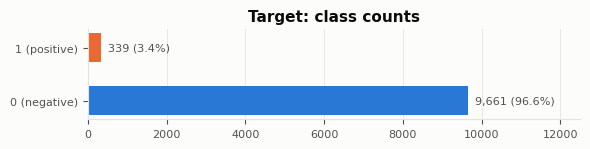

⚠️ Moderate imbalance. Use a stratified split, report AUC, and tune the threshold.

✅ About 68 positives in validation.

In [7]:
if ai is not None:
    yA, posA = to_binary(ai[TARGET_A], positive=1)
    target_report(yA, DS, label=TARGET_A)

**Label consistency check.** `Target` and `Failure Type` should agree. The public versions contain a few contradictions (failures labelled "No Failure", and random failures with Target 0). Decide how to handle these rows, and say so on a slide.

In [8]:
if ai is not None:
    if "Failure Type" in ai.columns:
        display(pd.crosstab(ai["Failure Type"], ai[TARGET_A], margins=True))
        bad = ((ai[TARGET_A] == 1) & (ai["Failure Type"] == "No Failure")) | ((ai[TARGET_A] == 0) & (ai["Failure Type"] != "No Failure"))
    else:
        modes = ai[LEAK_A].sum(axis=1)
        display(pd.crosstab(modes, ai[TARGET_A], margins=True).rename_axis("number of failure modes flagged"))
        bad = (ai[TARGET_A] == 1) & (modes == 0) | (ai[TARGET_A] == 0) & (modes > 0)
    say("warn" if bad.sum() else "ok", f"{int(bad.sum())} rows where the label and the failure type disagree.")
    record(DS, label_conflicts=int(bad.sum()))

Target,0,1,All
Failure Type,,,
Heat Dissipation Failure,0,112,112
No Failure,9643,9,9652
Overstrain Failure,0,78,78
Power Failure,0,95,95
Random Failures,18,0,18
Tool Wear Failure,0,45,45
All,9661,339,10000


⚠️ 27 rows where the label and the failure type disagree.

Held out test: 2,000 rows (68 positives). Development split for label-driven checks: 8,000 rows.
model features: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_H', 'Type_L', 'Type_M']


#### Leakage scan: single-feature AUC (development split)

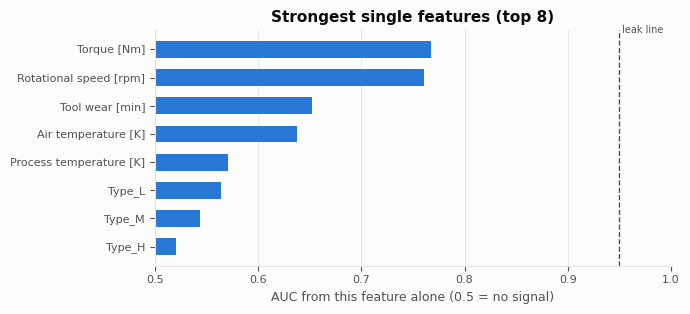

✅ No single feature is suspiciously predictive (max AUC 0.768, from `Torque [Nm]`).

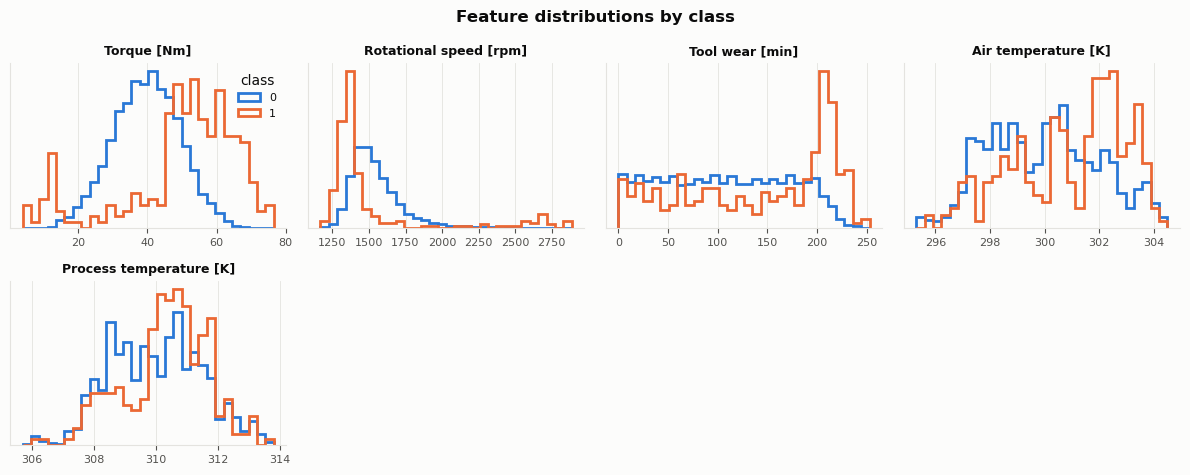

#### Correlated features (glassbox stability)

8 features; pairs with |r| ≥ 0.95: 0


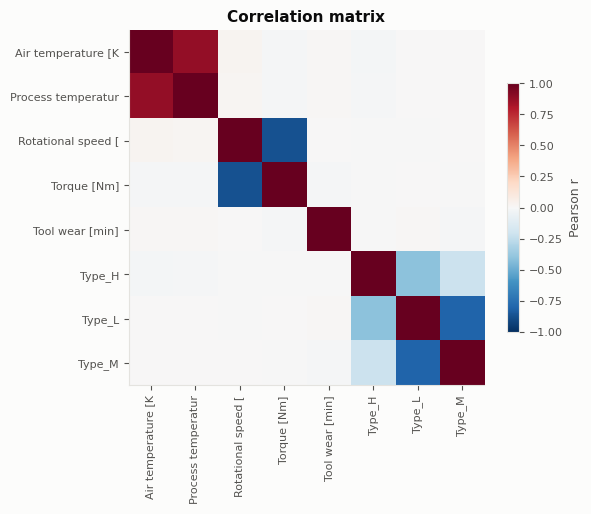

✅ No near-duplicate features.

In [9]:
if ai is not None:
    devA, testA = hold_out(ai, yA, DS)
    XA = make_X(ai, drop=[TARGET_A] + LEAK_A + info_A["id_like"])
    XA_dev, yA_dev = XA.iloc[devA], yA.iloc[devA]
    print("model features:", list(XA.columns))
    rankA = leakage_scan(XA_dev, yA_dev, DS)
    class_distributions(XA_dev, yA_dev, [c for c in rankA.index if not c.startswith("Type_")])
    correlation_check(XA_dev, DS)

**Known quirk: the failures were generated by physical rules.** In AI4I, heat-dissipation failure depends on (process − air temperature) and speed. Power failure depends on power = torque × angular speed, and overstrain depends on tool wear × torque. If you engineer these features, a model can almost reverse-engineer the generator. The cell below measures how strongly each one separates the classes on its own.

temp_diff_K     single-feature AUC = 0.662
power_W         single-feature AUC = 0.744
wear_x_torque   single-feature AUC = 0.692


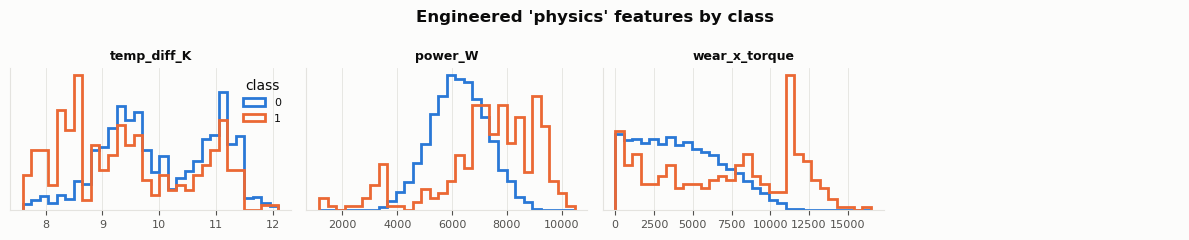

In [10]:
if ai is not None:
    eng = pd.DataFrame(index=XA_dev.index)
    eng["temp_diff_K"] = XA_dev["Process temperature [K]"] - XA_dev["Air temperature [K]"]
    eng["power_W"] = XA_dev["Torque [Nm]"] * XA_dev["Rotational speed [rpm]"] * 2 * np.pi / 60
    eng["wear_x_torque"] = XA_dev["Tool wear [min]"] * XA_dev["Torque [Nm]"]
    for c in eng:
        a = roc_auc_score(yA_dev, eng[c]); print(f"{c:15s} single-feature AUC = {max(a, 1 - a):.3f}")
    class_distributions(eng, yA_dev, eng.columns, title="Engineered 'physics' features by class")

In [11]:
if ai is not None:
    resA = baseline_check(XA_dev, yA_dev, DS)
    probeA = difficulty_probe(XA_dev, yA_dev, rankA)
    interpretability_note(DS, True, "Named physical features (torque, speed, tool wear, temperatures) give SHAP a clear story.")

#### Difficulty check: untuned 5-fold CV AUC (development split)

glassbox: logistic regression    AUC = 0.894 ± 0.017   (2.2s)
blackbox: gradient boosting      AUC = 0.970 ± 0.017   (1.2s)


✅ Room to compare models (best AUC 0.970).

blackbox − glassbox AUC gap: +0.076 (a positive gap gives you an interpretability-vs-performance story)


#### Difficulty probe: GBM AUC after dropping the k strongest single features

,k dropped,dropped,GBM CV AUC
0,0,—,0.970
1,1,Torque [Nm],0.920
2,2,"Torque [Nm], Rotational speed [rpm]",0.745
3,3,"Torque [Nm], Rotational speed [rpm], Tool wear...",0.650


#### Interpretability readiness (for SHAP)

✅ Named physical features (torque, speed, tool wear, temperatures) give SHAP a clear story.

**Business-loss angle for the slides:** a missed failure (FN) means unplanned downtime and scrap, while a false alarm (FP) means an unnecessary inspection. Set something like cost(FN) = 10–20 × cost(FP) and justify the ratio. The threshold that minimises this cost will be far below 0.5.

#### A · extra checks
**Glassbox with physics features.** If the engineered features from above let logistic regression close most of the gap to gradient boosting, that's a strong interpretability-vs-performance slide: a domain-informed glassbox nearly matches the blackbox. The engineered columns are computed from the inputs only, so there's no leakage.

**Review notes:**
- The UCI page describes AI4I 2020 as a **synthetic** dataset, generated from the physical rules above. Say so on the slides, and expect the question "so your model just learned the generator?".
- 27 rows have contradictory labels (9 failures with "No Failure", 18 "Random Failures" with Target 0). Decide whether to keep or drop them, and keep that decision fixed before tuning.
- This dataset has many public Kaggle notebooks, so the copy risk is high. Own the cost story and the feature deletions.

with physics features  glassbox: logistic regression    AUC = 0.914 ± 0.016
with physics features  blackbox: gradient boosting      AUC = 0.976 ± 0.013


#### Train loss: L2 vs surrogate (5-fold out-of-fold AUC, development split)

,model,train loss,OOF AUC,"scores outside [0, 1]"
0,glassbox,L2,0.872,32.1%
1,glassbox,log loss,0.893,0.0%
2,blackbox,L2,0.925,36.5%
3,blackbox,log loss,0.969,0.0%


surrogate − L2 AUC: glassbox +0.020, blackbox +0.045


ℹ️ All four versions train without trouble. Small AUC differences are normal, because AUC only depends on the ranking. The L2 versions show their weakness in calibration and in scores outside [0, 1] (next check).

#### Calibration of the untuned models (out-of-fold, development split)

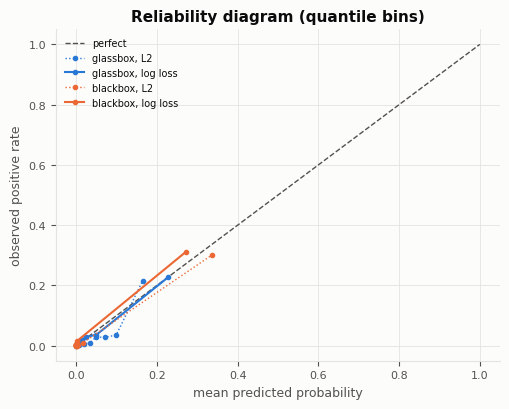

,model,train loss,Brier,ECE (10 bins),mean score
0,glassbox,L2,0.0281,0.0250,0.0440
1,glassbox,log loss,0.0238,0.0053,0.0339
2,blackbox,L2,0.0132,0.0073,0.0356
3,blackbox,log loss,0.0128,0.0071,0.0275
4,blackbox + Platt,log loss,0.0127,0.0023,0.0339


base rate in development split = 0.0339


⚠️ About 7 validation positives per calibration bin. The reliability diagram on validation alone will be noisy: use fewer bins, quantile bins, or out-of-fold predictions.

#### Validation noise: can a validation split of this size tell the models apart?

validation size ≈ 2,000 rows (68 positives)
blackbox AUC on a validation-sized split: 0.969 ± 0.022 (95% range)
blackbox − glassbox gap: +0.077, sd 0.015; blackbox wins in 100% of draws


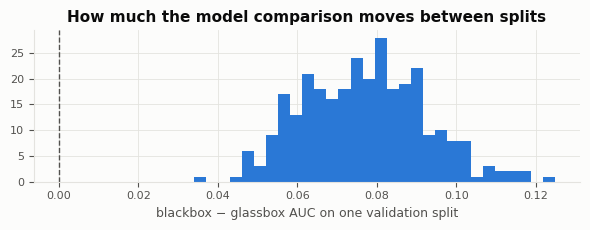

✅ The model comparison is stable at this validation size.

#### Evaluation loss: threshold that minimises expected cost (FN = 15, FP = 1)

*Cost story:* A missed failure (FN) means unplanned downtime and scrap; a false alarm (FP) means one unnecessary inspection. Assume FN costs 15× FP.

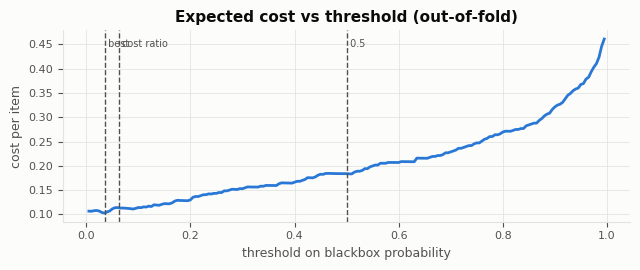

best threshold = 0.035 (cost 0.1026/item); threshold 0.5 costs 0.1837/item -> saving 44%
for a calibrated model the cost-ratio threshold would be 0.062; flag-nothing costs 0.5081, flag-everything costs 0.9661


✅ The evaluation loss moves the decision a lot away from 0.5, which gives the threshold slide something to say.

#### Tree SHAP smoke test (blackbox gradient boosting, development split)

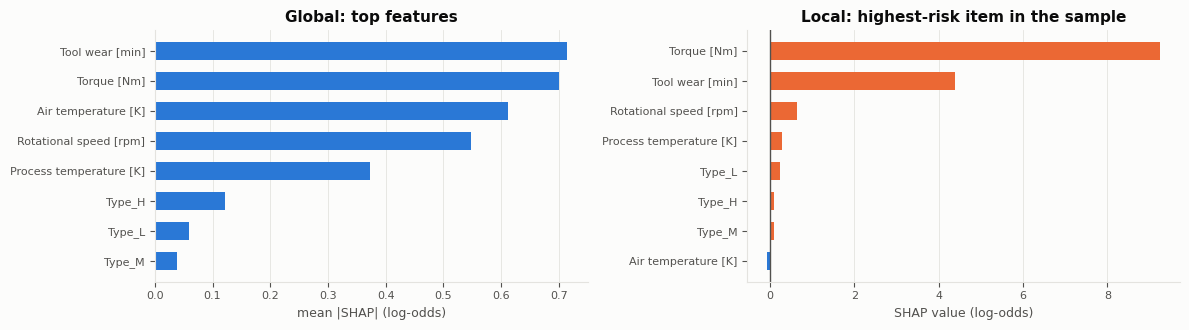

top feature `Tool wear [min]` carries 23% of total mean |SHAP|; rank agreement with single-feature AUC (Spearman) = 0.81


✅ Tree SHAP runs, and attributions are spread over several features: enough material for local and global plots.

In [12]:
if ai is not None:
    DS = "A · AI4I"
    XA_phys = XA_dev.assign(temp_diff_K=eng["temp_diff_K"], power_W=eng["power_W"], wear_x_torque=eng["wear_x_torque"])
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    for name, m in _models().items():
        s = cross_val_score(m, XA_phys, yA_dev, cv=cv, scoring="roc_auc", n_jobs=-1)
        print(f"with physics features  {name:32s} AUC = {s.mean():.3f} ± {s.std():.3f}")
    S_A = extended_checks(XA_dev, yA_dev, DS, rankA, c_fn=15, c_fp=1,
                          story="A missed failure (FN) means unplanned downtime and scrap; a false alarm (FP) means one unnecessary inspection. Assume FN costs 15× FP.")

---
## B. Semiconductor Wafer Defect Classification (synthetic)
Each row is one wafer with process-sensor readings and a pass/fail (defect) label. The dataset is synthetic, which the instructor's rules allow. I couldn't see the file's column names in advance, so the **target column is auto-detected**. If the guess is wrong, set `TARGET_B` by hand.

In [13]:
DS = "B · Synthetic wafer"
TARGET_B = None          # e.g. "Defect"; None = auto-detect
POSITIVE_B = None        # e.g. "Fail" or 1; None = auto ('fail/defect/1' label, else minority class)
try:
    root = get_dataset_dir("synth")
    files = find_files(root)
    print("CSV files found:", [os.path.basename(p) for p in files])
    f = files[0]
    sw = pd.read_csv(f)
    if TARGET_B is None:
        cands = [c for c in sw.columns if re.search(r"(defect|label|class|target|fail|pass|status|quality|result)", c, re.I)
                 and sw[c].nunique() == 2]
        TARGET_B = cands[0] if cands else [c for c in sw.columns if sw[c].nunique() == 2][-1]
    print(f"target column → {TARGET_B!r}   values: {sw[TARGET_B].value_counts().to_dict()}")
    overview(sw, DS, file_mb=os.path.getsize(f) / 1e6)
except Exception as e:
    sw = None; print("Synthetic wafer dataset not loaded:", repr(e))

CSV files found: ['semiconductor_wafer_defect_dataset.csv']
target column → 'defect_label'   values: {0: 4993, 1: 7}


#### Size and structure

rows=5,000  columns=9  in-memory=0.6 MB  file=0.6 MB
dtypes: {'float64': 6, 'int64': 2, 'object': 1}


,wafer_id,temperature_c,pressure_torr,gas_flow_sccm,etch_rate_nm_min,voltage_v,current_ma,process_step,defect_label
0,1,457.450712,747.287210,113.215053,93.852614,5.139314,20.341747,Deposition,0
1,2,447.926035,746.397577,116.945005,94.738753,5.113329,20.024511,Lithography,0
2,3,459.715328,706.130705,114.026189,95.514359,4.625392,19.137690,Deposition,0
3,4,472.845448,750.097294,121.104180,102.574892,5.231834,19.994947,Deposition,0
4,5,446.487699,781.984872,131.971785,89.022262,4.403967,20.981683,Deposition,0


✅ Size is fine (5,000 rows).

#### Missing data

missing cells: 0 (0.00%); columns with any missing: 0/9


✅ No meaningful missing data.

#### Data-cleaning load

,check,count
0,exact duplicate rows,0
1,duplicate feature rows,0
2,…of which with conflicting labels,0
3,constant columns,0
4,near-constant columns (≥99% one value),0
5,duplicate columns,0
6,ID-like columns,1
7,categorical/text columns,1
8,binary columns,0


ID-like (drop before modelling): ['wafer_id']
categorical: {'process_step': 5} (unique values)


✅ Little cleaning needed beyond dropping IDs.

positive class = 1


#### Class balance

positives=7 / 5,000  rate=0.14%  imbalance ratio ≈ 1:713
expected positives: validation≈1, test≈1; per calibration bin (10 bins)≈0


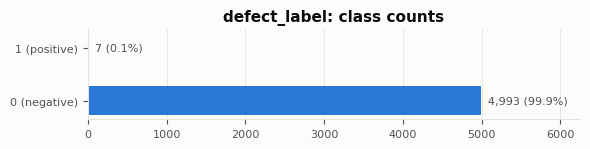

❌ Severe imbalance. The slides say to avoid this.

⚠️ About 1 positives in validation: AUC, threshold and calibration estimates will be noisy. Keep the grids small and consider CV.

In [14]:
if sw is not None:
    missing_report(sw, DS)
    info_B = cleaning_report(sw, TARGET_B, DS)
    yB, posB = to_binary(sw[TARGET_B], positive=POSITIVE_B)
    print("positive class =", posB)
    target_report(yB, DS, label=TARGET_B)

Held out test: 1,000 rows (1 positives). Development split for label-driven checks: 4,000 rows.
model features (11): ['temperature_c', 'pressure_torr', 'gas_flow_sccm', 'etch_rate_nm_min', 'voltage_v', 'current_ma', 'process_step_CMP', 'process_step_Deposition', 'process_step_Etching', 'process_step_Lithography', 'process_step_Oxidation']


#### Leakage scan: single-feature AUC (development split)

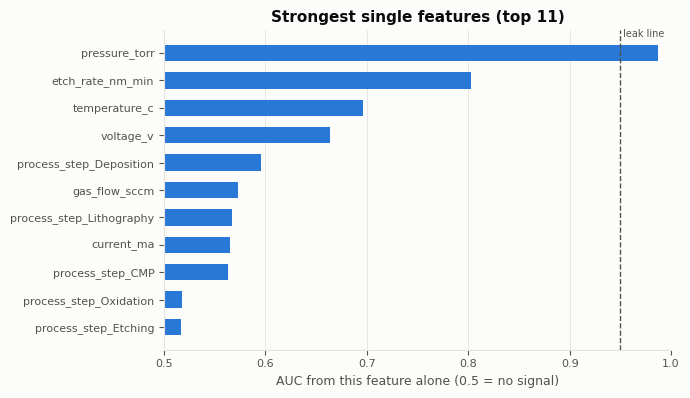

❌ Leakage suspects (AUC ≥ 0.95): ['pressure_torr']. Drop them, or explain why they're legitimate.

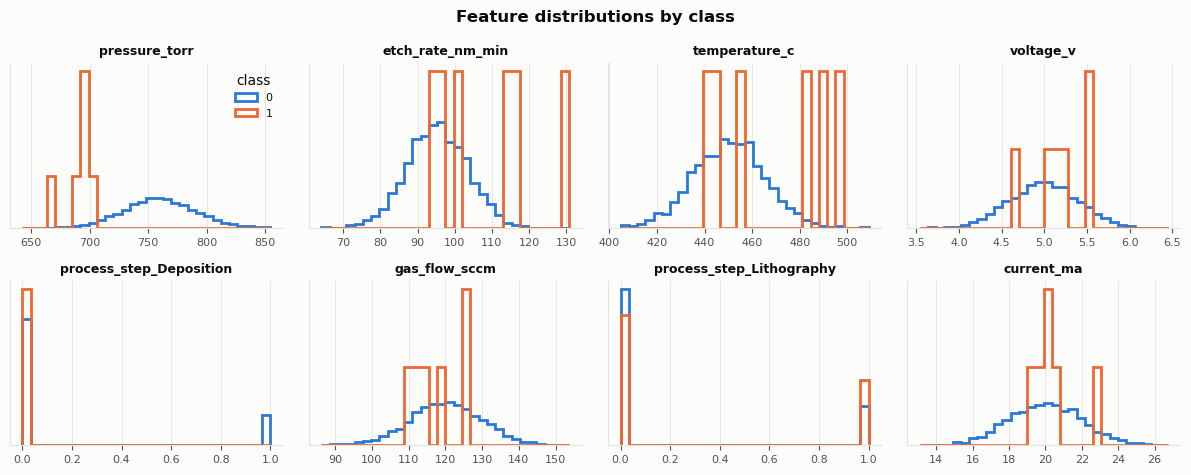

#### Correlated features (glassbox stability)

11 features; pairs with |r| ≥ 0.95: 0


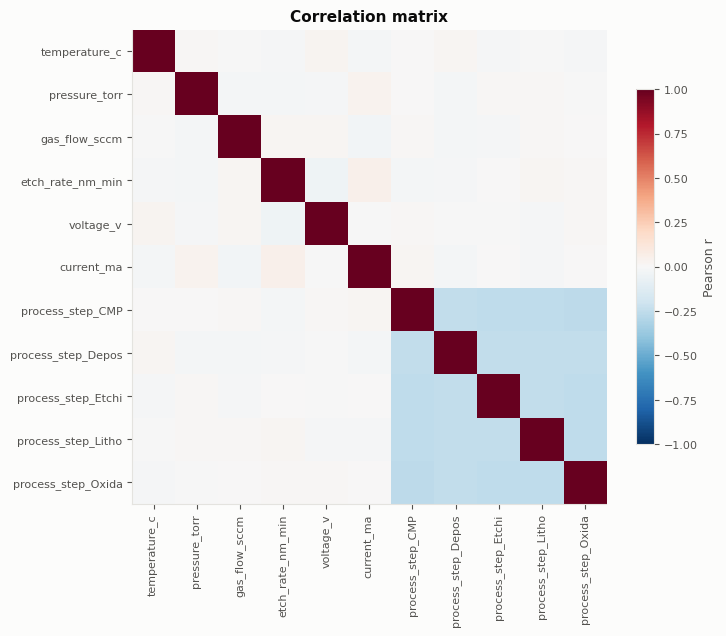

✅ No near-duplicate features.

In [15]:
if sw is not None:
    devB, testB = hold_out(sw, yB, DS)
    XB = make_X(sw, drop=[TARGET_B] + info_B["id_like"])
    XB_dev, yB_dev = XB.iloc[devB], yB.iloc[devB]
    print(f"model features ({XB.shape[1]}):", list(XB.columns)[:30])
    rankB = leakage_scan(XB_dev, yB_dev, DS)
    class_distributions(XB_dev, yB_dev, rankB.index)
    correlation_check(XB_dev, DS)

In [16]:
if sw is not None:
    resB = baseline_check(XB_dev, yB_dev, DS)
    probeB = difficulty_probe(XB_dev, yB_dev, rankB)
    interpretability_note(DS, True, "Named process sensors (if the columns are meaningful). Check whether SHAP rankings look physically plausible, because synthetic generators sometimes aren't.")

#### Difficulty check: untuned 5-fold CV AUC (development split)

glassbox: logistic regression    AUC = 0.988 ± 0.013   (0.2s)
blackbox: gradient boosting      AUC = 0.791 ± 0.392   (0.2s)


⚠️ Almost perfect (AUC 0.988). The slides say to delete some features to make it harder. See the difficulty probe.

blackbox − glassbox AUC gap: -0.197 (a positive gap gives you an interpretability-vs-performance story)


#### Difficulty probe: GBM AUC after dropping the k strongest single features

,k dropped,dropped,GBM CV AUC
0,0,—,0.791
1,1,pressure_torr,0.889
2,2,"pressure_torr, etch_rate_nm_min",0.674
3,3,"pressure_torr, etch_rate_nm_min, temperature_c",0.443


#### Interpretability readiness (for SHAP)

✅ Named process sensors (if the columns are meaningful). Check whether SHAP rankings look physically plausible, because synthetic generators sometimes aren't.

**What to watch with synthetic data:**
- A baseline AUC near 1.0 usually means the label was generated from one or two features. Use the difficulty probe and drop those features.
- If the class distributions are identical Gaussians, the AUC will be near 0.5 and the model comparison is noise.
- Either way, explain how predictions would be used in a fab (scrap vs re-inspect) to set your evaluation loss.

#### B · review verdict: excluded
With **7 positives in 5,000 rows**, the leakage flag (pressure AUC 0.987), the "glassbox beats blackbox" result (0.988 vs 0.791 ± 0.392) and the difficulty probe are all artefacts of having about 1 positive per fold. Validation would hold about 1 positive, so validation AUC, threshold tuning and calibration can't be estimated. The extra checks are skipped for B, and B shouldn't be used for Project 2.

---
## C. Detecting Anomalies in Wafer Manufacturing (MachineHack #18)
`Train.csv` has 1,558 anonymised features (`feature_1` … `feature_1558`) and `Class` (1 = anomalous). `Test.csv` has **no labels**, so only `Train.csv` is usable for Project 2.

In [17]:
DS = "C · MachineHack wafer"
try:
    root = get_dataset_dir("mh")
    print("files:", [os.path.basename(p) for p in find_files(root)])
    f = find_files(root, must=r"train")[0]
    mh = pd.read_csv(f)
    TARGET_C = "Class" if "Class" in mh.columns else mh.columns[-1]
    overview(mh, DS, file_mb=os.path.getsize(f) / 1e6)
except Exception as e:
    mh = None; print("MachineHack dataset not loaded:", repr(e))

files: ['Train.csv', 'Test.csv', 'Sample_submission.csv']


#### Size and structure

rows=1,763  columns=1,559  in-memory=22.0 MB  file=5.5 MB
dtypes: {'int64': 1558, 'float64': 1}


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,feature_20,...,feature_1540,feature_1541,feature_1542,feature_1543,feature_1544,feature_1545,feature_1546,feature_1547,feature_1548,feature_1549,feature_1550,feature_1551,feature_1552,feature_1553,feature_1554,feature_1555,feature_1556,feature_1557,feature_1558,Class
0,100,160,1.6000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,20,83,4.1500,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
2,99,150,1.5151,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,40,40,1.0000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,...,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,12,234,19.5000,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


✅ Size is fine (1,763 rows).

#### Missing data

missing cells: 0 (0.00%); columns with any missing: 0/1559


✅ No meaningful missing data.

#### Data-cleaning load

,check,count
0,exact duplicate rows,48
1,duplicate feature rows,60
2,…of which with conflicting labels,12
3,constant columns,36
4,near-constant columns (≥99% one value),1304
5,duplicate columns,829
6,ID-like columns,0
7,categorical/text columns,0
8,binary columns,1519


❌ Substantial cleaning needed (see table).

#### Class balance

positives=143 / 1,763  rate=8.11%  imbalance ratio ≈ 1:11
expected positives: validation≈29, test≈29; per calibration bin (10 bins)≈3


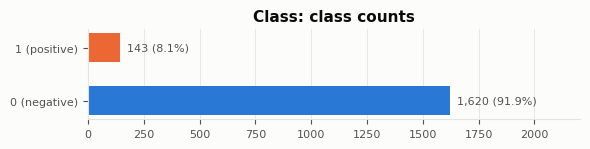

⚠️ Moderate imbalance. Use a stratified split, report AUC, and tune the threshold.

⚠️ About 29 positives in validation: AUC, threshold and calibration estimates will be noisy. Keep the grids small and consider CV.

In [18]:
if mh is not None:
    missing_report(mh, DS)
    info_C = cleaning_report(mh, TARGET_C, DS)
    yC, _ = to_binary(mh[TARGET_C], positive=1)
    target_report(yC, DS, label=TARGET_C)

**High-dimensional checks:** what the features look like (binary or continuous, how sparse), and how many features there are per row. When p ≫ n, an unregularised glassbox overfits, and SHAP on anonymous columns can't support a business story.

features=1558, rows=1763, features per row = 0.88
binary 0/1 features: 1555; non-binary: ['feature_1', 'feature_2', 'feature_3']


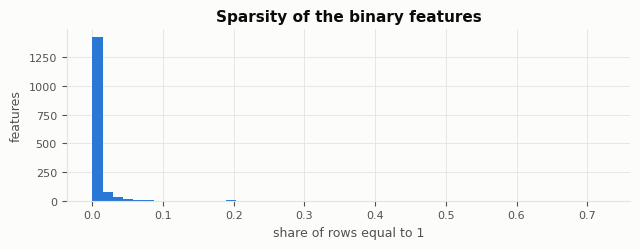

median share of ones = 0.005; features with <1% ones: 1340


In [19]:
if mh is not None:
    XC_all = mh.drop(columns=[TARGET_C])
    nun = XC_all.nunique()
    is_bin = XC_all.isin([0, 1]).all()
    print(f"features={XC_all.shape[1]}, rows={len(mh)}, features per row = {XC_all.shape[1] / len(mh):.2f}")
    print(f"binary 0/1 features: {int(is_bin.sum())}; non-binary: {list(XC_all.columns[~is_bin])[:10]}")
    ones = XC_all.loc[:, is_bin].mean()
    fig, ax = plt.subplots(figsize=(6.5, 2.6))
    ax.hist(ones, bins=50, color=C0); ax.set_xlabel("share of rows equal to 1")
    ax.set_ylabel("features"); ax.set_title("Sparsity of the binary features"); plt.tight_layout(); plt.show()
    print(f"median share of ones = {ones.median():.3f}; features with <1% ones: {(ones < 0.01).sum()}")
    record(DS, features_per_row=round(XC_all.shape[1] / len(mh), 2))

Held out test: 353 rows (29 positives). Development split for label-driven checks: 1,410 rows.
after dropping constant + duplicate columns: 728 features


#### Leakage scan: single-feature AUC (development split)

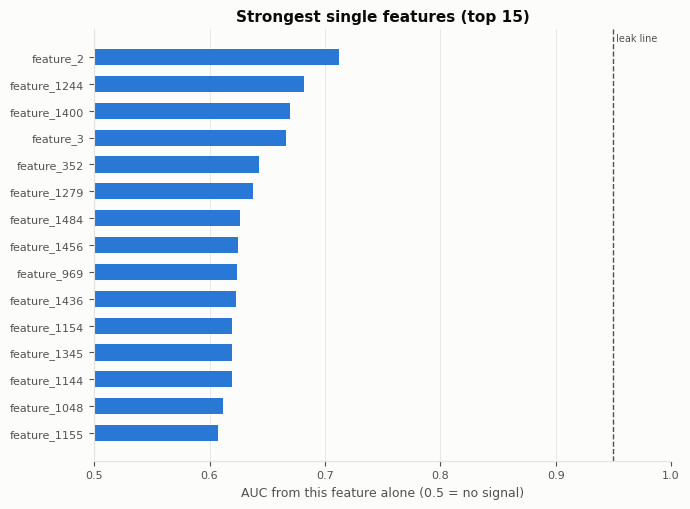

✅ No single feature is suspiciously predictive (max AUC 0.712, from `feature_2`).

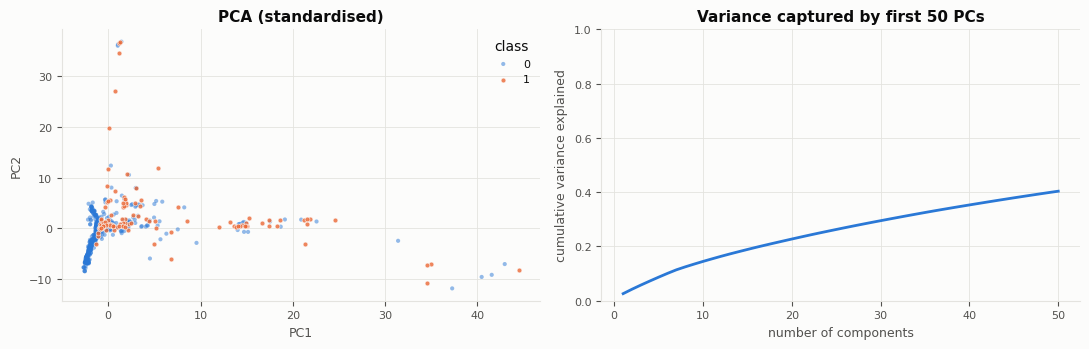

First 2 PCs explain 4.2%; first 50 explain 40.4%.


#### Correlated features (glassbox stability)

728 features; pairs with |r| ≥ 0.95: 69


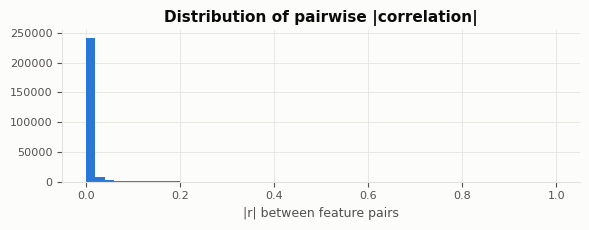

,feature_a,feature_b,|r|
0,feature_34,feature_789,0.960425
1,feature_35,feature_235,0.982836
2,feature_46,feature_77,1.000000
3,feature_48,feature_647,0.976657
4,feature_48,feature_1001,1.000000
5,feature_55,feature_1350,1.000000
6,feature_66,feature_1237,1.000000
7,feature_84,feature_966,1.000000
8,feature_85,feature_111,0.957085
9,feature_85,feature_1040,1.000000


⚠️ 69 highly correlated pairs. Use LASSO or a ridge penalty, or drop one of each pair, before reading glassbox coefficients.

In [20]:
if mh is not None:
    devC, testC = hold_out(mh, yC, DS)
    drop_C = [TARGET_C] + info_C["constant"] + info_C["dup_cols"]
    XC = make_X(mh, drop=drop_C)
    print(f"after dropping constant + duplicate columns: {XC.shape[1]} features")
    XC_dev, yC_dev = XC.iloc[devC], yC.iloc[devC]
    rankC = leakage_scan(XC_dev, yC_dev, DS)
    pca_view(XC_dev, yC_dev)
    correlation_check(XC_dev, DS)

In [21]:
if mh is not None:
    resC = baseline_check(XC_dev, yC_dev, DS)
    probeC = difficulty_probe(XC_dev, yC_dev, rankC)
    interpretability_note(DS, False, "The features are anonymous (`feature_1043`). Local and global SHAP plots can't be tied to a cause, which is weak for the interpretability part of the presentation.")

#### Difficulty check: untuned 5-fold CV AUC (development split)

glassbox: logistic regression    AUC = 0.820 ± 0.056   (0.5s)
blackbox: gradient boosting      AUC = 0.898 ± 0.048   (9.6s)


✅ Room to compare models (best AUC 0.898).

blackbox − glassbox AUC gap: +0.078 (a positive gap gives you an interpretability-vs-performance story)


#### Difficulty probe: GBM AUC after dropping the k strongest single features

,k dropped,dropped,GBM CV AUC
0,0,—,0.898
1,1,feature_2,0.897
2,2,"feature_2, feature_1244",0.898
3,3,"feature_2, feature_1244, feature_1400",0.894


#### Interpretability readiness (for SHAP)

❌ The features are anonymous (`feature_1043`). Local and global SHAP plots can't be tied to a cause, which is weak for the interpretability part of the presentation.

#### C · extra checks
Runs the extra checks on the 728 de-duplicated features. Expect the validation-noise check to be the weak point: about 29 validation positives.

#### Train loss: L2 vs surrogate (5-fold out-of-fold AUC, development split)

,model,train loss,OOF AUC,"scores outside [0, 1]"
0,glassbox,L2,0.755,47.1%
1,glassbox,log loss,0.815,0.0%
2,blackbox,L2,0.878,42.9%
3,blackbox,log loss,0.887,0.0%


surrogate − L2 AUC: glassbox +0.060, blackbox +0.009


ℹ️ All four versions train without trouble. Small AUC differences are normal, because AUC only depends on the ranking. The L2 versions show their weakness in calibration and in scores outside [0, 1] (next check).

#### Calibration of the untuned models (out-of-fold, development split)

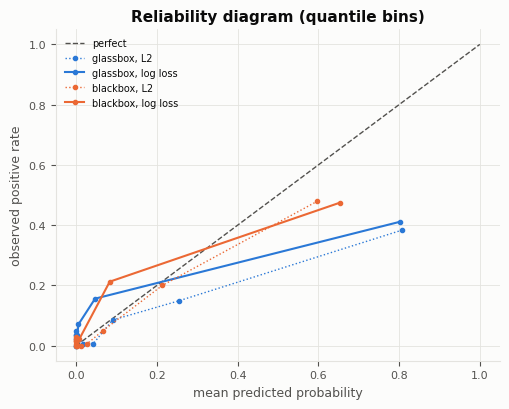

,model,train loss,Brier,ECE (10 bins),mean score
0,glassbox,L2,0.0818,0.0643,0.1214
1,glassbox,log loss,0.0814,0.0762,0.0858
2,blackbox,L2,0.0575,0.0235,0.0920
3,blackbox,log loss,0.0634,0.0519,0.0752
4,blackbox + Platt,log loss,0.0579,0.0368,0.0832


base rate in development split = 0.0809


⚠️ About 3 validation positives per calibration bin. The reliability diagram on validation alone will be noisy: use fewer bins, quantile bins, or out-of-fold predictions.

#### Validation noise: can a validation split of this size tell the models apart?

validation size ≈ 352 rows (28 positives)
blackbox AUC on a validation-sized split: 0.891 ± 0.058 (95% range)
blackbox − glassbox gap: +0.073, sd 0.039; blackbox wins in 99% of draws


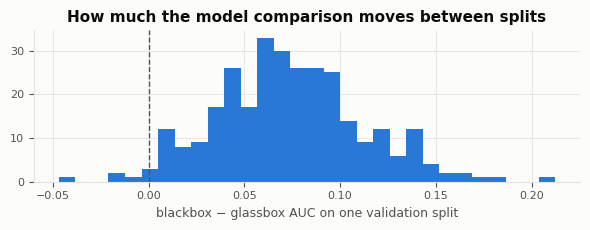

⚠️ A single validation split can't reliably separate glassbox and blackbox. Keep the search small, report the uncertainty, or use repeated CV for the decision.

#### Evaluation loss: threshold that minimises expected cost (FN = 10, FP = 1)

*Cost story:* An anomalous wafer that passes (FN) continues through costly downstream steps; a false flag (FP) costs one re-inspection.

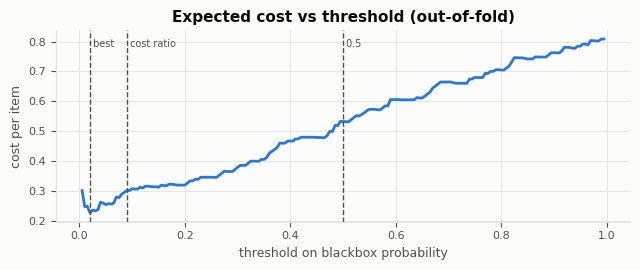

best threshold = 0.020 (cost 0.2255/item); threshold 0.5 costs 0.5319/item -> saving 58%
for a calibrated model the cost-ratio threshold would be 0.091; flag-nothing costs 0.8085, flag-everything costs 0.9191


✅ The evaluation loss moves the decision a lot away from 0.5, which gives the threshold slide something to say.

#### Tree SHAP smoke test (blackbox gradient boosting, development split)

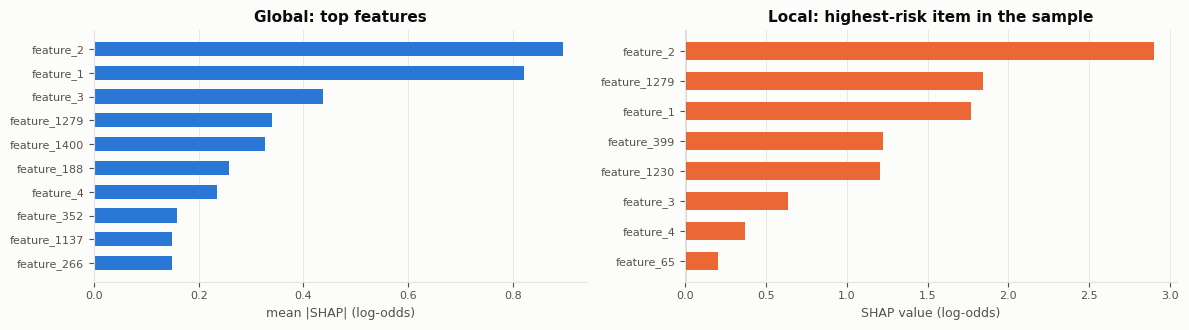

top feature `feature_2` carries 15% of total mean |SHAP|; rank agreement with single-feature AUC (Spearman) = 0.41


✅ Tree SHAP runs, and attributions are spread over several features: enough material for local and global plots.

In [22]:
if mh is not None:
    S_C = extended_checks(XC_dev, yC_dev, "C · MachineHack wafer", rankC, c_fn=10, c_fp=1,
                          story="An anomalous wafer that passes (FN) continues through costly downstream steps; a false flag (FP) costs one re-inspection.")

---
## D. WM-811K wafer maps (image data)
`LSWMD.pkl` is a pandas pickle with 811,457 wafer maps. Each `waferMap` is a 2-D array: 0 = no die, 1 = pass, 2 = fail. `failureType` has 8 defect patterns plus `none`, and most wafers are unlabelled.

Project 2 needs tabular models and tree SHAP on meaningful features. So this section:
1. checks label coverage, class imbalance and map sizes, and shows example maps
2. turns a **subsample** of maps into **10 named spatial features** (fail rate by zone, cluster size, angular concentration)
3. runs the same tabular checks on those features.

**Memory warning:** loading the full pickle needs several GB of RAM. The pickle was written by an old pandas version, so the loader tries several compatibility routes. If they all fail, load it in an environment with `pandas<2` and save it with `df.to_pickle()`.

In [23]:
DS = "D · WM-811K"
WM_SAMPLE = 20_000          # labelled wafers to turn into features (keeps the natural class ratio)
WM_POSITIVE = None          # None = any defect pattern vs 'none'; or e.g. ["Edge-Ring"]
WM_NEGATIVE = ["none"]      # e.g. ["Edge-Loc"] for an Edge-Ring vs Edge-Loc task

def load_lswmd(path):
    try:
        return pd.read_pickle(path)
    except Exception as e1:
        print("plain read_pickle failed:", repr(e1)[:120])
    import pandas.core.indexes as _idx
    sys.modules.setdefault("pandas.indexes", _idx)
    try:
        return pd.read_pickle(path)
    except Exception as e2:
        print("alias route failed:", repr(e2)[:120])
    class _Legacy(pickle.Unpickler):
        def find_class(self, module, name):
            if module.startswith("pandas.indexes"):
                module = "pandas.core.indexes" + module[len("pandas.indexes"):]
            if module == "pandas.core.indexes.numeric" or name in ("Int64Index", "UInt64Index", "Float64Index"):
                return pd.Index
            return super().find_class(module, name)
    with open(path, "rb") as fh:
        return _Legacy(fh, encoding="latin1").load()

def first_str(x, empty="unlabeled"):
    a = np.asarray(x, dtype=object).ravel()
    return str(a[0]).strip() if a.size else empty

try:
    root = get_dataset_dir("wm")
    f = find_files(root, exts=(".pkl",))[0]
    t = time.time(); wm = load_lswmd(f); print(f"loaded {f} in {time.time() - t:.0f}s")
    wm["label"] = wm["failureType"].map(first_str)
    wm["split"] = wm["trianTestLabel"].map(first_str)
    wm["shape"] = wm["waferMap"].map(lambda m: np.asarray(m).shape)
    overview(wm.drop(columns=["waferMap", "failureType", "trianTestLabel"]), DS, file_mb=os.path.getsize(f) / 1e6)
except Exception as e:
    wm = None; print("WM-811K not loaded:", repr(e))

loaded /Users/testuser/.cache/kagglehub/datasets/qingyi/wm811k-wafer-map/versions/1/LSWMD.pkl in 29s


#### Size and structure

rows=811,457  columns=6  in-memory=249.1 MB  file=2,095.5 MB
dtypes: {'object': 4, 'float64': 2}


,dieSize,lotName,waferIndex,label,split,shape
0,1683.0,lot1,1.0,none,Training,"(45, 48)"
1,1683.0,lot1,2.0,none,Training,"(45, 48)"
2,1683.0,lot1,3.0,none,Training,"(45, 48)"
3,1683.0,lot1,4.0,none,Training,"(45, 48)"
4,1683.0,lot1,5.0,none,Training,"(45, 48)"


❌ Large: 811,457 rows. You'd need to subsample.

#### Label coverage and class imbalance (all wafers)

labelled: 172,950 / 811,457 (21.3%)


,wafers,share_of_labelled
label,,
none,147431,0.8524
Edge-Ring,9680,0.0560
Edge-Loc,5189,0.0300
Center,4294,0.0248
Loc,3593,0.0208
Scratch,1193,0.0069
Random,866,0.0050
Donut,555,0.0032
Near-full,149,0.0009


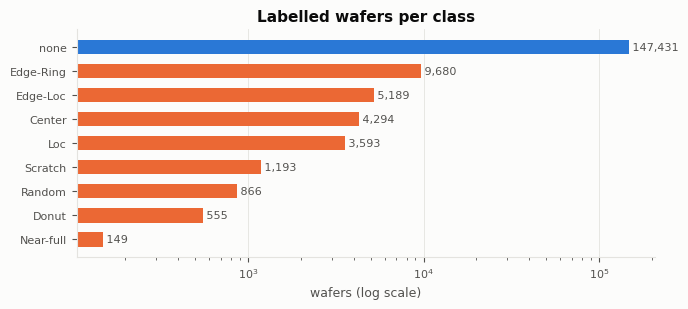

split,Test,Training
label,,
Center,832,3462
Donut,146,409
Edge-Loc,2772,2417
Edge-Ring,1126,8554
Loc,1973,1620
Near-full,95,54
Random,257,609
Scratch,693,500
none,110701,36730


❌ 'none' is 85% of labelled wafers, and the rarest pattern has 149 examples. Use a binary subset (pattern vs none, or one pattern vs another).

In [24]:
if wm is not None:
    header("Label coverage and class imbalance (all wafers)")
    vc = wm["label"].value_counts()
    labelled = wm["label"] != "unlabeled"
    print(f"labelled: {labelled.sum():,} / {len(wm):,} ({labelled.mean():.1%})")
    lab = vc.drop("unlabeled", errors="ignore")
    display((lab.to_frame("wafers").assign(share_of_labelled=lambda d: (d.wafers / d.wafers.sum()).round(4))))
    fig, ax = plt.subplots(figsize=(7, 3.2))
    order = lab.sort_values()
    ax.barh(order.index, order.values, color=[C1 if i != "none" else C0 for i in order.index], height=0.6)
    ax.set_xscale("log"); ax.set_xlabel("wafers (log scale)"); ax.set_title("Labelled wafers per class")
    for i, v in enumerate(order.values): ax.text(v, i, f" {v:,}", va="center", fontsize=8, color=INK2)
    ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()
    display(pd.crosstab(wm.loc[labelled, "label"], wm.loc[labelled, "split"]))
    smallest = lab.drop("none", errors="ignore").min()
    say("bad" if lab.get("none", 0) / lab.sum() > 0.8 else "warn",
        f"'none' is {lab.get('none', 0) / lab.sum():.0%} of labelled wafers, and the rarest pattern has {smallest:,} examples. Use a binary subset (pattern vs none, or one pattern vs another).")

#### Map sizes

distinct map shapes: 632; top 5: {(32, 29): 108687, (25, 27): 64083, (49, 39): 39323, (26, 26): 30078, (30, 34): 29513}


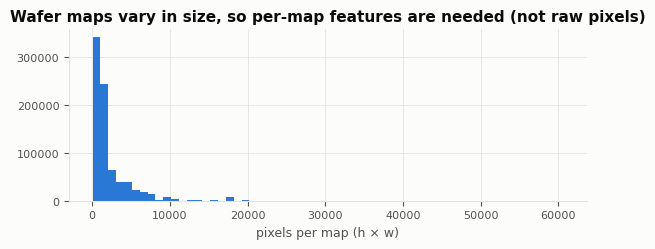

⚠️ 632 different map sizes. Raw pixels can't go into one table, which is another reason for engineered features.

In [25]:
if wm is not None:
    header("Map sizes")
    sh = wm["shape"].value_counts()
    print(f"distinct map shapes: {len(sh):,}; top 5:", sh.head(5).to_dict())
    dims = np.array(wm["shape"].tolist())
    fig, ax = plt.subplots(figsize=(6, 2.6))
    ax.hist(dims[:, 0] * dims[:, 1], bins=60, color=C0); ax.set_xlabel("pixels per map (h × w)")
    ax.set_title("Wafer maps vary in size, so per-map features are needed (not raw pixels)"); plt.tight_layout(); plt.show()
    say("warn", f"{len(sh):,} different map sizes. Raw pixels can't go into one table, which is another reason for engineered features.")

#### Example wafer maps per class

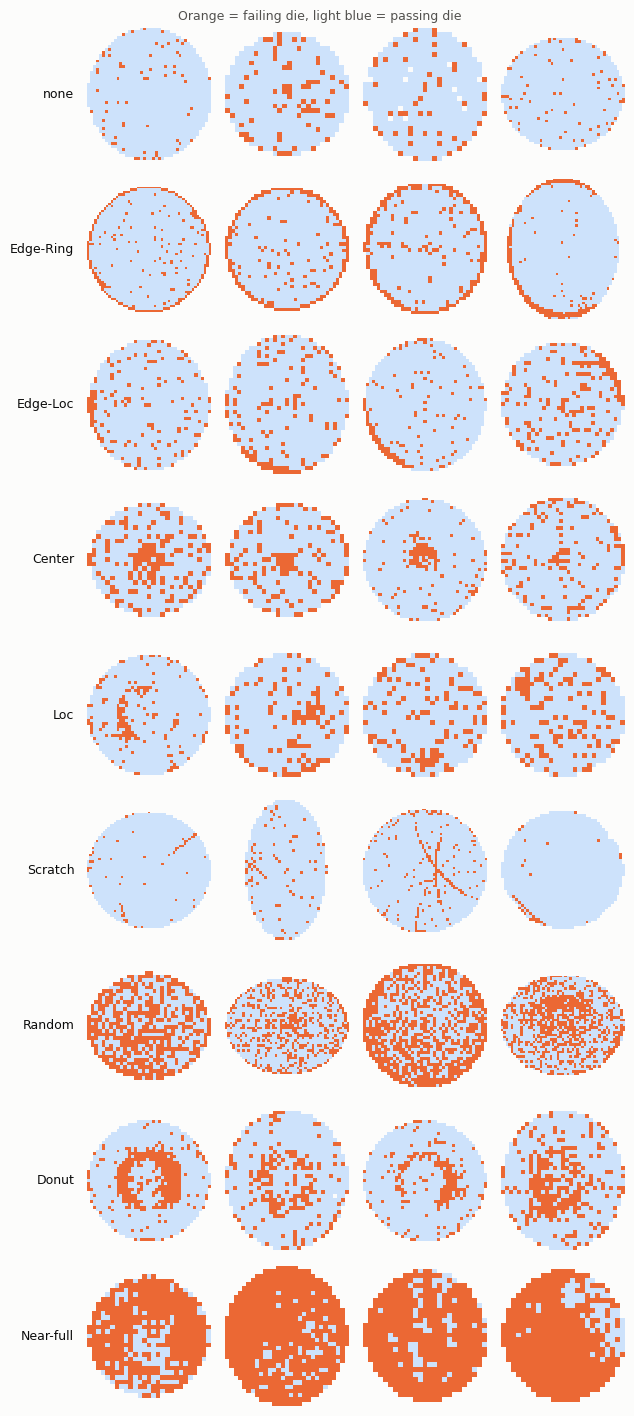

In [26]:
if wm is not None:
    header("Example wafer maps per class")
    cmap = ListedColormap(["#fcfcfb", "#cde2fb", C1])   # empty, pass die, fail die
    classes = [c for c in lab.index]
    k = 4
    fig, axes = plt.subplots(len(classes), k, figsize=(k * 1.6, len(classes) * 1.6))
    rng = np.random.default_rng(SEED)
    for r, c in enumerate(classes):
        idx = wm.index[wm["label"] == c]
        pick = rng.choice(idx, size=min(k, len(idx)), replace=False)
        for j in range(k):
            ax = axes[r, j]; ax.axis("off")
            if j < len(pick):
                ax.imshow(np.asarray(wm.at[pick[j], "waferMap"]), cmap=cmap, vmin=0, vmax=2, interpolation="nearest")
        axes[r, 0].text(-0.1, 0.5, c, transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=9)
    fig.suptitle("Orange = failing die, light blue = passing die", fontsize=9, color=INK2)
    plt.tight_layout(); plt.show()

### From image to table: 10 named spatial features per wafer
The radius is normalised so the outermost die is at r = 1. Zones are centre (r < 0.3), middle (0.3–0.7), edge (≥ 0.7) and outer ring (≥ 0.9). Clusters are 8-connected groups of failing dies. *Angular concentration* runs from 0 (failures spread all around, e.g. Edge-Ring) to 1 (failures on one side, e.g. Edge-Loc). Every feature has a physical meaning, so tree SHAP plots can be explained.

In [27]:
def wafer_features(m):
    m = np.asarray(m); die = m > 0; fail = m == 2
    n_die = int(die.sum())
    if n_die == 0: return None
    h, w = m.shape; yy, xx = np.indices(m.shape)
    cy, cx = yy[die].mean(), xx[die].mean()
    r = np.hypot(yy - cy, xx - cx); r = r / max(r[die].max(), 1e-9)
    def rate(zone):
        z = zone & die; return fail[z].sum() / z.sum() if z.sum() else 0.0
    lab_, n = ndimage.label(fail, structure=np.ones((3, 3)))
    if n:
        sizes = ndimage.sum(fail, lab_, range(1, n + 1)); big = int(np.argmax(sizes)) + 1
        largest = sizes.max() / n_die; big_r = r[lab_ == big].mean()
    else:
        largest, big_r = 0.0, np.nan
    th = np.arctan2(yy[fail] - cy, xx[fail] - cx)
    ang = float(np.abs(np.exp(1j * th).mean())) if fail.sum() else np.nan
    return dict(n_dies=n_die, fail_rate=fail.sum() / n_die, center_fail_rate=rate(r < 0.3),
                middle_fail_rate=rate((r >= 0.3) & (r < 0.7)), edge_fail_rate=rate(r >= 0.7),
                outer_ring_fail_rate=rate(r >= 0.9), n_fail_clusters=n, largest_cluster_share=largest,
                largest_cluster_radius=big_r, angular_concentration=ang)

if wm is not None:
    pos_set = WM_POSITIVE or [c for c in lab.index if c not in WM_NEGATIVE]
    keep = wm["label"].isin(list(pos_set) + list(WM_NEGATIVE))
    sub = wm.loc[keep, ["waferMap", "label"]]
    if len(sub) > WM_SAMPLE:
        sub = sub.groupby("label", group_keys=False).apply(lambda g: g.sample(frac=WM_SAMPLE / len(sub), random_state=SEED))
    t = time.time()
    feats = [wafer_features(m) for m in sub["waferMap"]]
    wmf = pd.DataFrame([f_ for f_ in feats if f_ is not None], index=sub.index[[f_ is not None for f_ in feats]])
    wmf["pattern"] = sub.loc[wmf.index, "label"].values
    wmf["target"] = wmf["pattern"].isin(pos_set).astype(int)
    print(f"built {len(wmf):,} feature rows in {time.time() - t:.0f}s. Positive = {pos_set}, negative = {WM_NEGATIVE}")
    display(wmf.groupby("pattern").mean(numeric_only=True).round(3))

built 19,999 feature rows in 3s. Positive = ['Edge-Ring', 'Edge-Loc', 'Center', 'Loc', 'Scratch', 'Random', 'Donut', 'Near-full'], negative = ['none']


,n_dies,fail_rate,center_fail_rate,middle_fail_rate,edge_fail_rate,outer_ring_fail_rate,n_fail_clusters,largest_cluster_share,largest_cluster_radius,angular_concentration,target
pattern,,,,,,,,,,,
Center,1007.606,0.230,0.565,0.174,0.216,0.372,49.125,0.089,0.229,0.085,1.0
Donut,1314.719,0.278,0.258,0.388,0.182,0.253,51.641,0.187,0.480,0.199,1.0
Edge-Loc,1124.757,0.186,0.130,0.126,0.258,0.392,55.268,0.077,0.836,0.241,1.0
Edge-Ring,2589.500,0.151,0.074,0.056,0.253,0.590,69.291,0.096,0.935,0.073,1.0
Loc,1392.508,0.145,0.167,0.136,0.148,0.213,46.424,0.059,0.591,0.294,1.0
Near-full,851.824,0.903,0.956,0.912,0.885,0.885,1.706,0.901,0.636,0.032,1.0
Random,1336.030,0.480,0.492,0.455,0.498,0.591,31.070,0.382,0.621,0.089,1.0
Scratch,2201.804,0.093,0.076,0.072,0.118,0.182,65.674,0.024,0.639,0.217,1.0
none,925.584,0.105,0.099,0.076,0.133,0.223,48.987,0.010,0.744,0.121,0.0


⚠️ Full data: 811,457 maps (large). Working subsample: 19,999 rows × 10 engineered features.

#### Missing data

missing cells: 0 (0.00%); columns with any missing: 0/12


✅ No meaningful missing data.

⚠️ Needs real preprocessing: legacy pickle, nested label arrays, variable map sizes, and feature extraction.

#### Class balance

positives=2,950 / 19,999  rate=14.75%  imbalance ratio ≈ 1:6
expected positives: validation≈590, test≈590; per calibration bin (10 bins)≈59


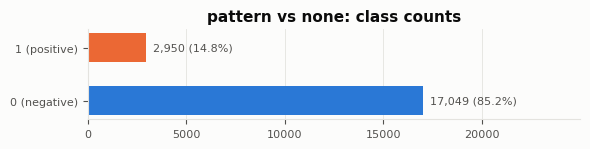

✅ Balance is fine.

✅ About 590 positives in validation.

In [28]:
if wm is not None:
    record(DS, rows=len(wm), columns=wmf.shape[1] - 2,
           size=say("warn", f"Full data: {len(wm):,} maps (large). Working subsample: {len(wmf):,} rows × {wmf.shape[1] - 2} engineered features."))
    missing_report(wmf, DS)
    record(DS, cleaning=say("warn", "Needs real preprocessing: legacy pickle, nested label arrays, variable map sizes, and feature extraction."))
    yD = wmf["target"]
    target_report(yD, DS, label="pattern vs none" if WM_POSITIVE is None else str(WM_POSITIVE))

Held out test: 4,000 rows (590 positives). Development split for label-driven checks: 15,999 rows.


#### Leakage scan: single-feature AUC (development split)

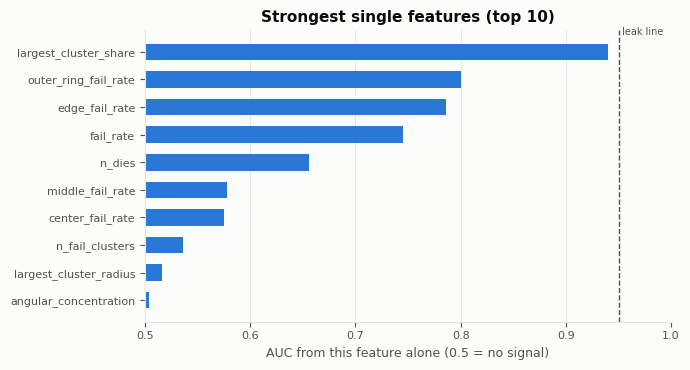

✅ No single feature is suspiciously predictive (max AUC 0.940, from `largest_cluster_share`).

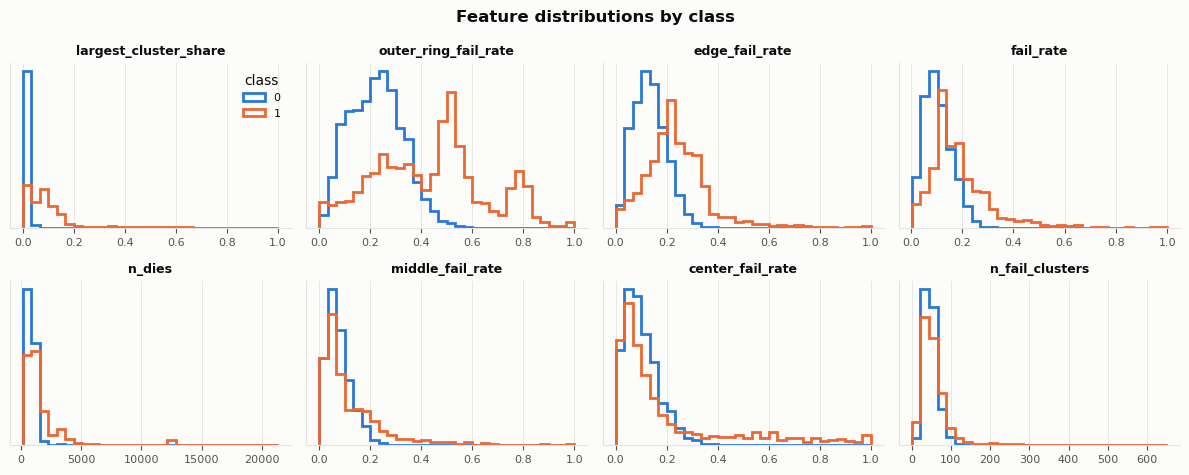

#### Correlated features (glassbox stability)

10 features; pairs with |r| ≥ 0.95: 0


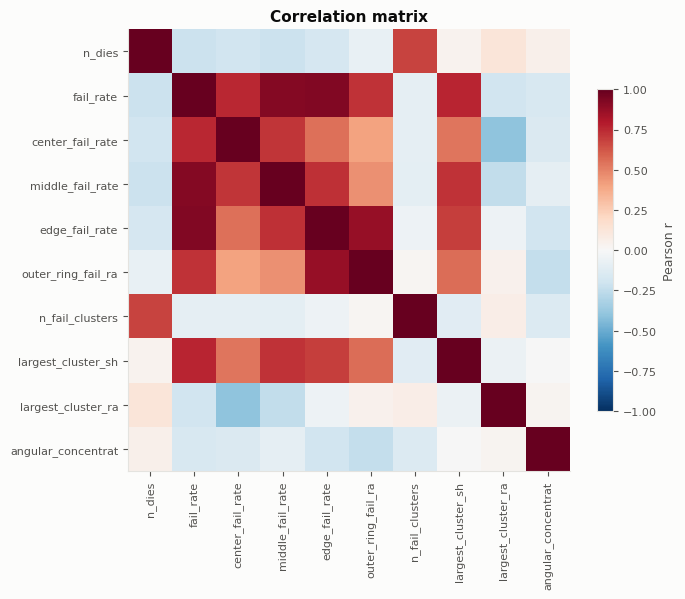

✅ No near-duplicate features.

#### Difficulty check: untuned 5-fold CV AUC (development split)

glassbox: logistic regression    AUC = 0.985 ± 0.004   (0.1s)
blackbox: gradient boosting      AUC = 0.995 ± 0.001   (0.3s)


⚠️ Almost perfect (AUC 0.995). The slides say to delete some features to make it harder. See the difficulty probe.

blackbox − glassbox AUC gap: +0.010 (a positive gap gives you an interpretability-vs-performance story)


#### Difficulty probe: GBM AUC after dropping the k strongest single features

,k dropped,dropped,GBM CV AUC
0,0,—,0.995
1,1,largest_cluster_share,0.981
2,2,"largest_cluster_share, outer_ring_fail_rate",0.980
3,3,"largest_cluster_share, outer_ring_fail_rate, e...",0.980


#### Interpretability readiness (for SHAP)

✅ The engineered spatial features (edge fail rate, cluster size, angular concentration) give SHAP plots a physical meaning, and they're relevant to Micron.

In [29]:
if wm is not None:
    devD, testD = hold_out(wmf, yD, DS)
    XD = make_X(wmf, drop=["target", "pattern"])
    XD_dev, yD_dev = XD.iloc[devD], yD.iloc[devD]
    rankD = leakage_scan(XD_dev, yD_dev, DS)
    class_distributions(XD_dev, yD_dev, rankD.index)
    correlation_check(XD_dev, DS)
    resD = baseline_check(XD_dev, yD_dev, DS)
    probeD = difficulty_probe(XD_dev, yD_dev, rankD)
    interpretability_note(DS, True, "The engineered spatial features (edge fail rate, cluster size, angular concentration) give SHAP plots a physical meaning, and they're relevant to Micron.")

#### D · extra checks, and a harder task
"Any pattern vs none" is almost perfect (GBM 0.995), and dropping the 3 strongest features barely moves it (0.980). Deleting features won't make this task hard enough. The slides' alternative is to **change the question**: a pairwise task between two patterns that look alike and have different root causes, e.g. **Loc vs Edge-Loc** (a local cluster in the interior vs at the edge). The prediction routes a wafer to the right engineering team, and misrouting costs are asymmetric.

The cell below builds the same 10 features for the pair in `WM_HARD` and reruns the difficulty and extra checks on it.

#### Train loss: L2 vs surrogate (5-fold out-of-fold AUC, development split)

,model,train loss,OOF AUC,"scores outside [0, 1]"
0,glassbox,L2,0.946,25.6%
1,glassbox,log loss,0.985,0.0%
2,blackbox,L2,0.992,35.3%
3,blackbox,log loss,0.995,0.0%


surrogate − L2 AUC: glassbox +0.038, blackbox +0.003


ℹ️ All four versions train without trouble. Small AUC differences are normal, because AUC only depends on the ranking. The L2 versions show their weakness in calibration and in scores outside [0, 1] (next check).

#### Calibration of the untuned models (out-of-fold, development split)

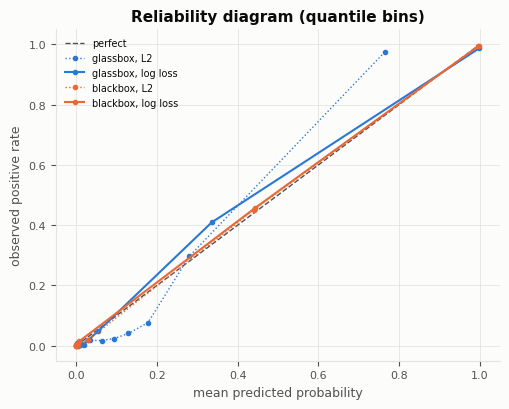

,model,train loss,Brier,ECE (10 bins),mean score
0,glassbox,L2,0.0504,0.0591,0.1550
1,glassbox,log loss,0.0272,0.0147,0.1475
2,blackbox,L2,0.0173,0.0041,0.1475
3,blackbox,log loss,0.0159,0.0059,0.1454
4,blackbox + Platt,log loss,0.0157,0.0024,0.1475


base rate in development split = 0.1475


✅ About 59 validation positives per calibration bin.

#### Validation noise: can a validation split of this size tell the models apart?

validation size ≈ 4,000 rows (590 positives)
blackbox AUC on a validation-sized split: 0.995 ± 0.002 (95% range)
blackbox − glassbox gap: +0.011, sd 0.002; blackbox wins in 100% of draws


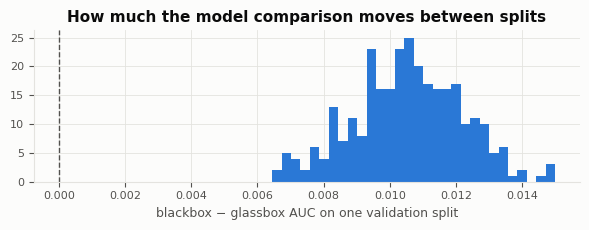

✅ The model comparison is stable at this validation size.

#### Evaluation loss: threshold that minimises expected cost (FN = 10, FP = 1)

*Cost story:* A defective-pattern wafer marked clean (FN) hides a process excursion; a clean wafer flagged (FP) costs one manual map review.

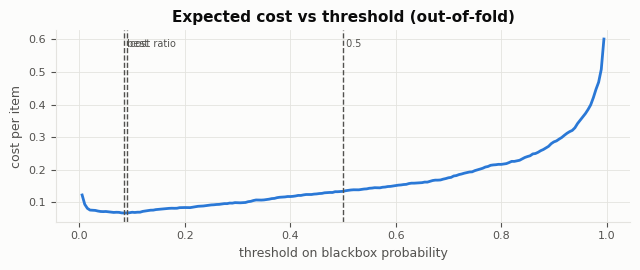

best threshold = 0.085 (cost 0.0674/item); threshold 0.5 costs 0.1339/item -> saving 50%
for a calibrated model the cost-ratio threshold would be 0.091; flag-nothing costs 1.4751, flag-everything costs 0.8525


✅ The evaluation loss moves the decision a lot away from 0.5, which gives the threshold slide something to say.

#### Tree SHAP smoke test (blackbox gradient boosting, development split)

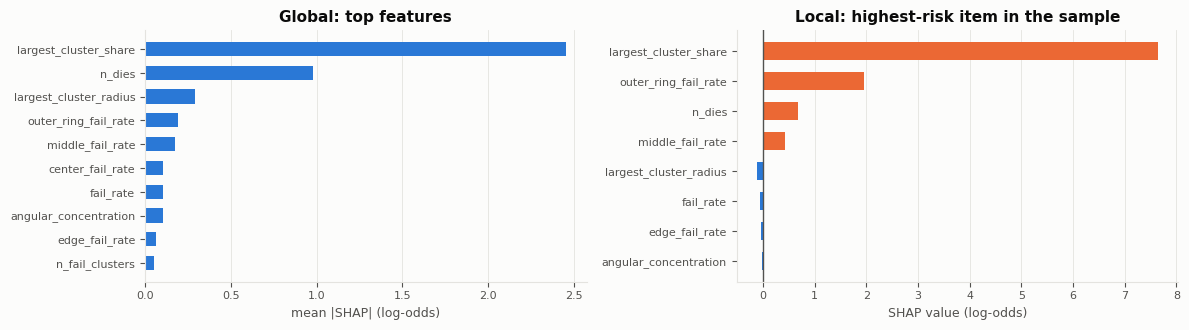

top feature `largest_cluster_share` carries 54% of total mean |SHAP|; rank agreement with single-feature AUC (Spearman) = 0.37


✅ Tree SHAP runs, and attributions are spread over several features: enough material for local and global plots.

#### Missing data

missing cells: 0 (0.00%); columns with any missing: 0/10


✅ No meaningful missing data.

#### Class balance

positives=5,189 / 8,782  rate=59.09%  imbalance ratio ≈ 1:1
expected positives: validation≈1038, test≈1038; per calibration bin (10 bins)≈104


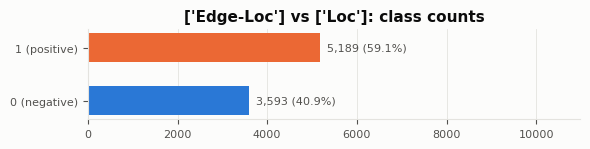

✅ Balance is fine.

✅ About 1038 positives in validation.

Held out test: 1,757 rows (1038 positives). Development split for label-driven checks: 7,025 rows.


#### Leakage scan: single-feature AUC (development split)

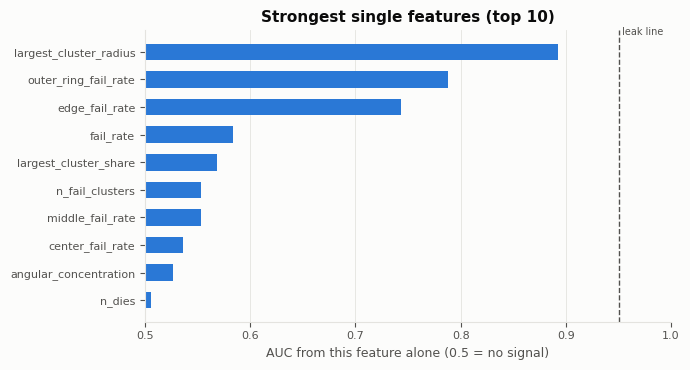

✅ No single feature is suspiciously predictive (max AUC 0.892, from `largest_cluster_radius`).

#### Correlated features (glassbox stability)

10 features; pairs with |r| ≥ 0.95: 0


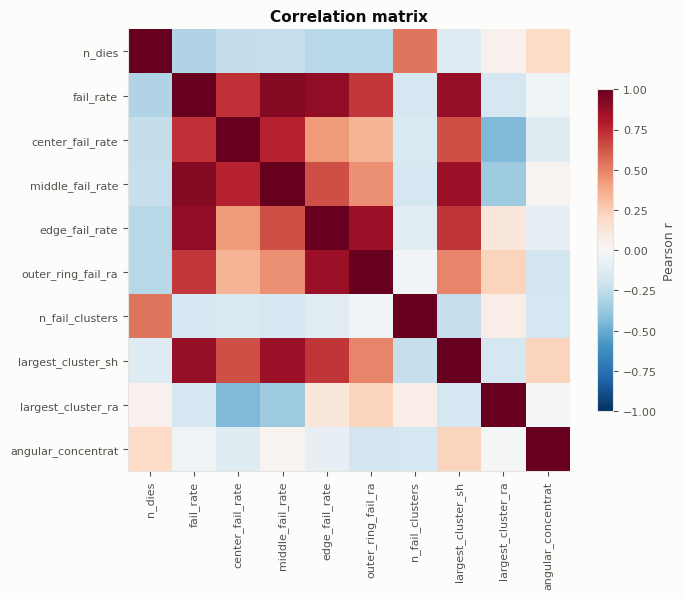

✅ No near-duplicate features.

#### Difficulty check: untuned 5-fold CV AUC (development split)

glassbox: logistic regression    AUC = 0.963 ± 0.006   (0.1s)
blackbox: gradient boosting      AUC = 0.974 ± 0.005   (0.3s)


✅ Room to compare models (best AUC 0.974).

blackbox − glassbox AUC gap: +0.011 (a positive gap gives you an interpretability-vs-performance story)


...

#### Train loss: L2 vs surrogate (5-fold out-of-fold AUC, development split)

,model,train loss,OOF AUC,"scores outside [0, 1]"
0,glassbox,L2,0.960,19.6%
1,glassbox,log loss,0.963,0.0%
2,blackbox,L2,0.971,29.0%
3,blackbox,log loss,0.974,0.0%


surrogate − L2 AUC: glassbox +0.003, blackbox +0.003


ℹ️ All four versions train without trouble. Small AUC differences are normal, because AUC only depends on the ranking. The L2 versions show their weakness in calibration and in scores outside [0, 1] (next check).

#### Calibration of the untuned models (out-of-fold, development split)

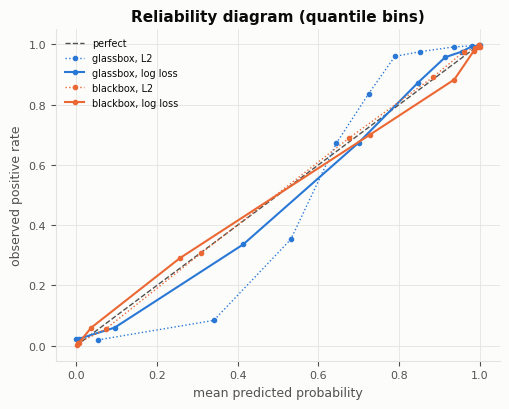

,model,train loss,Brier,ECE (10 bins),mean score
0,glassbox,L2,0.0932,0.1025,0.5927
1,glassbox,log loss,0.0719,0.0268,0.5909
2,blackbox,L2,0.0619,0.0077,0.5902
3,blackbox,log loss,0.0607,0.0157,0.5942
4,blackbox + Platt,log loss,0.0604,0.0086,0.5909


base rate in development split = 0.5909


✅ About 104 validation positives per calibration bin.

#### Validation noise: can a validation split of this size tell the models apart?

validation size ≈ 1,756 rows (1038 positives)
blackbox AUC on a validation-sized split: 0.974 ± 0.005 (95% range)
blackbox − glassbox gap: +0.011, sd 0.002; blackbox wins in 100% of draws


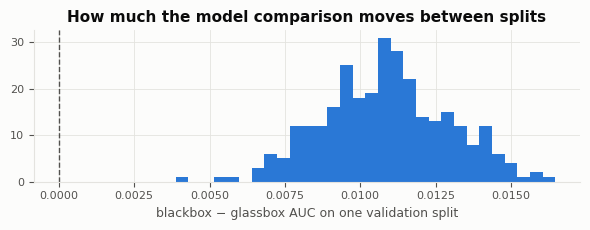

✅ The model comparison is stable at this validation size.

#### Evaluation loss: threshold that minimises expected cost (FN = 3, FP = 1)

*Cost story:* An Edge-Loc wafer sent to the interior-defect team (FN) delays the edge-process fix by a lot; the reverse misroute (FP) costs one hand-off.

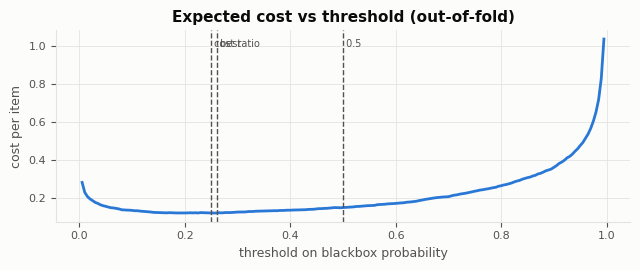

best threshold = 0.260 (cost 0.1220/item); threshold 0.5 costs 0.1507/item -> saving 19%
for a calibrated model the cost-ratio threshold would be 0.250; flag-nothing costs 1.7727, flag-everything costs 0.4091


✅ The evaluation loss moves the decision a lot away from 0.5, which gives the threshold slide something to say.

#### Tree SHAP smoke test (blackbox gradient boosting, development split)

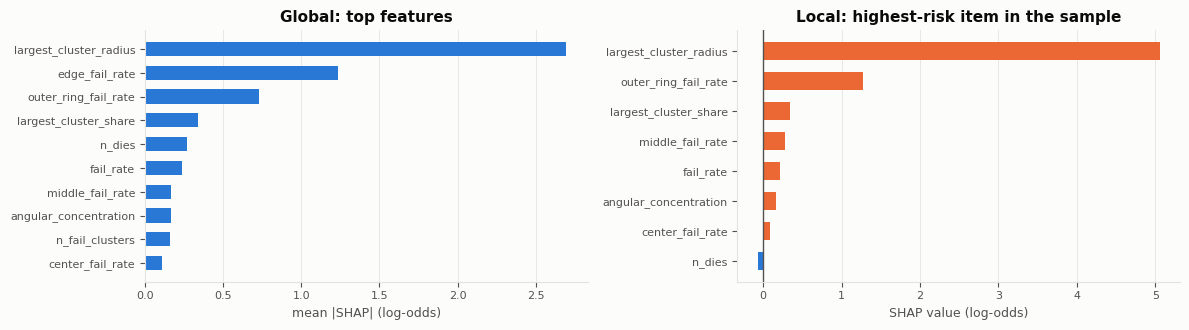

top feature `largest_cluster_radius` carries 44% of total mean |SHAP|; rank agreement with single-feature AUC (Spearman) = 0.72


✅ Tree SHAP runs, and attributions are spread over several features: enough material for local and global plots.

In [30]:
if wm is not None:
    S_D = extended_checks(XD_dev, yD_dev, "D · WM-811K", rankD, c_fn=10, c_fp=1,
                          story="A defective-pattern wafer marked clean (FN) hides a process excursion; a clean wafer flagged (FP) costs one manual map review.")

WM_HARD = (["Edge-Loc"], ["Loc"])   # (positive patterns, negative patterns)
if wm is not None:
    DSh = "D2 · WM-811K Edge-Loc vs Loc"
    subh = wm.loc[wm["label"].isin(WM_HARD[0] + WM_HARD[1]), ["waferMap", "label"]]
    fh = [wafer_features(m) for m in subh["waferMap"]]
    wmh = pd.DataFrame([f_ for f_ in fh if f_ is not None], index=subh.index[[f_ is not None for f_ in fh]])
    yH = subh.loc[wmh.index, "label"].isin(WM_HARD[0]).astype(int)
    record(DSh, rows=len(wmh), columns=wmh.shape[1], size="ok", cleaning="warn")
    missing_report(wmh, DSh)
    target_report(yH, DSh, label=f"{WM_HARD[0]} vs {WM_HARD[1]}")
    devH, testH = hold_out(wmh, yH, DSh)
    XH_dev, yH_dev = wmh.iloc[devH].astype(float), yH.iloc[devH]
    rankH = leakage_scan(XH_dev, yH_dev, DSh)
    correlation_check(XH_dev, DSh)
    baseline_check(XH_dev, yH_dev, DSh)
    difficulty_probe(XH_dev, yH_dev, rankH)
    interpretability_note(DSh, True, "Same named spatial features as D.")
    S_D2 = extended_checks(XH_dev, yH_dev, DSh, rankH, c_fn=3, c_fp=1,
                           story="An Edge-Loc wafer sent to the interior-defect team (FN) delays the edge-process fix by a lot; the reverse misroute (FP) costs one hand-off.")

---
## E. Steel Plates Faults (added in review)
Each row is one steel plate with a surface fault, described by 27 **named** geometric and luminosity features: position (`X_Minimum`, `Y_Maximum`, …), size (`Pixels_Areas`, `X_Perimeter`), brightness (`Sum_of_Luminosity`, `Luminosity_Index`), steel type (`TypeOfSteel_A300/A400`) and plate thickness. The original data has 1,941 rows, no missing values, and 7 one-hot fault columns: Pastry, Z_Scratch, K_Scatch, Stains, Dirtiness, Bumps, Other_Faults.

- **Binary target:** one fault type vs the rest, set in `STEEL_POSITIVE`. The cell first screens every fault type so you can pick one that is neither trivial nor hopeless. `K_Scatch` is known to be near-perfectly separable, so avoid it unless you plan to delete features.
- **Leakage:** all 7 fault columns are dropped from the features.
- **Why it's interesting:** it's real data (not synthetic), small, clean, with physically meaningful features, and a natural cost story (ship vs re-inspect a plate).
- `TypeOfSteel_A300` and `TypeOfSteel_A400` are complements, so drop one before reading glassbox coefficients.

In [31]:
DS = "E · Steel plates"
STEEL_FAULTS = ["Pastry", "Z_Scratch", "K_Scatch", "Stains", "Dirtiness", "Bumps", "Other_Faults"]
STEEL_POSITIVE = "Bumps"     # change after reading the per-fault screen below
try:
    root = get_dataset_dir("steel")
    f = find_files(root)[0]
    st = pd.read_csv(f); st.columns = [c.strip() for c in st.columns]
    print("loaded", f)
    missing_faults = [c for c in STEEL_FAULTS if c not in st.columns]
    assert not missing_faults, f"fault columns not found: {missing_faults}"
    overview(st, DS, file_mb=os.path.getsize(f) / 1e6)
except Exception as e:
    st = None; print("Steel plates not loaded:", repr(e))

if st is not None:
    header("Which fault to predict? One-vs-rest screen (development split)")
    fault = st[STEEL_FAULTS].values.argmax(1)
    print("rows with exactly one fault flag:", int((st[STEEL_FAULTS].sum(1) == 1).sum()), "of", len(st))
    dev_s, _ = train_test_split(np.arange(len(st)), test_size=TEST_SIZE, stratify=fault, random_state=SEED)
    Xs_all = st.drop(columns=STEEL_FAULTS).iloc[dev_s].astype(float)
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    rows = []
    for c in STEEL_FAULTS:
        yy = st[c].iloc[dev_s]
        a_g = cross_val_score(_models()["glassbox: logistic regression"], Xs_all, yy, cv=cv, scoring="roc_auc", n_jobs=-1).mean()
        a_b = cross_val_score(HistGradientBoostingClassifier(random_state=SEED), Xs_all, yy, cv=cv, scoring="roc_auc", n_jobs=-1).mean()
        rows.append({"fault": c, "positives (all rows)": int(st[c].sum()), "rate": f"{st[c].mean():.1%}",
                     "glassbox AUC": round(a_g, 3), "blackbox AUC": round(a_b, 3), "gap": round(a_b - a_g, 3)})
    display(pd.DataFrame(rows))
    print("Prefer a fault with ≥10% positives, blackbox AUC between ~0.80 and ~0.97, and a positive gap.")

loaded /Users/testuser/.cache/kagglehub/datasets/uciml/faulty-steel-plates/versions/1/faults.csv


#### Size and structure

rows=1,941  columns=34  in-memory=0.5 MB  file=0.3 MB
dtypes: {'int64': 21, 'float64': 13}


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,TypeOfSteel_A300,TypeOfSteel_A400,Steel_Plate_Thickness,Edges_Index,Empty_Index,Square_Index,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,1687,1,0,80,0.0498,0.2415,0.1818,0.0047,0.4706,1.0000,1.0,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,1687,1,0,80,0.7647,0.3793,0.2069,0.0036,0.6000,0.9667,1.0,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,1623,1,0,100,0.9710,0.3426,0.3333,0.0037,0.7500,0.9474,1.0,1.8513,0.7782,1.2553,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,1353,0,1,290,0.7287,0.4413,0.1556,0.0052,0.5385,1.0000,1.0,2.2455,0.8451,1.6532,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,1353,0,1,185,0.0695,0.4486,0.0662,0.0126,0.2833,0.9885,1.0,3.3818,1.2305,2.4099,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


✅ Size is fine (1,941 rows).

#### Which fault to predict? One-vs-rest screen (development split)

rows with exactly one fault flag: 1941 of 1941


,fault,positives (all rows),rate,glassbox AUC,blackbox AUC,gap
0,Pastry,158,8.1%,0.928,0.953,0.026
1,Z_Scratch,190,9.8%,0.965,0.995,0.030
2,K_Scatch,391,20.1%,0.986,0.997,0.011
3,Stains,72,3.7%,0.996,0.998,0.002
4,Dirtiness,55,2.8%,0.951,0.979,0.028
5,Bumps,402,20.7%,0.835,0.912,0.077
6,Other_Faults,673,34.7%,0.778,0.878,0.100


Prefer a fault with ≥10% positives, blackbox AUC between ~0.80 and ~0.97, and a positive gap.


#### Missing data

missing cells: 0 (0.00%); columns with any missing: 0/28


✅ No meaningful missing data.

#### Data-cleaning load

,check,count
0,exact duplicate rows,0
1,duplicate feature rows,0
2,…of which with conflicting labels,0
3,constant columns,0
4,near-constant columns (≥99% one value),0
5,duplicate columns,0
6,ID-like columns,0
7,categorical/text columns,0
8,binary columns,2


✅ Little cleaning needed beyond dropping IDs.

positive class = 1


#### Class balance

positives=402 / 1,941  rate=20.71%  imbalance ratio ≈ 1:4
expected positives: validation≈80, test≈80; per calibration bin (10 bins)≈8


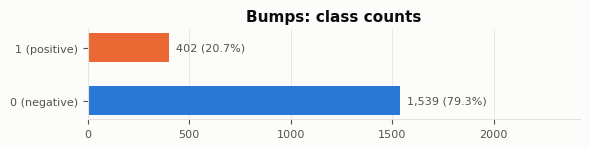

✅ Balance is fine.

✅ About 80 positives in validation.

Held out test: 389 rows (81 positives). Development split for label-driven checks: 1,552 rows.
model features (27): ['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity', 'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer', 'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Steel_Plate_Thickness', 'Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index', 'Orientation_Index'] …


#### Leakage scan: single-feature AUC (development split)

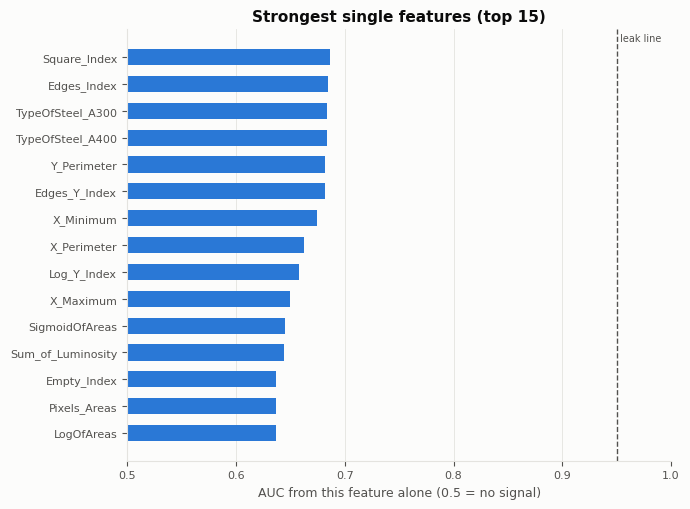

✅ No single feature is suspiciously predictive (max AUC 0.687, from `Square_Index`).

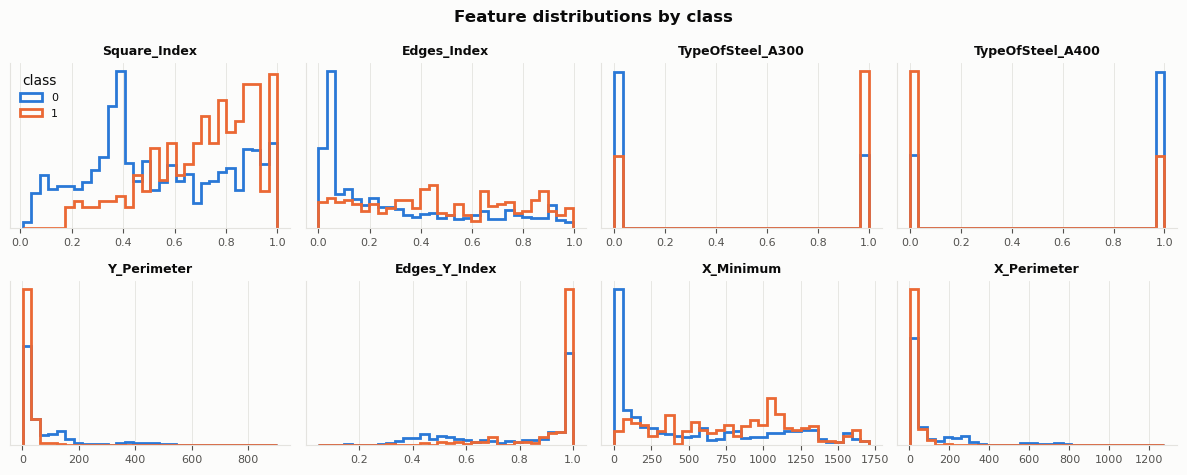

#### Correlated features (glassbox stability)

27 features; pairs with |r| ≥ 0.95: 6


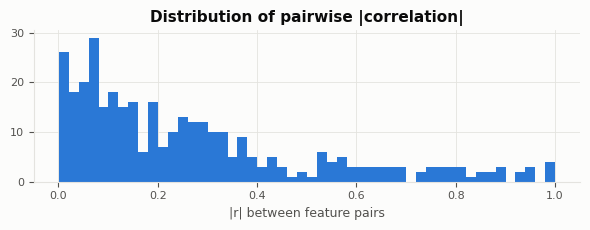

,feature_a,feature_b,|r|
0,X_Minimum,X_Maximum,0.989616
1,Y_Minimum,Y_Maximum,1.000000
2,Pixels_Areas,X_Perimeter,0.956529
3,Pixels_Areas,Sum_of_Luminosity,0.996643
4,X_Perimeter,Sum_of_Luminosity,0.957903
5,TypeOfSteel_A300,TypeOfSteel_A400,1.000000


⚠️ 6 highly correlated pairs. Use LASSO or a ridge penalty, or drop one of each pair, before reading glassbox coefficients.

#### Difficulty check: untuned 5-fold CV AUC (development split)

glassbox: logistic regression    AUC = 0.839 ± 0.019   (0.0s)
blackbox: gradient boosting      AUC = 0.923 ± 0.009   (0.3s)


✅ Room to compare models (best AUC 0.923).

...

#### Train loss: L2 vs surrogate (5-fold out-of-fold AUC, development split)

,model,train loss,OOF AUC,"scores outside [0, 1]"
0,glassbox,L2,0.825,16.3%
1,glassbox,log loss,0.838,0.0%
2,blackbox,L2,0.913,30.0%
3,blackbox,log loss,0.923,0.0%


surrogate − L2 AUC: glassbox +0.014, blackbox +0.010


ℹ️ All four versions train without trouble. Small AUC differences are normal, because AUC only depends on the ranking. The L2 versions show their weakness in calibration and in scores outside [0, 1] (next check).

#### Calibration of the untuned models (out-of-fold, development split)

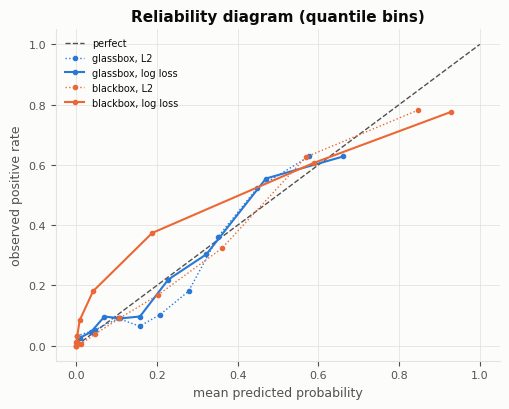

,model,train loss,Brier,ECE (10 bins),mean score
0,glassbox,L2,0.1259,0.0536,0.2174
1,glassbox,log loss,0.1213,0.0345,0.2067
2,blackbox,L2,0.0908,0.0231,0.2148
3,blackbox,log loss,0.0975,0.0642,0.1763
4,blackbox + Platt,log loss,0.0898,0.0179,0.2070


base rate in development split = 0.2068


⚠️ About 8 validation positives per calibration bin. The reliability diagram on validation alone will be noisy: use fewer bins, quantile bins, or out-of-fold predictions.

#### Validation noise: can a validation split of this size tell the models apart?

validation size ≈ 388 rows (80 positives)
blackbox AUC on a validation-sized split: 0.923 ± 0.023 (95% range)
blackbox − glassbox gap: +0.085, sd 0.017; blackbox wins in 100% of draws


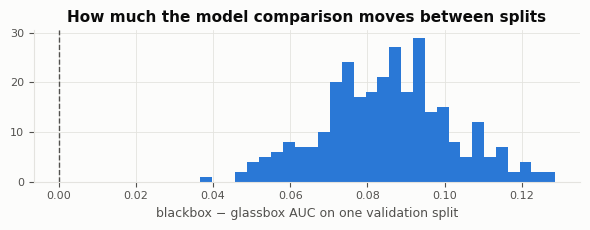

✅ The model comparison is stable at this validation size.

#### Evaluation loss: threshold that minimises expected cost (FN = 20, FP = 1)

*Cost story:* A plate with a Bumps fault shipped to a customer (FN) triggers a claim and a return; a clean plate sent to re-inspection (FP) costs a few minutes of an inspector's time.

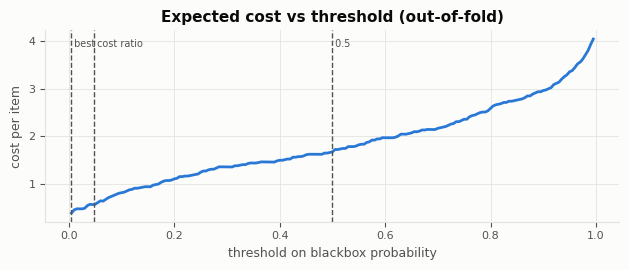

best threshold = 0.005 (cost 0.3853/item); threshold 0.5 costs 1.6714/item -> saving 77%
for a calibrated model the cost-ratio threshold would be 0.048; flag-nothing costs 4.1366, flag-everything costs 0.7932


✅ The evaluation loss moves the decision a lot away from 0.5, which gives the threshold slide something to say.

#### Tree SHAP smoke test (blackbox gradient boosting, development split)

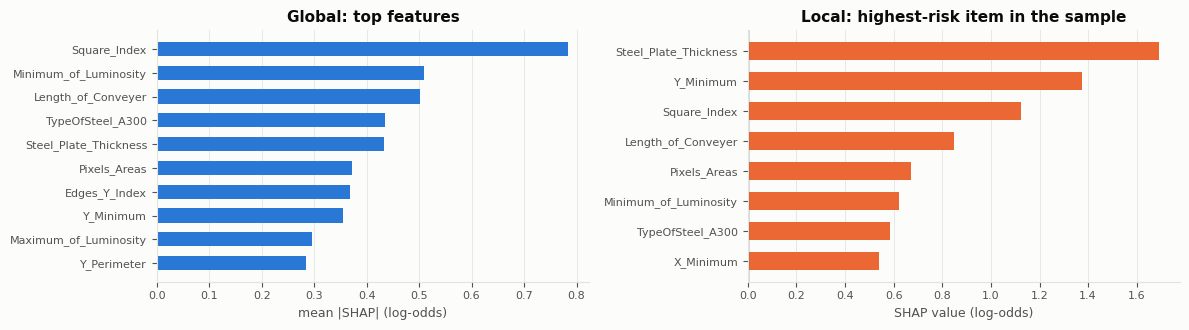

top feature `Square_Index` carries 11% of total mean |SHAP|; rank agreement with single-feature AUC (Spearman) = 0.20


✅ Tree SHAP runs, and attributions are spread over several features: enough material for local and global plots.

In [32]:
if st is not None:
    st_bin = st.drop(columns=[c for c in STEEL_FAULTS if c != STEEL_POSITIVE])
    XE_dev, yE_dev, rankE = standard_screen(st_bin, STEEL_POSITIVE, DS, positive=1, named=True,
        named_note="Named geometric and luminosity features (area, perimeter, brightness, thickness, steel type) support a physical SHAP story.")
    S_E = extended_checks(XE_dev, yE_dev, DS, rankE, c_fn=20, c_fp=1,
        story=f"A plate with a {STEEL_POSITIVE} fault shipped to a customer (FN) triggers a claim and a return; a clean plate sent to re-inspection (FP) costs a few minutes of an inspector's time.")

---
## F. Machine Failure Prediction using Sensor Data (added in review)
944 rows, 9 sensor readings (`footfall`, `tempMode`, `AQ`, `USS`, `CS`, `VOC`, `RP`, `IP`, `Temperature`) and `fail`. Small, and the feature names are short, so check the Kaggle card for what each sensor means before relying on it for the SHAP story. Several of the columns are integer-coded levels, not continuous readings. One public write-up reports a repeated row; the cleaning check will show it.

loaded /Users/testuser/.cache/kagglehub/datasets/umerrtx/machine-failure-prediction-using-sensor-data/versions/1/data.csv


#### Size and structure

rows=944  columns=10  in-memory=0.1 MB  file=0.0 MB
dtypes: {'int64': 10}


,footfall,tempMode,AQ,USS,CS,VOC,RP,IP,Temperature,fail
0,0,7,7,1,6,6,36,3,1,1
1,190,1,3,3,5,1,20,4,1,0
2,31,7,2,2,6,1,24,6,1,0
3,83,4,3,4,5,1,28,6,1,0
4,640,7,5,6,4,0,68,6,1,0


✅ Size is fine (944 rows).

...

,check,count
0,exact duplicate rows,1
1,duplicate feature rows,1
2,…of which with conflicting labels,0
3,constant columns,0
4,near-constant columns (≥99% one value),0
5,duplicate columns,0
6,ID-like columns,0
7,categorical/text columns,0
8,binary columns,0


✅ Little cleaning needed beyond dropping IDs.

positive class = 1


#### Class balance

positives=393 / 944  rate=41.63%  imbalance ratio ≈ 1:1
expected positives: validation≈79, test≈79; per calibration bin (10 bins)≈8


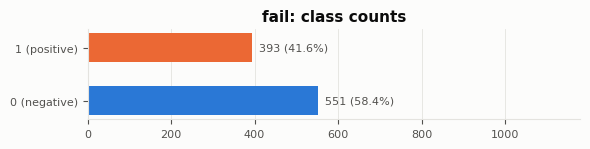

✅ Balance is fine.

✅ About 79 positives in validation.

Held out test: 189 rows (79 positives). Development split for label-driven checks: 755 rows.
model features (9): ['footfall', 'tempMode', 'AQ', 'USS', 'CS', 'VOC', 'RP', 'IP', 'Temperature'] 


#### Leakage scan: single-feature AUC (development split)

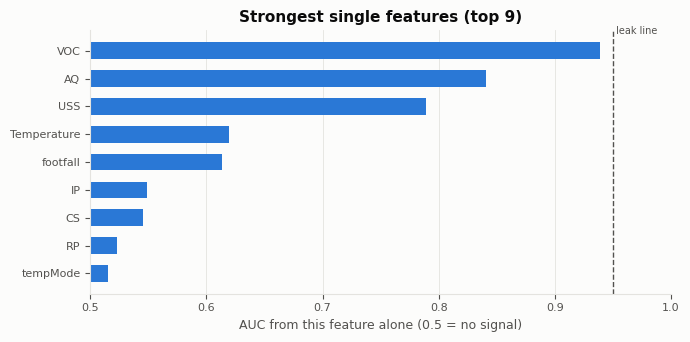

✅ No single feature is suspiciously predictive (max AUC 0.939, from `VOC`).

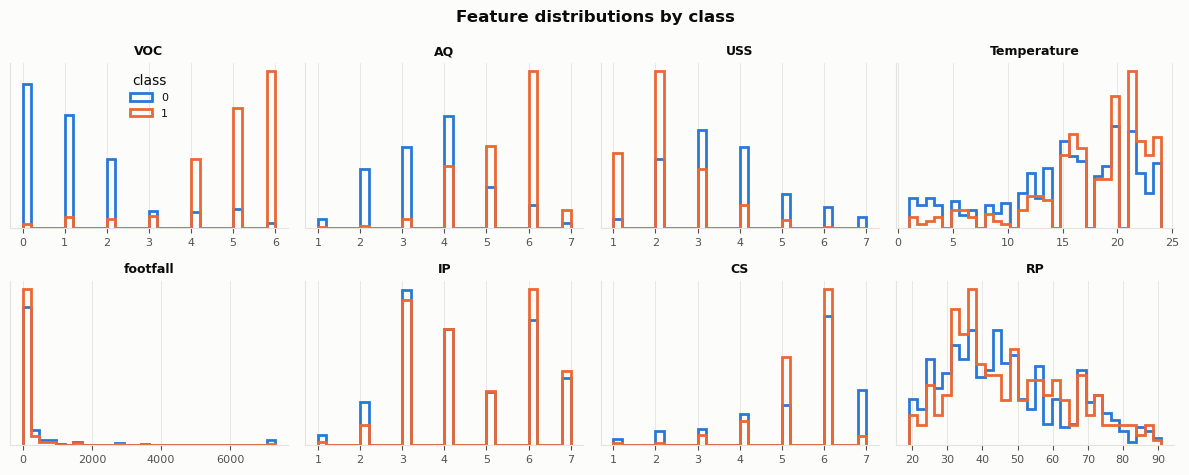

#### Correlated features (glassbox stability)

9 features; pairs with |r| ≥ 0.95: 0


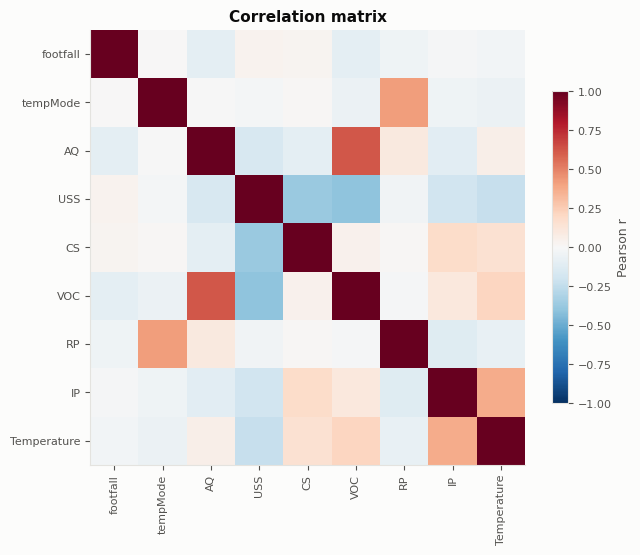

✅ No near-duplicate features.

#### Difficulty check: untuned 5-fold CV AUC (development split)

glassbox: logistic regression    AUC = 0.965 ± 0.013   (0.1s)
blackbox: gradient boosting      AUC = 0.955 ± 0.019   (0.1s)


✅ Room to compare models (best AUC 0.965).

blackbox − glassbox AUC gap: -0.010 (a positive gap gives you an interpretability-vs-performance story)


...

#### Train loss: L2 vs surrogate (5-fold out-of-fold AUC, development split)

,model,train loss,OOF AUC,"scores outside [0, 1]"
0,glassbox,L2,0.963,28.2%
1,glassbox,log loss,0.964,0.0%
2,blackbox,L2,0.947,29.9%
3,blackbox,log loss,0.953,0.0%


surrogate − L2 AUC: glassbox +0.000, blackbox +0.006


ℹ️ All four versions train without trouble. Small AUC differences are normal, because AUC only depends on the ranking. The L2 versions show their weakness in calibration and in scores outside [0, 1] (next check).

#### Calibration of the untuned models (out-of-fold, development split)

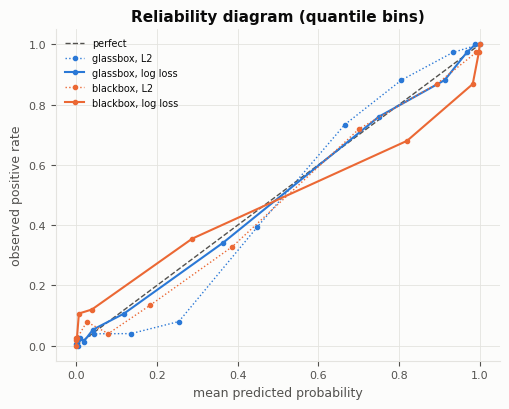

,model,train loss,Brier,ECE (10 bins),mean score
0,glassbox,L2,0.0762,0.0564,0.4289
1,glassbox,log loss,0.0707,0.0219,0.4178
2,blackbox,L2,0.0827,0.0290,0.4254
3,blackbox,log loss,0.0851,0.0606,0.4138
4,blackbox + Platt,log loss,0.0811,0.0197,0.4162


base rate in development split = 0.4159


⚠️ About 8 validation positives per calibration bin. The reliability diagram on validation alone will be noisy: use fewer bins, quantile bins, or out-of-fold predictions.

#### Validation noise: can a validation split of this size tell the models apart?

validation size ≈ 188 rows (78 positives)
blackbox AUC on a validation-sized split: 0.952 ± 0.026 (95% range)
blackbox − glassbox gap: -0.011, sd 0.007; blackbox wins in 4% of draws


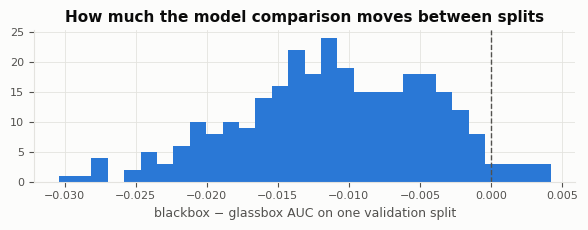

⚠️ A single validation split can't reliably separate glassbox and blackbox. Keep the search small, report the uncertainty, or use repeated CV for the decision.

#### Evaluation loss: threshold that minimises expected cost (FN = 10, FP = 1)

*Cost story:* A missed failure (FN) stops the line; a false alarm (FP) costs a technician visit.

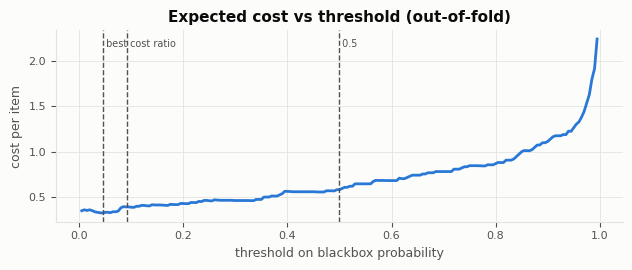

best threshold = 0.045 (cost 0.3232/item); threshold 0.5 costs 0.5801/item -> saving 44%
for a calibrated model the cost-ratio threshold would be 0.091; flag-nothing costs 4.1589, flag-everything costs 0.5841


✅ The evaluation loss moves the decision a lot away from 0.5, which gives the threshold slide something to say.

#### Tree SHAP smoke test (blackbox gradient boosting, development split)

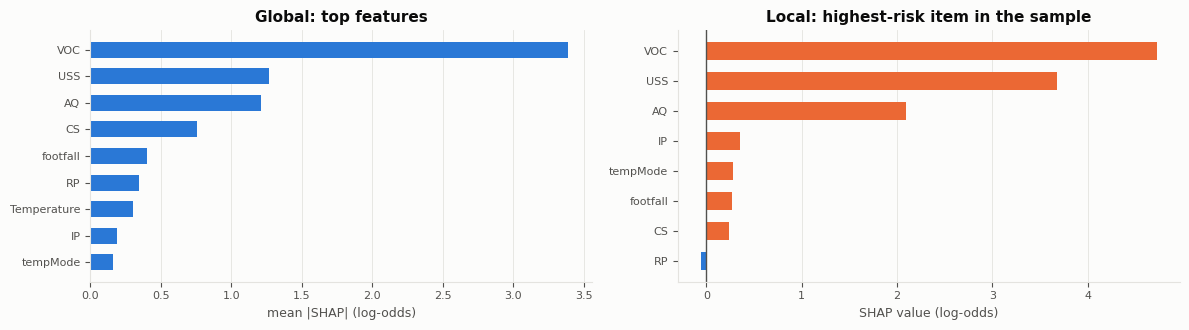

top feature `VOC` carries 42% of total mean |SHAP|; rank agreement with single-feature AUC (Spearman) = 0.77


✅ Tree SHAP runs, and attributions are spread over several features: enough material for local and global plots.

In [33]:
DS = "F · Machine failure (sensors)"
try:
    root = get_dataset_dir("mfs")
    f = find_files(root)[0]
    mf = pd.read_csv(f); print("loaded", f)
    TARGET_F = "fail" if "fail" in mf.columns else mf.columns[-1]
    overview(mf, DS, file_mb=os.path.getsize(f) / 1e6)
except Exception as e:
    mf = None; print("Machine failure dataset not loaded:", repr(e))

if mf is not None:
    XF_dev, yF_dev, rankF = standard_screen(mf, TARGET_F, DS, positive=1, named=True,
        named_note="Named sensors, but several are coded levels with unclear units. Read the dataset card before building a SHAP story on them.")
    S_F = extended_checks(XF_dev, yF_dev, DS, rankF, c_fn=10, c_fp=1,
        story="A missed failure (FN) stops the line; a false alarm (FP) costs a technician visit.")

---
## G. Predicting Manufacturing Defects (added in review)
A synthetic dataset of plant-level KPIs (`ProductionVolume`, `DefectRate`, `QualityScore`, `MaintenanceHours`, `SupplierQuality`, `DowntimePercentage`, …) with a binary `DefectStatus`. It has a high usability rating, but two things need care:
- **The positive class (defect) is the majority** (the Kaggle card suggests over 80%). The imbalance check uses the minority share, so it can still pass, but the cost story has to be framed around the rarer "no defect" outcome.
- **Leakage risk by construction:** columns such as `DefectRate` and `QualityScore` describe the outcome itself. Watch the leakage scan and the SHAP dominance flag.

loaded /Users/testuser/.cache/kagglehub/datasets/rabieelkharoua/predicting-manufacturing-defects-dataset/versions/1/manufacturing_defect_dataset.csv


#### Size and structure

rows=3,240  columns=17  in-memory=0.4 MB  file=0.8 MB
dtypes: {'float64': 12, 'int64': 5}


,ProductionVolume,ProductionCost,SupplierQuality,DeliveryDelay,DefectRate,QualityScore,MaintenanceHours,DowntimePercentage,InventoryTurnover,StockoutRate,WorkerProductivity,SafetyIncidents,EnergyConsumption,EnergyEfficiency,AdditiveProcessTime,AdditiveMaterialCost,DefectStatus
0,202,13175.403783,86.648534,1,3.121492,63.463494,9,0.052343,8.630515,0.081322,85.042379,0,2419.616785,0.468947,5.551639,236.439301,1
1,535,19770.046093,86.310664,4,0.819531,83.697818,20,4.908328,9.296598,0.038486,99.657443,7,3915.566713,0.119485,9.080754,353.957631,1
2,960,19060.820997,82.132472,0,4.514504,90.350550,1,2.464923,5.097486,0.002887,92.819264,2,3392.385362,0.496392,6.562827,396.189402,1
3,370,5647.606037,87.335966,5,0.638524,67.628690,8,4.692476,3.577616,0.055331,96.887013,8,4652.400275,0.183125,8.097496,164.135870,1
4,206,7472.222236,81.989893,3,3.867784,82.728334,9,2.746726,6.851709,0.068047,88.315554,7,1581.630332,0.263507,6.406154,365.708964,1


✅ Size is fine (3,240 rows).

...

,check,count
0,exact duplicate rows,0
1,duplicate feature rows,0
2,…of which with conflicting labels,0
3,constant columns,0
4,near-constant columns (≥99% one value),0
5,duplicate columns,0
6,ID-like columns,0
7,categorical/text columns,0
8,binary columns,0


✅ Little cleaning needed beyond dropping IDs.

positive class = 1


#### Class balance

positives=2,723 / 3,240  rate=84.04%  imbalance ratio ≈ 1:0
expected positives: validation≈545, test≈545; per calibration bin (10 bins)≈54


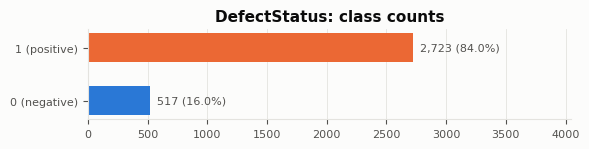

✅ Balance is fine.

✅ About 545 positives in validation.

Held out test: 648 rows (545 positives). Development split for label-driven checks: 2,592 rows.
model features (16): ['ProductionVolume', 'ProductionCost', 'SupplierQuality', 'DeliveryDelay', 'DefectRate', 'QualityScore', 'MaintenanceHours', 'DowntimePercentage', 'InventoryTurnover', 'StockoutRate', 'WorkerProductivity', 'SafetyIncidents', 'EnergyConsumption', 'EnergyEfficiency', 'AdditiveProcessTime', 'AdditiveMaterialCost'] 


#### Leakage scan: single-feature AUC (development split)

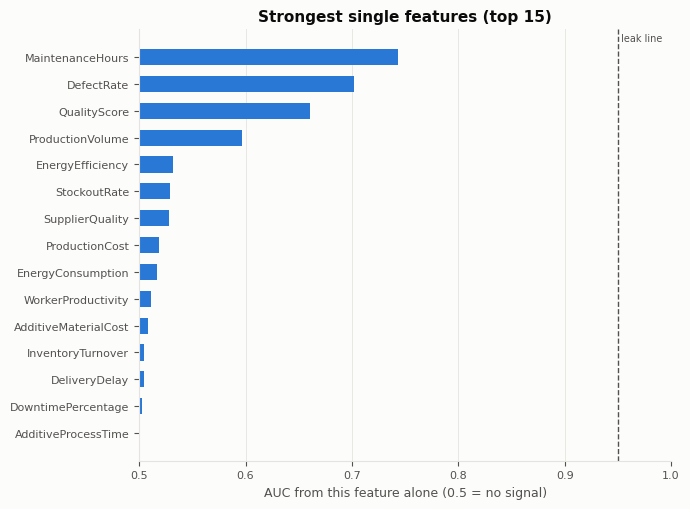

✅ No single feature is suspiciously predictive (max AUC 0.743, from `MaintenanceHours`).

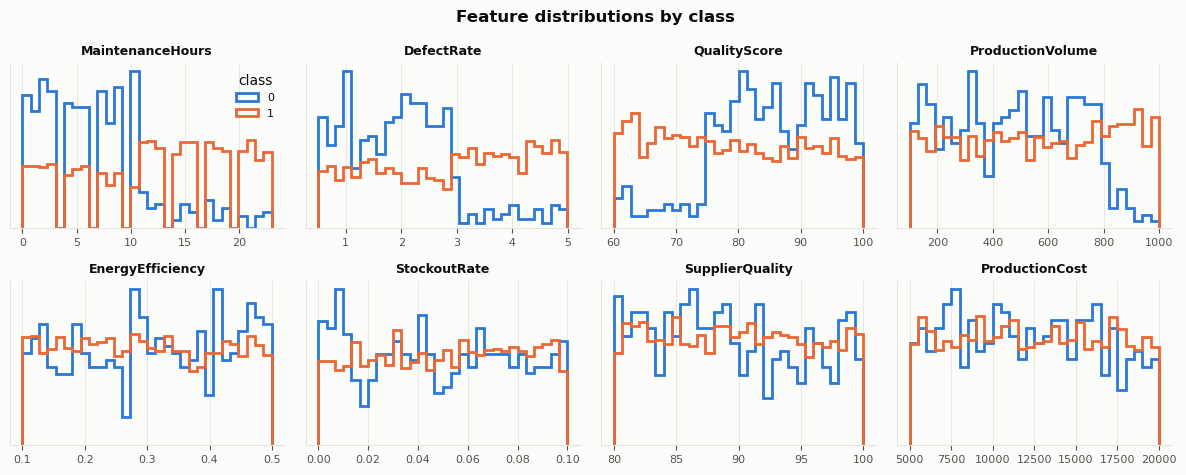

#### Correlated features (glassbox stability)

16 features; pairs with |r| ≥ 0.95: 0


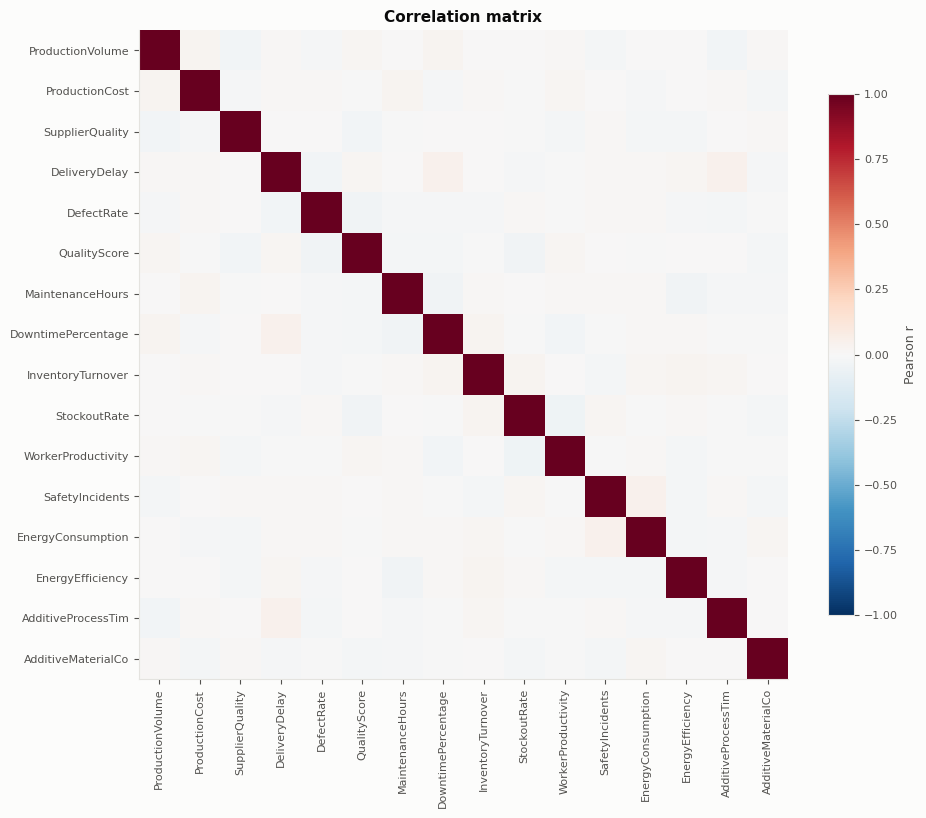

✅ No near-duplicate features.

#### Difficulty check: untuned 5-fold CV AUC (development split)

glassbox: logistic regression    AUC = 0.847 ± 0.026   (0.0s)
blackbox: gradient boosting      AUC = 0.919 ± 0.025   (0.3s)


✅ Room to compare models (best AUC 0.919).

blackbox − glassbox AUC gap: +0.071 (a positive gap gives you an interpretability-vs-performance story)


...

#### Train loss: L2 vs surrogate (5-fold out-of-fold AUC, development split)

,model,train loss,OOF AUC,"scores outside [0, 1]"
0,glassbox,L2,0.846,19.2%
1,glassbox,log loss,0.847,0.0%
2,blackbox,L2,0.915,28.7%
3,blackbox,log loss,0.917,0.0%


surrogate − L2 AUC: glassbox +0.001, blackbox +0.002


ℹ️ All four versions train without trouble. Small AUC differences are normal, because AUC only depends on the ranking. The L2 versions show their weakness in calibration and in scores outside [0, 1] (next check).

#### Calibration of the untuned models (out-of-fold, development split)

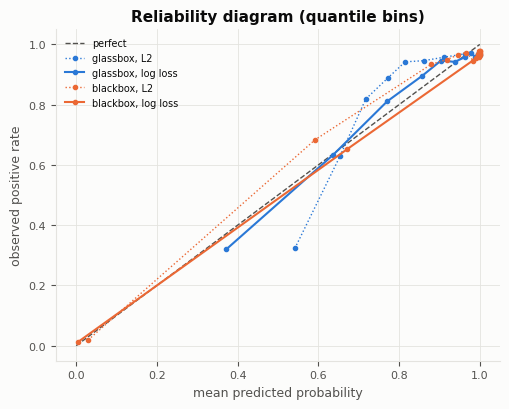

,model,train loss,Brier,ECE (10 bins),mean score
0,glassbox,L2,0.1025,0.0685,0.8236
1,glassbox,log loss,0.0920,0.0216,0.8401
2,blackbox,L2,0.0378,0.0241,0.8312
3,blackbox,log loss,0.0361,0.0315,0.8655
4,blackbox + Platt,log loss,0.0363,0.0127,0.8401


base rate in development split = 0.8403


✅ About 54 validation positives per calibration bin.

#### Validation noise: can a validation split of this size tell the models apart?

validation size ≈ 648 rows (544 positives)
blackbox AUC on a validation-sized split: 0.919 ± 0.037 (95% range)
blackbox − glassbox gap: +0.071, sd 0.015; blackbox wins in 100% of draws


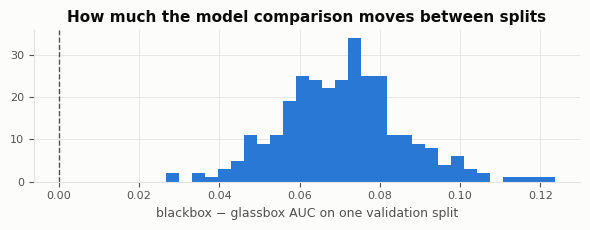

✅ The model comparison is stable at this validation size.

#### Evaluation loss: threshold that minimises expected cost (FN = 10, FP = 2)

*Cost story:* A defective batch released (FN) costs a recall; holding a good batch for testing (FP) costs a delay.

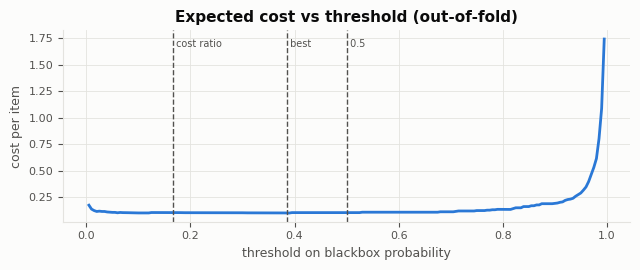

best threshold = 0.385 (cost 0.1003/item); threshold 0.5 costs 0.1042/item -> saving 4%
for a calibrated model the cost-ratio threshold would be 0.167; flag-nothing costs 8.4028, flag-everything costs 0.3194


ℹ️ The evaluation loss barely changes the decision at this cost ratio. Justify a different ratio, or expect a thin threshold slide.

#### Tree SHAP smoke test (blackbox gradient boosting, development split)

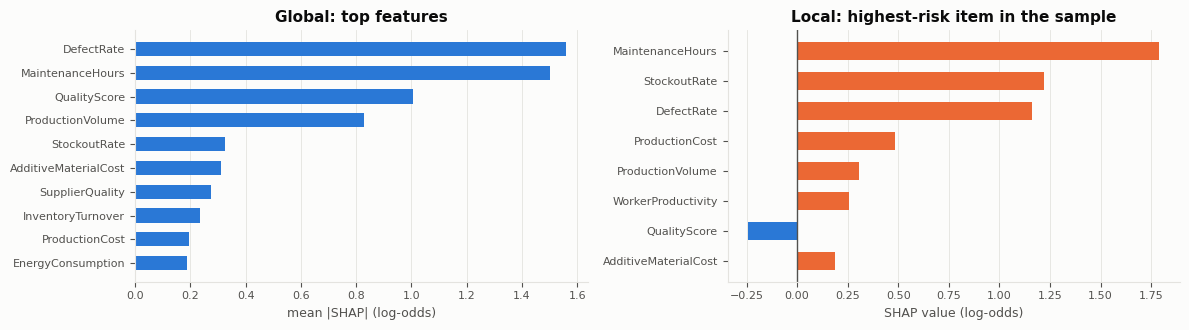

top feature `DefectRate` carries 22% of total mean |SHAP|; rank agreement with single-feature AUC (Spearman) = 0.78


✅ Tree SHAP runs, and attributions are spread over several features: enough material for local and global plots.

In [34]:
DS = "G · Manufacturing defects"
try:
    root = get_dataset_dir("mdef")
    f = find_files(root)[0]
    md_ = pd.read_csv(f); print("loaded", f)
    TARGET_G = "DefectStatus" if "DefectStatus" in md_.columns else md_.columns[-1]
    overview(md_, DS, file_mb=os.path.getsize(f) / 1e6)
except Exception as e:
    md_ = None; print("Manufacturing defects dataset not loaded:", repr(e))

if md_ is not None:
    XG_dev, yG_dev, rankG = standard_screen(md_, TARGET_G, DS, positive=1, named=True,
        named_note="Named KPIs, but the data is synthetic. Check that the SHAP ranking is plausible and not just the generator's formula.")
    S_G = extended_checks(XG_dev, yG_dev, DS, rankG, c_fn=10, c_fp=2,
        story="A defective batch released (FN) costs a recall; holding a good batch for testing (FP) costs a delay.")

---
## H. APS Failure at Scania Trucks (added in review)
60,000 training rows, 170 **anonymised** counters and histogram bins (`aa_000`, `ag_001`, …), `class` = pos/neg for an air-pressure-system failure. Missing values are written as `na`.

Its big strength is an **official evaluation loss**: a false positive (unnecessary workshop check) costs 10, a false negative (a missed faulty truck) costs 500. That's exactly the "evaluation loss deviates from misclassification" requirement. Against that, expect it to fail the slide rules on **missing data**, **severe imbalance** (about 1.7% positive) and **named features**. It's screened here so the trade-off is explicit.

CSV files found: ['aps_failure_training_set_processed_8bit.csv', 'aps_failure_training_set.csv', 'aps_failure_test_set_processed_8bit.csv', 'aps_failure_test_set.csv']
loaded /Users/testuser/.cache/kagglehub/datasets/uciml/aps-failure-at-scania-trucks-data-set/versions/3/aps_failure_training_set.csv


#### Size and structure

rows=60,000  columns=171  in-memory=85.2 MB  file=44.7 MB
dtypes: {'float64': 169, 'object': 1, 'int64': 1}


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,ag_004,ag_005,ag_006,ag_007,ag_008,ag_009,ah_000,ai_000,aj_000,...,dv_000,dx_000,dy_000,dz_000,ea_000,eb_000,ec_00,ed_000,ee_000,ee_001,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,0.0,37250.0,1432864.0,3664156.0,1007684.0,25896.0,0.0,2551696.0,0.0,0.0,...,1876644.0,0.0,0.0,0.0,0.0,2801180.0,2445.80,2712.0,965866.0,1706908.0,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,0.0,18254.0,653294.0,1720800.0,516724.0,31642.0,0.0,1393352.0,0.0,68.0,...,868538.0,0.0,0.0,0.0,0.0,3477820.0,2211.76,2334.0,664504.0,824154.0,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,0.0,1648.0,370592.0,1883374.0,292936.0,12016.0,0.0,1234132.0,0.0,0.0,...,48028.0,0.0,0.0,0.0,0.0,1040120.0,1018.64,1020.0,262032.0,453378.0,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,318.0,2212.0,3232.0,1872.0,0.0,0.0,0.0,2668.0,0.0,0.0,...,1822.0,20174.0,44.0,0.0,0.0,0.0,1.08,54.0,5670.0,1566.0,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,0.0,43752.0,1966618.0,1800340.0,131646.0,4588.0,0.0,1974038.0,0.0,226.0,...,80482.0,98334.0,27588.0,0.0,0.0,21173050.0,1116.06,1176.0,404740.0,904230.0,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


✅ Size is fine (60,000 rows).

#### Missing data

missing cells: 850,015 (8.28%); columns with any missing: 169/171


,share_missing
br_000,0.821067
bq_000,0.812033
bp_000,0.795667
bo_000,0.772217
ab_000,0.772150
cr_000,0.772150
bn_000,0.733483
bm_000,0.659150
bl_000,0.454617
bk_000,0.383900


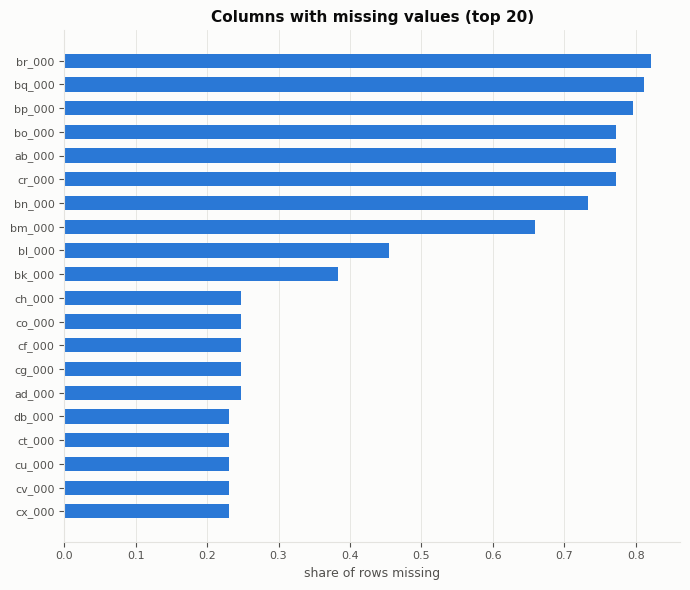

❌ Heavy missing data. The slides say to avoid this.

#### Data-cleaning load

,check,count
0,exact duplicate rows,0
1,duplicate feature rows,0
2,…of which with conflicting labels,0
3,constant columns,0
4,near-constant columns (≥99% one value),0
5,duplicate columns,0
6,ID-like columns,0
7,categorical/text columns,0
8,binary columns,1


✅ Little cleaning needed beyond dropping IDs.

positive class = pos


#### Class balance

positives=1,000 / 60,000  rate=1.67%  imbalance ratio ≈ 1:59
expected positives: validation≈200, test≈200; per calibration bin (10 bins)≈20


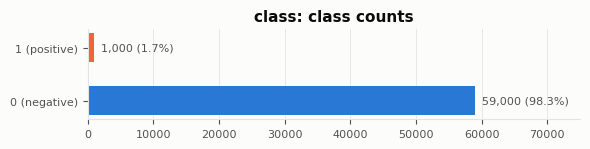

❌ Severe imbalance. The slides say to avoid this.

✅ About 200 positives in validation.

Held out test: 12,000 rows (200 positives). Development split for label-driven checks: 48,000 rows.
model features (170): ['aa_000', 'ab_000', 'ac_000', 'ad_000', 'ae_000', 'af_000', 'ag_000', 'ag_001', 'ag_002', 'ag_003', 'ag_004', 'ag_005', 'ag_006', 'ag_007', 'ag_008', 'ag_009', 'ah_000', 'ai_000', 'aj_000', 'ak_000', 'al_000', 'am_0', 'an_000', 'ao_000', 'ap_000'] …


#### Leakage scan: single-feature AUC (development split)

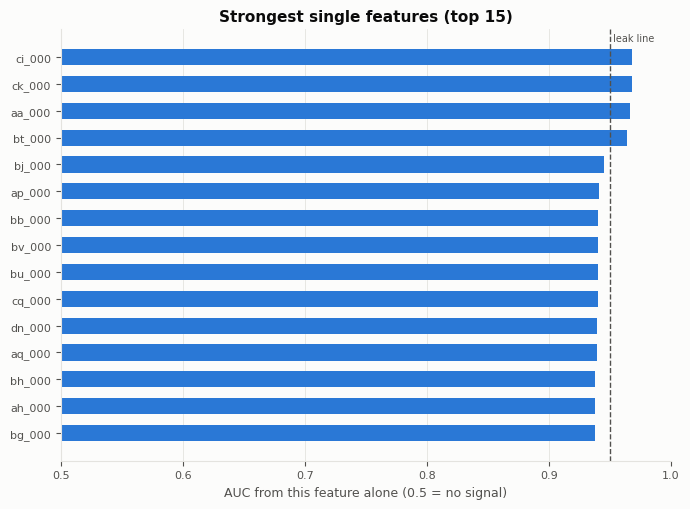

❌ Leakage suspects (AUC ≥ 0.95): ['ci_000', 'ck_000', 'aa_000', 'bt_000']. Drop them, or explain why they're legitimate.

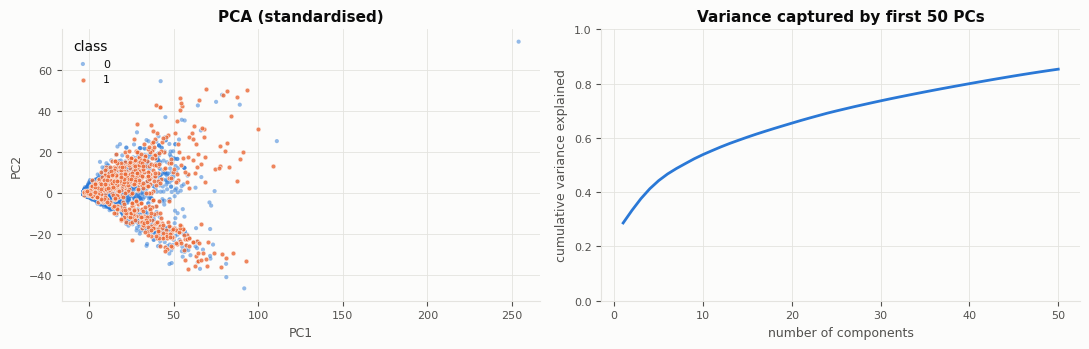

First 2 PCs explain 33.3%; first 50 explain 85.3%.


#### Correlated features (glassbox stability)

169 features; pairs with |r| ≥ 0.95: 54


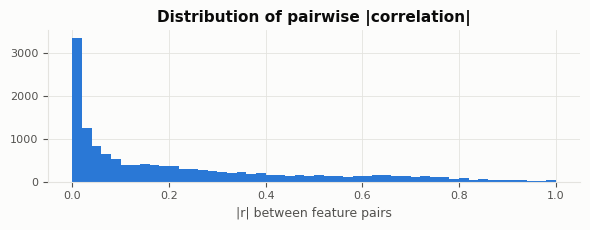

,feature_a,feature_b,|r|
0,aa_000,bt_000,1.000000
1,aa_000,ci_000,0.966182
2,ad_000,cf_000,1.000000
3,ad_000,co_000,1.000000
4,ag_006,cn_005,0.954847
5,ah_000,an_000,0.988361
6,ah_000,ao_000,0.973841
7,ah_000,bb_000,0.983322
8,ah_000,bg_000,1.000000
9,ah_000,bh_000,0.953414


⚠️ 54 highly correlated pairs. Use LASSO or a ridge penalty, or drop one of each pair, before reading glassbox coefficients.

#### Difficulty check: untuned 5-fold CV AUC (development split)

glassbox: logistic regression    AUC = 0.956 ± 0.013   (9.8s)
blackbox: gradient boosting      AUC = 0.988 ± 0.005   (7.2s)


⚠️ Almost perfect (AUC 0.988). The slides say to delete some features to make it harder. See the difficulty probe.

...

#### Train loss: L2 vs surrogate (5-fold out-of-fold AUC, development split)

,model,train loss,OOF AUC,"scores outside [0, 1]"
0,glassbox,L2,0.968,54.0%
1,glassbox,log loss,0.955,0.0%
2,blackbox,L2,0.972,10.7%
3,blackbox,log loss,0.987,0.0%


surrogate − L2 AUC: glassbox -0.013, blackbox +0.015


ℹ️ All four versions train without trouble. Small AUC differences are normal, because AUC only depends on the ranking. The L2 versions show their weakness in calibration and in scores outside [0, 1] (next check).

#### Calibration of the untuned models (out-of-fold, development split)

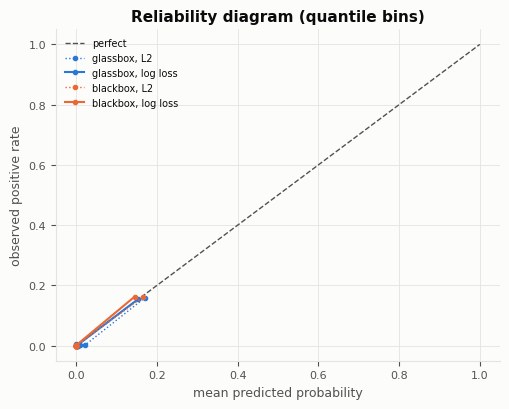

,model,train loss,Brier,ECE (10 bins),mean score
0,glassbox,L2,0.0076,0.0087,0.0208
1,glassbox,log loss,0.0071,0.0028,0.0169
2,blackbox,L2,0.0055,0.0016,0.0168
3,blackbox,log loss,0.0058,0.0037,0.0146
4,blackbox + Platt,log loss,0.0056,0.0011,0.0167


base rate in development split = 0.0167


✅ About 20 validation positives per calibration bin.

#### Validation noise: can a validation split of this size tell the models apart?

validation size ≈ 12,000 rows (200 positives)
blackbox AUC on a validation-sized split: 0.987 ± 0.008 (95% range)
blackbox − glassbox gap: +0.032, sd 0.010; blackbox wins in 100% of draws


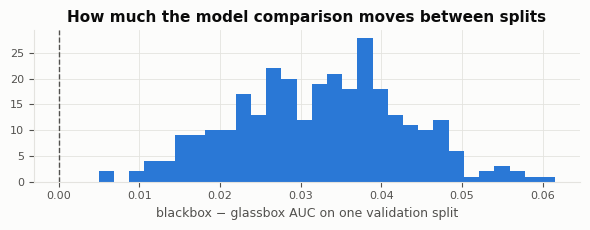

✅ The model comparison is stable at this validation size.

#### Evaluation loss: threshold that minimises expected cost (FN = 500, FP = 10)

*Cost story:* Official challenge costs: an unnecessary workshop check (FP) costs 10; a missed faulty truck that breaks down (FN) costs 500.

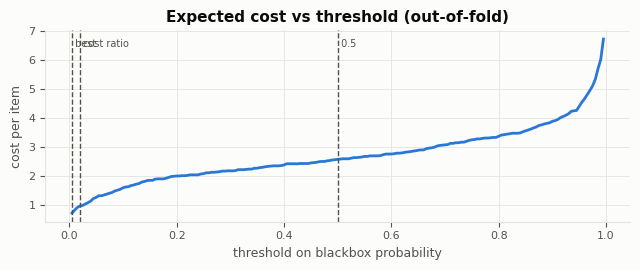

best threshold = 0.005 (cost 0.7212/item); threshold 0.5 costs 2.5742/item -> saving 72%
for a calibrated model the cost-ratio threshold would be 0.020; flag-nothing costs 8.3333, flag-everything costs 9.8333


✅ The evaluation loss moves the decision a lot away from 0.5, which gives the threshold slide something to say.

#### Tree SHAP smoke test (blackbox gradient boosting, development split)

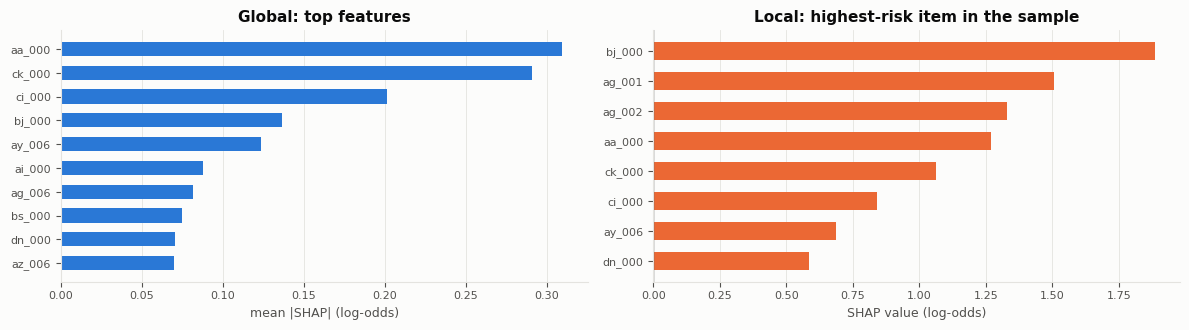

top feature `aa_000` carries 9% of total mean |SHAP|; rank agreement with single-feature AUC (Spearman) = 0.30


✅ Tree SHAP runs, and attributions are spread over several features: enough material for local and global plots.

In [35]:
DS = "H · APS Scania"
def read_aps(path):
    with open(path, errors="ignore") as fh:
        head = [next(fh, "") for _ in range(40)]
    skip = next(i for i, line in enumerate(head) if line.lower().startswith("class"))   # the UCI file starts with a licence block
    return pd.read_csv(path, skiprows=skip, na_values=["na"])

try:
    root = get_dataset_dir("aps")
    files = find_files(root)
    print("CSV files found:", [os.path.basename(p) for p in files])
    f = [p for p in files if re.search("train", os.path.basename(p), re.I) and not re.search("process", p, re.I)][0]
    aps = read_aps(f); print("loaded", f)
    overview(aps, DS, file_mb=os.path.getsize(f) / 1e6)
except Exception as e:
    aps = None; print("APS dataset not loaded:", repr(e))

if aps is not None:
    XH2_dev, yH2_dev, rankH2 = standard_screen(aps, "class", DS, positive="pos", named=False,
        named_note="Anonymised counters (`aa_000`, …). SHAP plots can't be tied to a physical cause.")
    S_H = extended_checks(XH2_dev, yH2_dev, DS, rankH2, c_fn=500, c_fp=10,
        story="Official challenge costs: an unnecessary workshop check (FP) costs 10; a missed faulty truck that breaks down (FN) costs 500.")

---
## I. SECOM semiconductor process (added in review)
1,567 wafers, 590 **anonymised** sensor signals, `Pass/Fail` with −1 = pass and 1 = fail (104 fails, about 6.6%). It's the closest real fab dataset to the Micron theme, but expect missing values across many columns, constant columns, and nothing for SHAP to explain. The loader accepts the Kaggle CSV (`uci-secom.csv`) or the original UCI files (`secom.data` + `secom_labels.data`).

loaded /Users/testuser/.cache/kagglehub/datasets/paresh2047/uci-semcom/versions/1/uci-secom.csv


#### Size and structure

rows=1,567  columns=591  in-memory=7.4 MB  file=6.1 MB
dtypes: {'float64': 590, 'int64': 1}


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,...,571,572,573,574,575,576,577,578,579,580,581,582,583,584,585,586,587,588,589,Pass/Fail
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,-0.0034,0.9455,202.4396,0.0,7.9558,414.8710,10.0433,0.9680,192.3963,12.5190,...,2.1113,8.95,0.3157,3.0624,0.1026,1.6765,14.9509,NaN,NaN,NaN,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN,-1
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,-0.0148,0.9627,200.5470,0.0,10.1548,414.7347,9.2599,0.9701,191.2872,12.4608,...,2.4335,5.92,0.2653,2.0111,0.0772,1.1065,10.9003,0.0096,0.0201,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045,-1
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,0.0013,0.9615,202.0179,0.0,9.5157,416.7075,9.3144,0.9674,192.7035,12.5404,...,2.0293,11.21,0.1882,4.0923,0.0640,2.0952,9.2721,0.0584,0.0484,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602,1
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,-0.0033,0.9629,201.8482,0.0,9.6052,422.2894,9.6924,0.9687,192.1557,12.4782,...,2.0253,9.33,0.1738,2.8971,0.0525,1.7585,8.5831,0.0202,0.0149,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432,-1
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,-0.0072,0.9569,201.9424,0.0,10.5661,420.5925,10.3387,0.9735,191.6037,12.4735,...,2.0275,8.83,0.2224,3.1776,0.0706,1.6597,10.9698,NaN,NaN,NaN,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432,-1


✅ Size is fine (1,567 rows).

#### Missing data

missing cells: 41,951 (4.53%); columns with any missing: 538/591


,share_missing
292,0.911934
293,0.911934
157,0.911934
158,0.911934
358,0.855775
85,0.855775
492,0.855775
220,0.855775
518,0.649649
246,0.649649


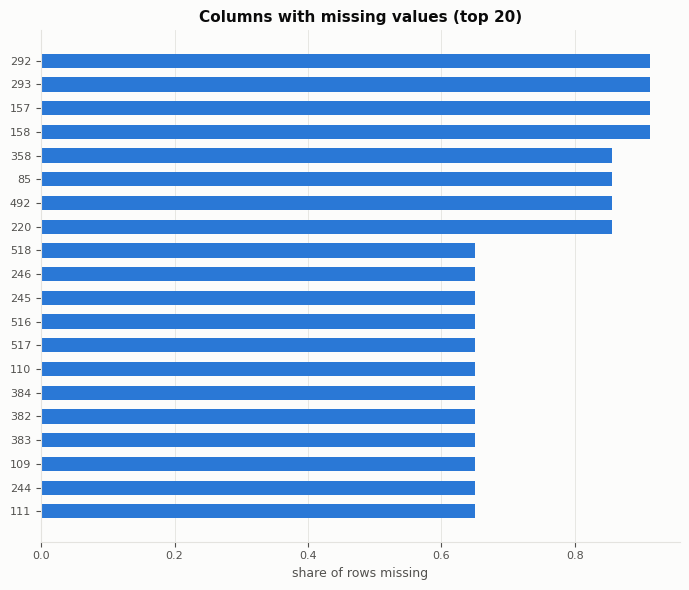

⚠️ Some missing data. Plan imputation.

#### Data-cleaning load

,check,count
0,exact duplicate rows,0
1,duplicate feature rows,0
2,…of which with conflicting labels,0
3,constant columns,0
4,near-constant columns (≥99% one value),117
5,duplicate columns,104
6,ID-like columns,0
7,categorical/text columns,0
8,binary columns,116


⚠️ Some cleaning needed (see table).

positive class = 1


#### Class balance

positives=104 / 1,567  rate=6.64%  imbalance ratio ≈ 1:14
expected positives: validation≈21, test≈21; per calibration bin (10 bins)≈2


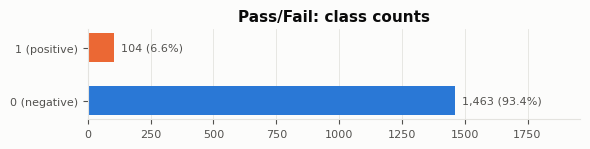

⚠️ Moderate imbalance. Use a stratified split, report AUC, and tune the threshold.

⚠️ About 21 positives in validation: AUC, threshold and calibration estimates will be noisy. Keep the grids small and consider CV.

Held out test: 314 rows (21 positives). Development split for label-driven checks: 1,253 rows.
model features (590): ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24'] …


#### Leakage scan: single-feature AUC (development split)

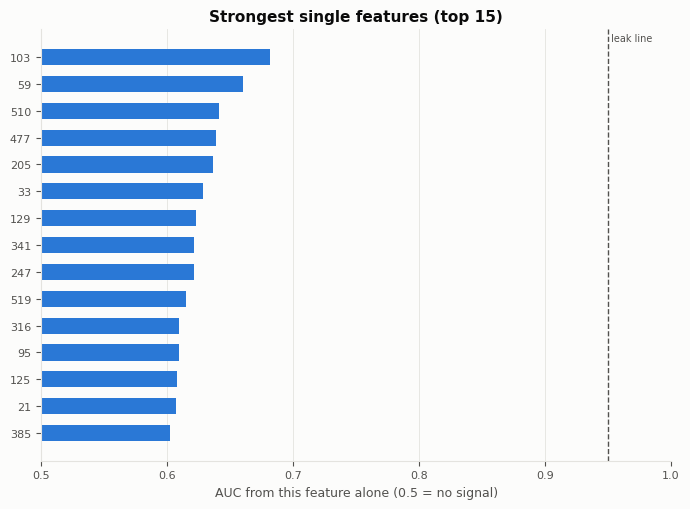

✅ No single feature is suspiciously predictive (max AUC 0.681, from `103`).

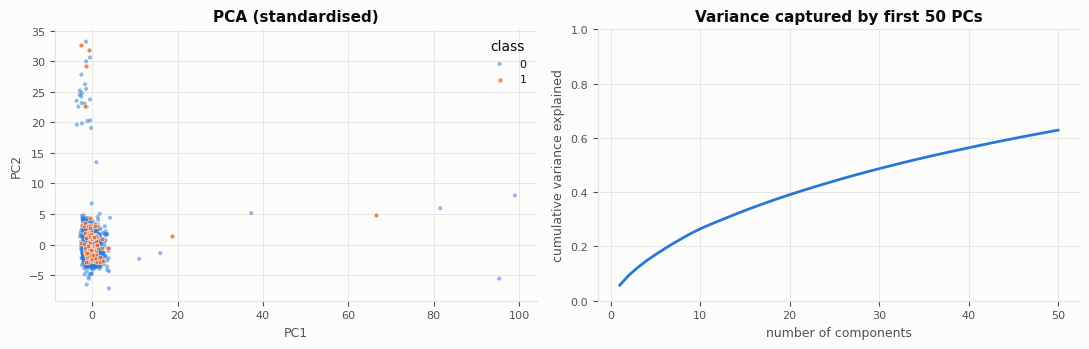

First 2 PCs explain 9.3%; first 50 explain 62.9%.


#### Correlated features (glassbox stability)

474 features; pairs with |r| ≥ 0.95: 337


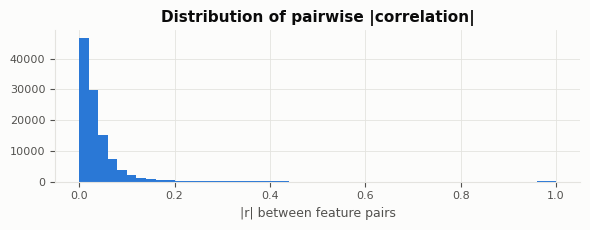

,feature_a,feature_b,|r|
0,4,140,0.999961
1,4,275,0.999962
2,16,148,0.977558
3,16,152,0.983058
4,16,283,0.978306
5,16,287,0.983126
6,16,421,0.971722
7,25,27,0.981507
8,34,36,1.000000
9,74,206,1.000000


⚠️ 337 highly correlated pairs. Use LASSO or a ridge penalty, or drop one of each pair, before reading glassbox coefficients.

#### Difficulty check: untuned 5-fold CV AUC (development split)

glassbox: logistic regression    AUC = 0.606 ± 0.081   (0.5s)
blackbox: gradient boosting      AUC = 0.701 ± 0.037   (13.3s)


✅ Room to compare models (best AUC 0.701).

...

#### Train loss: L2 vs surrogate (5-fold out-of-fold AUC, development split)

,model,train loss,OOF AUC,"scores outside [0, 1]"
0,glassbox,L2,0.624,38.4%
1,glassbox,log loss,0.607,0.0%
2,blackbox,L2,0.662,26.6%
3,blackbox,log loss,0.702,0.0%


surrogate − L2 AUC: glassbox -0.017, blackbox +0.039


ℹ️ All four versions train without trouble. Small AUC differences are normal, because AUC only depends on the ranking. The L2 versions show their weakness in calibration and in scores outside [0, 1] (next check).

#### Calibration of the untuned models (out-of-fold, development split)

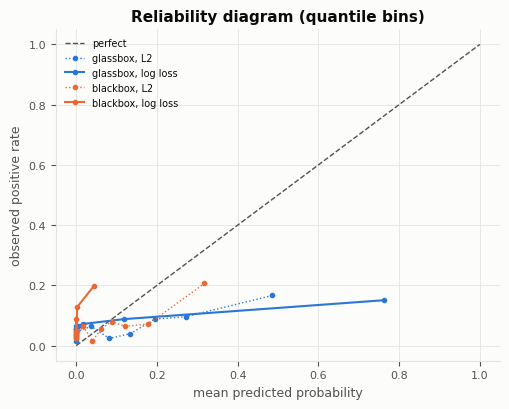

,model,train loss,Brier,ECE (10 bins),mean score
0,glassbox,L2,0.0810,0.0865,0.1208
1,glassbox,log loss,0.1054,0.1048,0.0905
2,blackbox,L2,0.0632,0.0410,0.0827
3,blackbox,log loss,0.0653,0.0641,0.0048
4,blackbox + Platt,log loss,0.0595,0.0051,0.0664


base rate in development split = 0.0662


⚠️ About 2 validation positives per calibration bin. The reliability diagram on validation alone will be noisy: use fewer bins, quantile bins, or out-of-fold predictions.

#### Validation noise: can a validation split of this size tell the models apart?

validation size ≈ 313 rows (21 positives)
blackbox AUC on a validation-sized split: 0.703 ± 0.114 (95% range)
blackbox − glassbox gap: +0.091, sd 0.061; blackbox wins in 92% of draws


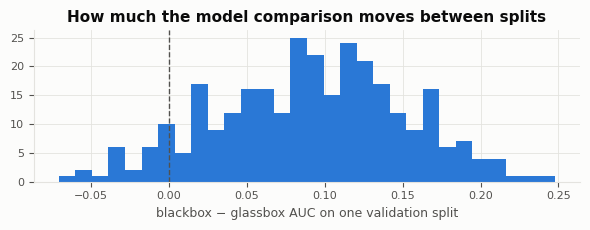

⚠️ A single validation split can't reliably separate glassbox and blackbox. Keep the search small, report the uncertainty, or use repeated CV for the decision.

#### Evaluation loss: threshold that minimises expected cost (FN = 20, FP = 1)

*Cost story:* A failing wafer that passes in-line checks (FN) is scrapped at final test after all value has been added; a false flag (FP) costs one metrology step.

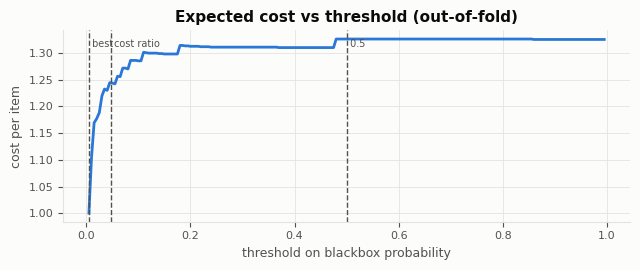

best threshold = 0.005 (cost 1.0008/item); threshold 0.5 costs 1.3256/item -> saving 25%
for a calibrated model the cost-ratio threshold would be 0.048; flag-nothing costs 1.3248, flag-everything costs 0.9338


✅ The evaluation loss moves the decision a lot away from 0.5, which gives the threshold slide something to say.

#### Tree SHAP smoke test (blackbox gradient boosting, development split)

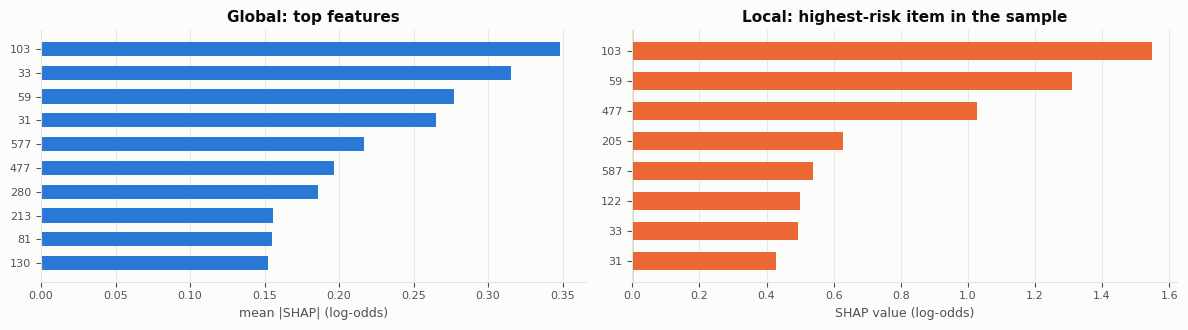

top feature `103` carries 4% of total mean |SHAP|; rank agreement with single-feature AUC (Spearman) = 0.32


✅ Tree SHAP runs, and attributions are spread over several features: enough material for local and global plots.

In [36]:
DS = "I · SECOM"
try:
    root = get_dataset_dir("secom")
    raw = find_files(root, exts=(".data",))
    if any(p.endswith("secom.data") for p in raw):
        X_ = pd.read_csv([p for p in raw if p.endswith("secom.data")][0], sep=r"\s+", header=None).add_prefix("s")
        lab_ = pd.read_csv([p for p in raw if p.endswith("secom_labels.data")][0], sep=r"\s+", header=None)
        secom = X_.assign(**{"Pass/Fail": lab_[0].values}); f = raw[0]
    else:
        f = find_files(root)[0]
        secom = pd.read_csv(f).drop(columns=["Time"], errors="ignore")
    print("loaded", f)
    overview(secom, DS, file_mb=os.path.getsize(f) / 1e6)
except Exception as e:
    secom = None; print("SECOM not loaded:", repr(e))

if secom is not None:
    XI_dev, yI_dev, rankI = standard_screen(secom, "Pass/Fail", DS, positive=1, named=False,
        named_note="590 anonymised sensors. SHAP plots can't be tied to a cause.")
    S_I = extended_checks(XI_dev, yI_dev, DS, rankI, c_fn=20, c_fp=1,
        story="A failing wafer that passes in-line checks (FN) is scrapped at final test after all value has been added; a false flag (FP) costs one metrology step.")

---
## J. Singapore: will it rain tomorrow? (optional, data.gov.sg)
The slides suggest Singapore-related data from data.gov.sg. NEA's **Historical Daily Weather Records** (dataset `d_03bb2eb67ad645d0188342fa74ad7066`) has one row per station per day: daily rainfall total, highest 30/60/120-minute rainfall, mean/max/min temperature, and mean/max wind speed.

- **Target built here:** next-day rainfall at the same station ≥ `SG_RAIN_MM`. Features are today's readings plus month and station, so nothing from tomorrow leaks in.
- **Cost story:** e.g. a construction site deciding whether to pour concrete or a stadium deciding whether to deploy covers.
- **Expect cleaning:** NEA marks missing readings with dashes, and not every station records every variable. The column names are matched by pattern, so check the printed mapping.
- **Untested:** data.gov.sg wasn't reachable from the environment where this cell was written, so run it locally and check the mapping. If the API call fails, download the CSV from the dataset page and set `SG_DIR`.

loaded /Users/testuser/.cache/datagovsg/d_03bb2eb67ad645d0188342fa74ad7066.csv columns: ['date', 'station', 'daily_rainfall_total', 'highest_30_min_rainfall', 'highest_60_min_rainfall', 'highest_120_min_rainfall', 'mean_temperature', 'maximum_temperature', 'minimum_temperature', 'mean_wind_speed', 'max_wind_speed']
column mapping: {'station': 'station', 'date': 'date', 'year': None, 'month': None, 'day': None, 'rain': 'daily_rainfall_total'}
2,746 station-days with a next-day label, 1 stations


#### Size and structure

rows=2,746  columns=12  in-memory=0.4 MB
dtypes: {'float64': 9, 'int32': 1, 'object': 1, 'int64': 1}


,daily_rainfall_total,highest_30_min_rainfall,highest_60_min_rainfall,highest_120_min_rainfall,mean_temperature,maximum_temperature,minimum_temperature,mean_wind_speed,max_wind_speed,month_num,station,rain_tomorrow
20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,Admiralty,0
21,0.0,NaN,NaN,NaN,NaN,31.5,23.3,11.1,31.7,1,Admiralty,0
22,0.0,NaN,NaN,NaN,NaN,31.9,23.8,11.4,36.0,1,Admiralty,0
23,0.0,NaN,NaN,NaN,26.8,31.4,24.4,11.7,38.2,1,Admiralty,0
24,0.8,NaN,NaN,NaN,25.9,27.8,24.4,12.7,38.2,1,Admiralty,0


✅ Size is fine (2,746 rows).

#### Missing data

missing cells: 5,178 (15.71%); columns with any missing: 9/12


,share_missing
highest_30_min_rainfall,0.605244
highest_60_min_rainfall,0.605244
highest_120_min_rainfall,0.605244
mean_temperature,0.021850
maximum_temperature,0.013474
minimum_temperature,0.013474
max_wind_speed,0.007283
daily_rainfall_total,0.006919
mean_wind_speed,0.006919


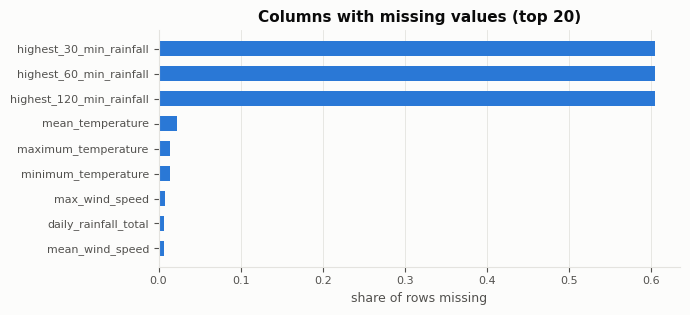

❌ Heavy missing data. The slides say to avoid this.

#### Data-cleaning load

,check,count
0,exact duplicate rows,9
1,duplicate feature rows,12
2,…of which with conflicting labels,3
3,constant columns,1
4,near-constant columns (≥99% one value),0
5,duplicate columns,0
6,ID-like columns,0
7,categorical/text columns,1
8,binary columns,0


categorical: {'station': 1} (unique values)


❌ Substantial cleaning needed (see table).

positive class = 1


#### Class balance

positives=1,193 / 2,746  rate=43.45%  imbalance ratio ≈ 1:1
expected positives: validation≈239, test≈239; per calibration bin (10 bins)≈24


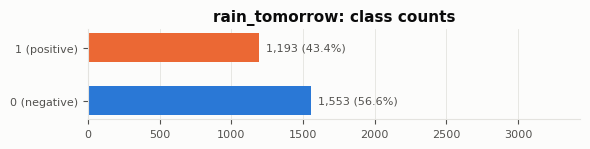

✅ Balance is fine.

✅ About 239 positives in validation.

Held out test: 550 rows (239 positives). Development split for label-driven checks: 2,196 rows.
model features (10): ['daily_rainfall_total', 'highest_30_min_rainfall', 'highest_60_min_rainfall', 'highest_120_min_rainfall', 'mean_temperature', 'maximum_temperature', 'minimum_temperature', 'mean_wind_speed', 'max_wind_speed', 'month_num'] 


#### Leakage scan: single-feature AUC (development split)

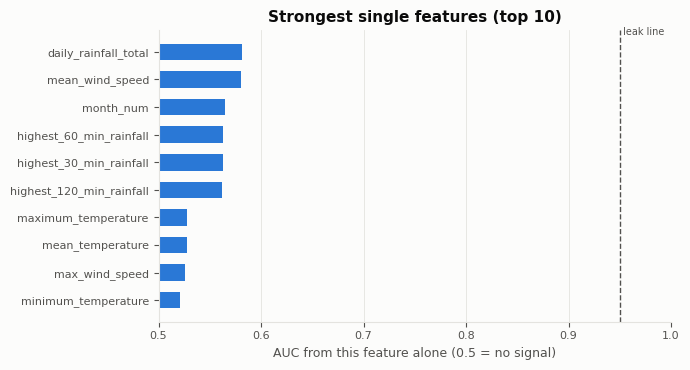

✅ No single feature is suspiciously predictive (max AUC 0.582, from `daily_rainfall_total`).

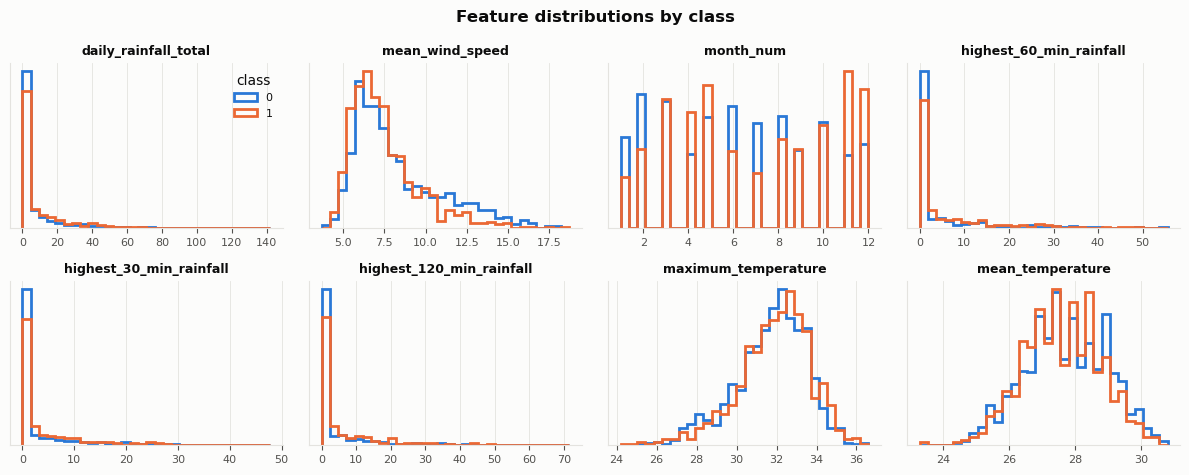

#### Correlated features (glassbox stability)

10 features; pairs with |r| ≥ 0.95: 5


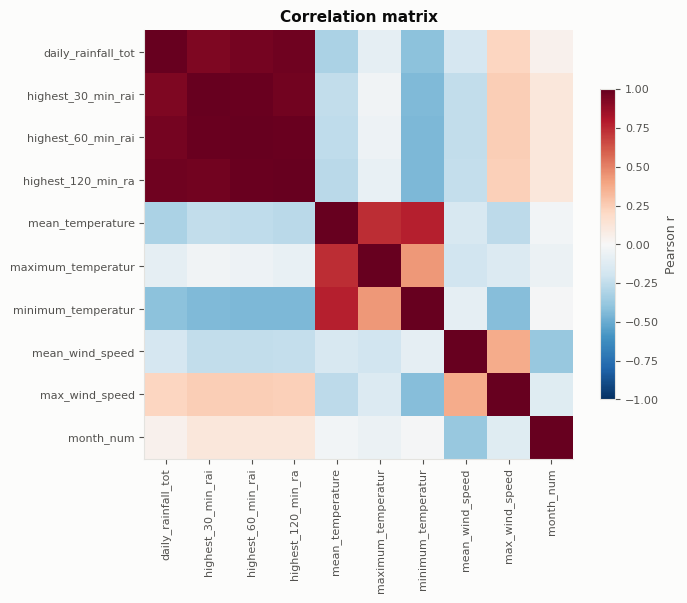

,feature_a,feature_b,|r|
0,daily_rainfall_total,highest_60_min_rainfall,0.955721
1,daily_rainfall_total,highest_120_min_rainfall,0.972419
2,highest_30_min_rainfall,highest_60_min_rainfall,0.985506
3,highest_30_min_rainfall,highest_120_min_rainfall,0.966245
4,highest_60_min_rainfall,highest_120_min_rainfall,0.989017


⚠️ 5 highly correlated pairs. Use LASSO or a ridge penalty, or drop one of each pair, before reading glassbox coefficients.

#### Difficulty check: untuned 5-fold CV AUC (development split)

glassbox: logistic regression    AUC = 0.621 ± 0.024   (0.1s)
blackbox: gradient boosting      AUC = 0.615 ± 0.019   (0.3s)


✅ Room to compare models (best AUC 0.621).

...

#### Train loss: L2 vs surrogate (5-fold out-of-fold AUC, development split)

,model,train loss,OOF AUC,"scores outside [0, 1]"
0,glassbox,L2,0.620,0.0%
1,glassbox,log loss,0.620,0.0%
2,blackbox,L2,0.619,3.1%
3,blackbox,log loss,0.614,0.0%


surrogate − L2 AUC: glassbox +0.000, blackbox -0.005


ℹ️ All four versions train without trouble. Small AUC differences are normal, because AUC only depends on the ranking. The L2 versions show their weakness in calibration and in scores outside [0, 1] (next check).

#### Calibration of the untuned models (out-of-fold, development split)

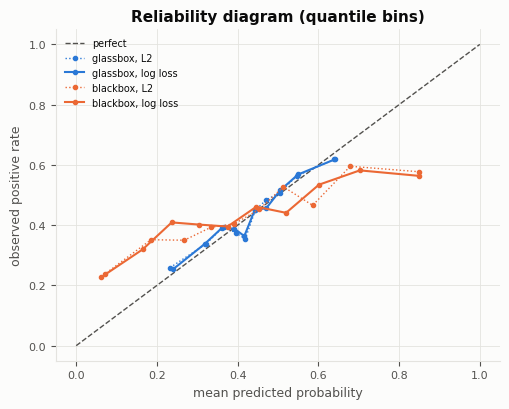

,model,train loss,Brier,ECE (10 bins),mean score
0,glassbox,L2,0.2361,0.0202,0.4338
1,glassbox,log loss,0.2357,0.0163,0.4338
2,blackbox,L2,0.2515,0.0981,0.4320
3,blackbox,log loss,0.2559,0.1157,0.4274
4,blackbox + Platt,log loss,0.2368,0.0134,0.4345


base rate in development split = 0.4344


✅ About 24 validation positives per calibration bin.

#### Validation noise: can a validation split of this size tell the models apart?

validation size ≈ 548 rows (238 positives)
blackbox AUC on a validation-sized split: 0.614 ± 0.040 (95% range)
blackbox − glassbox gap: -0.006, sd 0.020; blackbox wins in 37% of draws


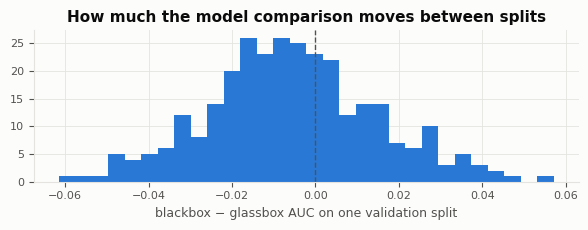

⚠️ A single validation split can't reliably separate glassbox and blackbox. Keep the search small, report the uncertainty, or use repeated CV for the decision.

#### Evaluation loss: threshold that minimises expected cost (FN = 5, FP = 1)

*Cost story:* A site pours concrete and it rains (FN): the pour is ruined. A site postpones for rain that never comes (FP): a day of crew time lost.

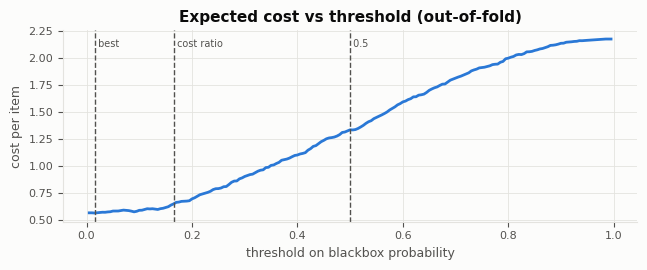

best threshold = 0.015 (cost 0.5660/item); threshold 0.5 costs 1.3342/item -> saving 58%
for a calibrated model the cost-ratio threshold would be 0.167; flag-nothing costs 2.1721, flag-everything costs 0.5656


✅ The evaluation loss moves the decision a lot away from 0.5, which gives the threshold slide something to say.

#### Tree SHAP smoke test (blackbox gradient boosting, development split)

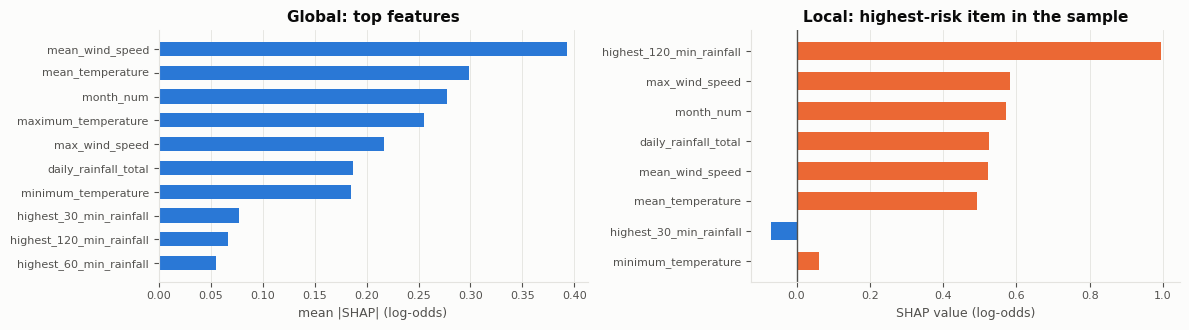

top feature `mean_wind_speed` carries 20% of total mean |SHAP|; rank agreement with single-feature AUC (Spearman) = 0.09


✅ Tree SHAP runs, and attributions are spread over several features: enough material for local and global plots.

In [37]:
DS = "J · SG rain tomorrow"
SG_DATASET = "d_03bb2eb67ad645d0188342fa74ad7066"
SG_RAIN_MM = 1.0

def sg_download(dataset_id, dest_dir):
    import requests
    base = f"https://api-open.data.gov.sg/v1/public/api/datasets/{dataset_id}"
    requests.get(base + "/initiate-download", timeout=60)
    url = None
    for _ in range(20):
        url = (requests.get(base + "/poll-download", timeout=60).json().get("data") or {}).get("url")
        if url: break
        time.sleep(3)
    if not url: raise RuntimeError("data.gov.sg did not return a download URL")
    os.makedirs(dest_dir, exist_ok=True)
    path = os.path.join(dest_dir, f"{dataset_id}.csv")
    with open(path, "wb") as fh: fh.write(requests.get(url, timeout=600).content)
    return dest_dir

def pick(cols, pattern):
    hits = [c for c in cols if re.search(pattern, c, re.I)]
    return hits[0] if hits else None

try:
    root = LOCAL_DIRS["sg"] or sg_download(SG_DATASET, os.path.expanduser("~/.cache/datagovsg"))
    f = find_files(root)[0]
    sgw = pd.read_csv(f); sgw.columns = [c.strip() for c in sgw.columns]
    print("loaded", f, "columns:", list(sgw.columns))
    col = {"station": pick(sgw.columns, r"station"), "date": pick(sgw.columns, r"^date$|date"),
           "year": pick(sgw.columns, r"^year$"), "month": pick(sgw.columns, r"^month$"), "day": pick(sgw.columns, r"^day$"),
           "rain": pick(sgw.columns, r"daily.*rain|rain.*total|total.*rain")}
    print("column mapping:", col)
    if col["date"]:
        sgw["_date"] = pd.to_datetime(sgw[col["date"]], errors="coerce")
    else:
        sgw["_date"] = pd.to_datetime(dict(year=sgw[col["year"]], month=sgw[col["month"]], day=sgw[col["day"]]), errors="coerce")
    num_cols = [c for c in sgw.columns if c not in (col["station"], col["date"], col["year"], col["month"], col["day"], "_date")]
    for c in num_cols: sgw[c] = pd.to_numeric(sgw[c], errors="coerce")    # dashes become NaN
    sgw = sgw.sort_values([col["station"], "_date"])
    nxt = sgw.groupby(col["station"])[[col["rain"], "_date"]].shift(-1)
    ok = (nxt["_date"] - sgw["_date"]).dt.days.eq(1) & nxt[col["rain"]].notna()
    sg = sgw.loc[ok, num_cols].copy()
    sg["month_num"] = sgw.loc[ok, "_date"].dt.month
    sg["station"] = sgw.loc[ok, col["station"]].astype(str)
    sg["rain_tomorrow"] = (nxt.loc[ok, col["rain"]] >= SG_RAIN_MM).astype(int)
    print(f"{len(sg):,} station-days with a next-day label, {sg['station'].nunique()} stations")
    overview(sg, DS)
except Exception as e:
    sg = None; print("Singapore weather not loaded:", repr(e))

if sg is not None:
    XJ_dev, yJ_dev, rankJ = standard_screen(sg, "rain_tomorrow", DS, positive=1, named=True, max_card=80,
        named_note="Named weather readings (today's rain, temperature, wind, month, station) give an explainable SHAP story.")
    S_J = extended_checks(XJ_dev, yJ_dev, DS, rankJ, c_fn=5, c_fp=1,
        story="A site pours concrete and it rains (FN): the pour is ruined. A site postpones for rain that never comes (FP): a day of crew time lost.")

---
## K. MixedWM38 mixed-type wafer maps (semiconductor round 2)
About 38,000 wafer maps from a wafer fab, all **52 × 52** with the same 0 / 1 / 2 coding as WM-811K (blank, pass die, fail die). Each map has an 8-dimensional multi-hot label for the basic patterns, so one wafer can carry several defects at once (38 classes: normal, 8 single, 29 mixed).

**Why it's worth screening next to D2:**
- It's the same semiconductor story as D, without D's friction: one size, an `.npz` file instead of a 2 GB legacy pickle, and every map is labelled.
- The 10 spatial features from section D are reused unchanged, so SHAP stays physically explainable.
- **Binary task:** "does this wafer contain pattern X?", set in `MW_POSITIVE`. Mixed wafers make this harder than D's "any pattern vs none", which helps with the near-perfect problem. The cell first screens all 8 patterns.

**Caveats to say on the slides:**
- The authors balanced the classes with GAN-generated maps, so part of the data is synthetic and the class rates are artificial. The cost story has to use your own assumed prevalence, not the dataset's.
- The label order below follows the dataset's GitHub page (C2–C9). Confirm it against the Kaggle card: the authors corrected the C7/C9 labels in a later release.

In [38]:
DS = "K · MixedWM38"
MW_PATTERNS = ["Center", "Donut", "Edge-Loc", "Edge-Ring", "Loc", "Near-full", "Scratch", "Random"]   # label order: check the dataset card
MW_POSITIVE = "Scratch"      # change after reading the per-pattern screen
try:
    root = get_dataset_dir("mixed")
    f = find_files(root, exts=(".npz",))[0]
    z = np.load(f, allow_pickle=False)
    arrs = {k: z[k] for k in z.files}
    maps = next(a for a in arrs.values() if a.ndim == 3)
    labels = next(a for a in arrs.values() if a.ndim == 2 and a.shape[1] == len(MW_PATTERNS))
    print(f"loaded {f}: maps {maps.shape}, labels {labels.shape}, keys {z.files}")
    t = time.time()
    feats = [wafer_features(m) for m in maps]
    keep = [f_ is not None for f_ in feats]
    mw = pd.DataFrame([f_ for f_ in feats if f_ is not None])
    mwl = pd.DataFrame(labels[keep].astype(int), columns=MW_PATTERNS)
    print(f"built {len(mw):,} feature rows in {time.time() - t:.0f}s")
    display(mwl.sum(1).value_counts().sort_index().rename_axis("patterns per wafer").to_frame("wafers"))
    overview(mw, DS, file_mb=os.path.getsize(f) / 1e6)
except Exception as e:
    mw = None; print("MixedWM38 not loaded:", repr(e))

if mw is not None:
    header("Which pattern to predict? Presence-vs-absence screen (development split)")
    dev_m, _ = train_test_split(np.arange(len(mw)), test_size=TEST_SIZE, random_state=SEED)
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    rows = []
    for c in MW_PATTERNS:
        yy = mwl[c].iloc[dev_m]
        a_g = cross_val_score(_models()["glassbox: logistic regression"], mw.iloc[dev_m], yy, cv=cv, scoring="roc_auc", n_jobs=-1).mean()
        a_b = cross_val_score(HistGradientBoostingClassifier(random_state=SEED), mw.iloc[dev_m], yy, cv=cv, scoring="roc_auc", n_jobs=-1).mean()
        rows.append({"pattern": c, "wafers containing it": int(mwl[c].sum()), "rate": f"{mwl[c].mean():.1%}",
                     "glassbox AUC": round(a_g, 3), "blackbox AUC": round(a_b, 3), "gap": round(a_b - a_g, 3)})
    display(pd.DataFrame(rows))
    print("Prefer a pattern with blackbox AUC between ~0.80 and ~0.97 and a clear positive gap.")

loaded /Users/testuser/.cache/kagglehub/datasets/co1d7era/mixedtype-wafer-defect-datasets/versions/4/Wafer_Map_Datasets.npz: maps (38015, 52, 52), labels (38015, 8), keys ['arr_0', 'arr_1']
built 38,015 feature rows in 12s


,wafers
patterns per wafer,
0,1000
1,7015
2,13000
3,13000
4,4000


#### Size and structure

rows=38,015  columns=10  in-memory=3.0 MB  file=412.4 MB
dtypes: {'float64': 8, 'int64': 2}


,n_dies,fail_rate,center_fail_rate,middle_fail_rate,edge_fail_rate,outer_ring_fail_rate,n_fail_clusters,largest_cluster_share,largest_cluster_radius,angular_concentration
0,2061,0.300825,0.524324,0.220443,0.323308,0.509709,106,0.129549,0.884098,0.154518
1,2061,0.300825,0.875676,0.210591,0.269737,0.368932,121,0.098981,0.222773,0.093790
2,2061,0.327996,0.789189,0.274631,0.288534,0.419903,92,0.099951,0.246756,0.034598
3,2061,0.277050,0.329730,0.184729,0.338346,0.514563,122,0.078117,0.888960,0.124899
4,2061,0.248423,0.459459,0.250000,0.210526,0.266990,126,0.044153,0.205165,0.109107


✅ Size is fine (38,015 rows).

#### Which pattern to predict? Presence-vs-absence screen (development split)

,pattern,wafers containing it,rate,glassbox AUC,blackbox AUC,gap
0,Center,13000,34.2%,0.934,0.989,0.054
1,Donut,12000,31.6%,0.974,0.992,0.018
2,Edge-Loc,13000,34.2%,0.696,0.985,0.289
3,Edge-Ring,12000,31.6%,0.988,0.993,0.004
4,Loc,18000,47.3%,0.941,0.979,0.038
5,Near-full,149,0.4%,1.000,0.896,-0.104
6,Scratch,19000,50.0%,0.685,0.918,0.233
7,Random,866,2.3%,0.999,1.000,0.001


Prefer a pattern with blackbox AUC between ~0.80 and ~0.97 and a clear positive gap.


#### Missing data

missing cells: 0 (0.00%); columns with any missing: 0/11


✅ No meaningful missing data.

#### Data-cleaning load

,check,count
0,exact duplicate rows,1024
1,duplicate feature rows,1024
2,…of which with conflicting labels,0
3,constant columns,0
4,near-constant columns (≥99% one value),0
5,duplicate columns,0
6,ID-like columns,0
7,categorical/text columns,0
8,binary columns,0


⚠️ Some cleaning needed (see table).

positive class = 1


#### Class balance

positives=19,000 / 38,015  rate=49.98%  imbalance ratio ≈ 1:1
expected positives: validation≈3800, test≈3800; per calibration bin (10 bins)≈380


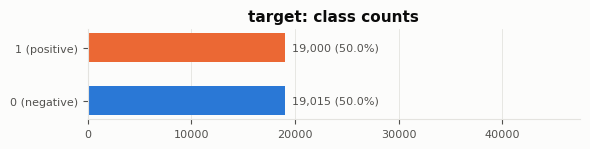

✅ Balance is fine.

✅ About 3800 positives in validation.

Held out test: 7,603 rows (3800 positives). Development split for label-driven checks: 30,412 rows.
model features (10): ['n_dies', 'fail_rate', 'center_fail_rate', 'middle_fail_rate', 'edge_fail_rate', 'outer_ring_fail_rate', 'n_fail_clusters', 'largest_cluster_share', 'largest_cluster_radius', 'angular_concentration'] 


#### Leakage scan: single-feature AUC (development split)

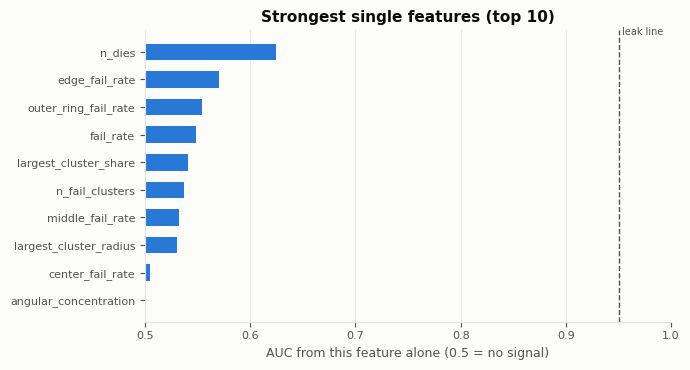

✅ No single feature is suspiciously predictive (max AUC 0.625, from `n_dies`).

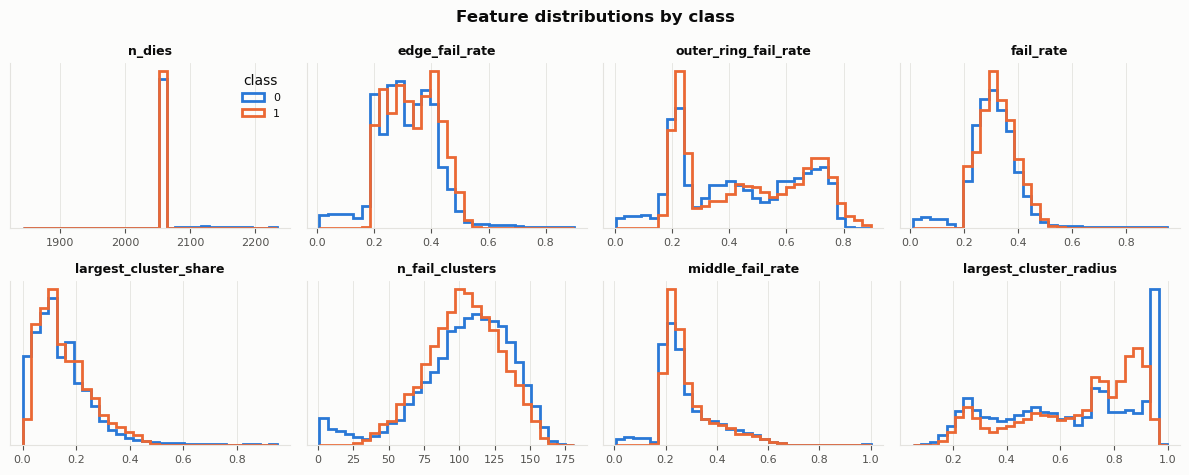

#### Correlated features (glassbox stability)

10 features; pairs with |r| ≥ 0.95: 0


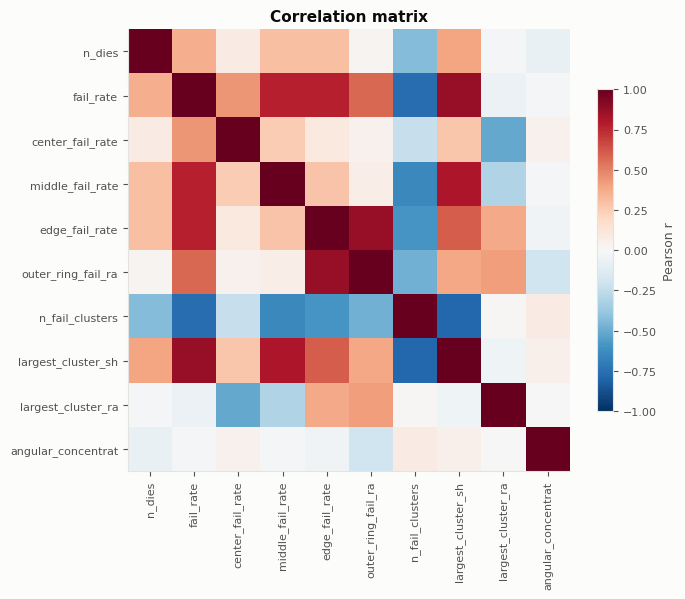

✅ No near-duplicate features.

#### Difficulty check: untuned 5-fold CV AUC (development split)

glassbox: logistic regression    AUC = 0.685 ± 0.006   (0.3s)
blackbox: gradient boosting      AUC = 0.917 ± 0.002   (0.9s)


✅ Room to compare models (best AUC 0.917).

blackbox − glassbox AUC gap: +0.232 (a positive gap gives you an interpretability-vs-performance story)


...

#### Train loss: L2 vs surrogate (5-fold out-of-fold AUC, development split)

,model,train loss,OOF AUC,"scores outside [0, 1]"
0,glassbox,L2,0.694,1.2%
1,glassbox,log loss,0.685,0.0%
2,blackbox,L2,0.915,12.0%
3,blackbox,log loss,0.917,0.0%


surrogate − L2 AUC: glassbox -0.009, blackbox +0.002


ℹ️ All four versions train without trouble. Small AUC differences are normal, because AUC only depends on the ranking. The L2 versions show their weakness in calibration and in scores outside [0, 1] (next check).

#### Calibration of the untuned models (out-of-fold, development split)

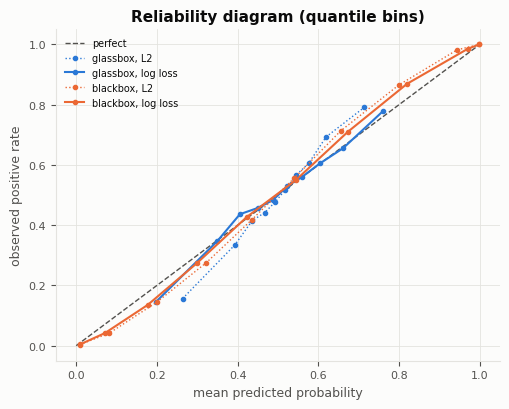

,model,train loss,Brier,ECE (10 bins),mean score
0,glassbox,L2,0.2243,0.0466,0.5025
1,glassbox,log loss,0.2218,0.0125,0.4998
2,blackbox,L2,0.1203,0.0345,0.4985
3,blackbox,log loss,0.1182,0.0231,0.4987
4,blackbox + Platt,log loss,0.1174,0.0043,0.4998


base rate in development split = 0.4998


✅ About 380 validation positives per calibration bin.

#### Validation noise: can a validation split of this size tell the models apart?

validation size ≈ 7,603 rows (3800 positives)
blackbox AUC on a validation-sized split: 0.917 ± 0.005 (95% range)
blackbox − glassbox gap: +0.232, sd 0.005; blackbox wins in 100% of draws


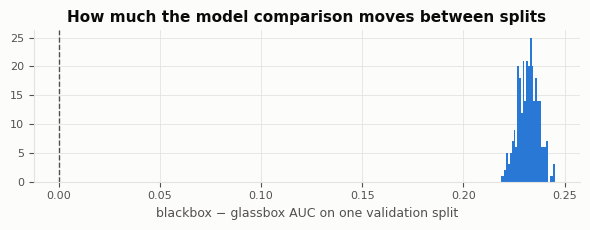

✅ The model comparison is stable at this validation size.

#### Evaluation loss: threshold that minimises expected cost (FN = 10, FP = 1)

*Cost story:* A wafer with a Scratch pattern that isn't flagged (FN) lets a tool or handling fault keep damaging lots; a false flag (FP) costs one engineer reviewing the map.

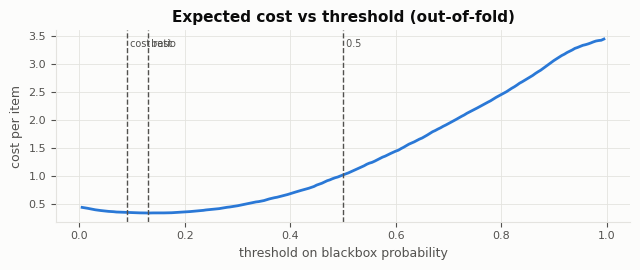

best threshold = 0.130 (cost 0.3482/item); threshold 0.5 costs 1.0261/item -> saving 66%
for a calibrated model the cost-ratio threshold would be 0.091; flag-nothing costs 4.9980, flag-everything costs 0.5002


✅ The evaluation loss moves the decision a lot away from 0.5, which gives the threshold slide something to say.

#### Tree SHAP smoke test (blackbox gradient boosting, development split)

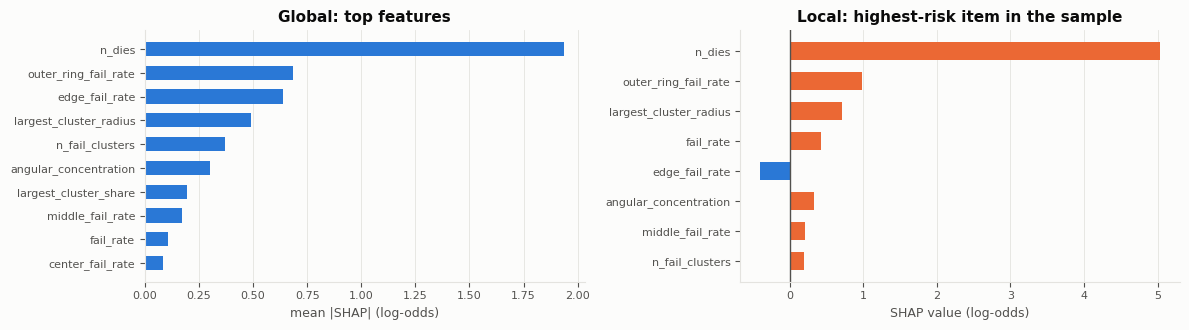

top feature `n_dies` carries 39% of total mean |SHAP|; rank agreement with single-feature AUC (Spearman) = 0.60


✅ Tree SHAP runs, and attributions are spread over several features: enough material for local and global plots.

In [39]:
if mw is not None:
    mw_bin = mw.assign(target=mwl[MW_POSITIVE].values)
    XK_dev, yK_dev, rankK = standard_screen(mw_bin, "target", DS, positive=1, named=True,
        named_note="Same named spatial features as D (zone fail rates, cluster size and radius, angular concentration).")
    S_K = extended_checks(XK_dev, yK_dev, DS, rankK, c_fn=10, c_fp=1,
        story=f"A wafer with a {MW_POSITIVE} pattern that isn't flagged (FN) lets a tool or handling fault keep damaging lots; a false flag (FP) costs one engineer reviewing the map.")

#### K · artefact check: `n_dies` and duplicates
In the first run, `n_dies` was the top SHAP feature for Scratch (39%), and dropping it cost 0.04 AUC. Every MixedWM38 map is 52 × 52, so the number of dies on a wafer has no physical reason to depend on whether it has a scratch. If it does, the model is probably picking up how the maps were made (for example, the GAN augmentation) rather than the defect. There were also 1,024 exact duplicate feature rows. This cell measures both and reruns the baselines without them.

In [40]:
if mw is not None:
    header("n_dies by class (shortcut check)")
    display(mw_bin.groupby("target")["n_dies"].describe().round(1))
    print("distinct n_dies values:", mw_bin["n_dies"].nunique())
    dup = mw_bin.duplicated()
    print(f"exact duplicate rows: {int(dup.sum()):,}; their positive rate {mw_bin.loc[dup, 'target'].mean():.1%} "
          f"vs {mw_bin['target'].mean():.1%} overall")
    clean = mw_bin.loc[~dup].drop(columns=["n_dies"])
    XKc = clean.drop(columns=["target"]); yKc = clean["target"]
    devKc, _ = train_test_split(np.arange(len(clean)), test_size=TEST_SIZE, stratify=yKc, random_state=SEED)
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    for name, m in _models().items():
        s = cross_val_score(m, XKc.iloc[devKc], yKc.iloc[devKc], cv=cv, scoring="roc_auc", n_jobs=-1)
        print(f"deduplicated, without n_dies  {name:32s} AUC = {s.mean():.3f} ± {s.std():.3f}")
    say("info", "If n_dies differs clearly between classes, drop it, and say why on the slides: it's a 'delete a shortcut feature' story. "
                "If the AUC barely moves without it and without the duplicates, K is safe to use as it is.")

#### n_dies by class (shortcut check)

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,19015.0,2065.6,21.7,1843.0,2061.0,2061.0,2061.0,2234.0
1,19000.0,2061.4,0.6,2061.0,2061.0,2061.0,2062.0,2065.0


distinct n_dies values: 167
exact duplicate rows: 1,024; their positive rate 97.7% vs 50.0% overall
deduplicated, without n_dies  glassbox: logistic regression    AUC = 0.617 ± 0.008
deduplicated, without n_dies  blackbox: gradient boosting      AUC = 0.876 ± 0.004


ℹ️ If n_dies differs clearly between classes, drop it, and say why on the slides: it's a 'delete a shortcut feature' story. If the AUC barely moves without it and without the duplicates, K is safe to use as it is.

---
## L. Semiconductor Sensor Data for Predictive Quality (semiconductor round 2)
A **simulated** tabular dataset of about 4,200 wafers, with process-sensor readings from lithography, etching and deposition and a binary quality label. Its file layout couldn't be checked before writing this cell, so, as in section B, **the target is auto-detected**. Set `TARGET_L` and `POSITIVE_L` by hand if the guess is wrong.

What to watch: like B (also simulated), check that the positives aren't too rare, and that the label isn't generated from one or two sensors (leakage scan and SHAP dominance flag).

In [41]:
DS = "L · Semiconductor sensors (sim.)"
TARGET_L = None          # None = auto-detect
POSITIVE_L = None        # None = auto ('fail/defect/1' label, else the minority class)
try:
    root = get_dataset_dir("ssq")
    files = find_files(root)
    print("CSV files found:", [os.path.basename(p) for p in files])
    f = files[0]
    ssq = pd.read_csv(f)
    if TARGET_L is None:
        cands = [c for c in ssq.columns if re.search(r"(defect|label|class|target|fail|pass|status|quality|result|join|yield)", c, re.I)
                 and ssq[c].nunique() == 2]
        TARGET_L = cands[0] if cands else [c for c in ssq.columns if ssq[c].nunique() == 2][-1]
    print(f"target column → {TARGET_L!r}   values: {ssq[TARGET_L].value_counts().to_dict()}")
    overview(ssq, DS, file_mb=os.path.getsize(f) / 1e6)
except Exception as e:
    ssq = None; print("Semiconductor sensor dataset not loaded:", repr(e))

if ssq is not None:
    XL_dev, yL_dev, rankL = standard_screen(ssq, TARGET_L, DS, positive=POSITIVE_L, named=True,
        named_note="Named process sensors, but simulated. Check that the SHAP ranking is physically plausible.")
    S_L = extended_checks(XL_dev, yL_dev, DS, rankL, c_fn=20, c_fp=1,
        story="A bad wafer that continues (FN) is scrapped at final test after all the value has been added; a false hold (FP) costs one metrology step.")

Semiconductor sensor dataset not loaded: KaggleApiHTTPError("403 Client Error.\n\nYou don't have permission to access resource at URL: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDataset. Please make sure you are authenticated if you are trying to access a private resource or a resource requiring consent.")


---
## Scorecard: all datasets against the Project 2 requirements
✅ fine · ⚠️ manageable with extra work · ❌ conflicts with the slide guidance. Numbers come from the cells above.

In [42]:
order = ["rows", "columns", "size", "missing_pct", "missing", "cleaning", "pos_rate_pct", "imbalance",
         "val_positives", "val_size", "max_single_auc", "leakage", "corr_pairs", "auc_glass", "auc_black",
         "difficulty", "named_features", "label_conflicts", "features_per_row",
         "auc_glass_l2", "auc_black_l2", "ece_black", "ece_black_platt", "calibration",
         "auc_ci_halfwidth", "gap_sd", "noise", "t_star", "cost_saving_pct", "shap_top", "shap_top_share", "shap"]
sc = pd.DataFrame(SCORECARD).T
sc = sc[[c for c in order if c in sc.columns]]
flags = ["size", "missing", "cleaning", "imbalance", "val_size", "leakage", "difficulty", "named_features",
         "calibration", "noise", "shap"]
pretty = sc.copy()
for c in flags:
    if c in pretty: pretty[c] = pretty[c].map(lambda v: ICON.get(v, "") if isinstance(v, str) else "")
display(pretty.T)

summary = pd.DataFrame({
    "❌ count": sc[[f for f in flags if f in sc]].apply(lambda r: (r == "bad").sum(), axis=1),
    "⚠️ count": sc[[f for f in flags if f in sc]].apply(lambda r: (r == "warn").sum(), axis=1),
}).sort_values(["❌ count", "⚠️ count"])
display(summary)
print("Fewest ❌ then fewest ⚠️ = least friction for Project 2 →", summary.index[0])
print("B is excluded by the review (7 positives), whatever its counts say.")

,A · AI4I,B · Synthetic wafer,C · MachineHack wafer,D · WM-811K,D2 · WM-811K Edge-Loc vs Loc,E · Steel plates,F · Machine failure (sensors),G · Manufacturing defects,H · APS Scania,I · SECOM,J · SG rain tomorrow,K · MixedWM38
rows,10000,5000,1763,811457,8782,1941,944,3240,60000,1567,2746,38015
columns,10,9,1559,10,10,34,10,17,171,591,12,10
size,✅,✅,✅,⚠️,✅,✅,✅,✅,✅,✅,✅,✅
missing_pct,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.28,4.53,15.71,0.0
missing,✅,✅,✅,✅,✅,✅,✅,✅,❌,⚠️,❌,✅
cleaning,✅,✅,❌,⚠️,⚠️,✅,✅,✅,✅,⚠️,❌,⚠️
pos_rate_pct,3.39,0.14,8.11,14.75,59.09,20.71,41.63,84.04,1.67,6.64,43.45,49.98
imbalance,⚠️,❌,⚠️,✅,✅,✅,✅,✅,❌,⚠️,✅,✅
val_positives,68,1,29,590,1038,80,79,545,200,21,239,3800
val_size,✅,⚠️,⚠️,✅,✅,✅,✅,✅,✅,⚠️,✅,✅


,❌ count,⚠️ count
G · Manufacturing defects,0,0
D2 · WM-811K Edge-Loc vs Loc,0,1
E · Steel plates,0,1
K · MixedWM38,0,1
A · AI4I,0,2
F · Machine failure (sensors),0,2
D · WM-811K,0,3
I · SECOM,1,6
J · SG rain tomorrow,2,1
B · Synthetic wafer,2,2


Fewest ❌ then fewest ⚠️ = least friction for Project 2 → G · Manufacturing defects
B is excluded by the review (7 positives), whatever its counts say.


### How to read the scorecard
- **❌ size, missing or imbalance:** the slides say to avoid these. Pick something else unless you have a strong reason.
- **⚠️ difficulty (AUC ≥ 0.98):** this is fine, but plan which features to delete (use the difficulty probe table), or change the question (see D2), so your glassbox vs blackbox comparison and threshold tuning mean something.
- **❌ named features:** SHAP will produce plots you can't explain. Expect hard questions in the live Q&A.
- **⚠️ noise:** one validation split can't tell glassbox from blackbox. Keep the hyperparameter grids small ("think more, try less"), report the uncertainty, and look at the test set only once.
- **⚠️ calibration:** fewer than 10 validation positives per bin. Use fewer or quantile bins for the reliability diagram.
- **⚠️ shap:** one feature carries most of the attribution, which is often leakage or a near-deterministic generator.
- **cost_saving_pct:** how much the cost-minimising threshold saves over 0.5. A large number means the evaluation-loss slide has a real story.
- Use the **test split** held out here (same `SEED`) for the final evaluation only.

## Review findings (checkpoints 1 and 2)

### Checkpoint 1: gaps in the original EDA, now covered
| Gap against the slides | What was added |
|---|---|
| "Each model shall have two versions: L2 loss vs other surrogate losses" wasn't tested | Check 10 trains ridge-on-0/1 vs logistic, and GBM squared error vs log loss |
| Calibration only counted positives per bin | Check 11: reliability diagram, Brier, ECE, cross-fitted Platt |
| The evaluation loss and threshold were only a text note | Check 13: expected-cost curve, best threshold vs 0.5, saving |
| SHAP was only "are the features named?" | Check 14: actually runs tree SHAP, global + local plots, dominance flag |
| The optimiser's-curse / validation-overfitting slides had no check | Check 12: spread of validation AUC and of the model gap at the planned validation size |
| B's leakage flag and model results came from 7 positives | B is marked excluded |
| D is near-perfect and deleting features doesn't help | D2 changes the question to Edge-Loc vs Loc |
| A is synthetic, has 27 contradictory labels, and many public notebooks | Noted under A; glassbox-with-physics-features check added |
| Kaggle usability rating wasn't recorded | Hand-filled `KAGGLE_META` table |

### Checkpoint 2: verdicts from the cells that have been run (A–D)
- **A · AI4I** is still the front-runner: no ❌, 68 validation positives, blackbox − glassbox gap +0.076, named physical features. The risks are that it's synthetic and heavily used on Kaggle.
- **B** is excluded (7 positives).
- **C** fails on anonymous features and cleaning (829 duplicate columns, 12 conflicting duplicate rows), with only about 29 validation positives.
- **D** needs a 2 GB download, legacy-pickle handling and feature extraction, and the default task is too easy. D2 may fix the difficulty, but the preprocessing burden remains.

### Verdicts for E–K
The documentation-based expectations written before the datasets were run have been removed. The verdicts for E–K are in the next cell, and every number there comes from the local run on the real datasets.

## Top 3 after round 2 (A–K, semiconductor focus)
K (MixedWM38) has now been run. L couldn't be downloaded: Kaggle returned 403, which usually means the dataset needs its terms accepted on the Kaggle page, or it's private or removed.

| Rank | Dataset | Strengths (from the run) | What to handle |
|---|---|---|---|
| **1** | **D2 · WM-811K Edge-Loc vs Loc** (semiconductor, real fab data) | Every check ✅ except preprocessing. About **1,038 validation positives**, so validation AUC (± 0.005), calibration and the threshold are all stable. Not near-perfect (glassbox 0.963, blackbox 0.974). The cost-optimal threshold (0.26) matches the cost-ratio threshold (0.25). The L2 glassbox is badly calibrated (ECE 0.10 vs 0.027 for log loss), a concrete L2-vs-surrogate slide. The top SHAP feature, `largest_cluster_radius` (44%), has an obvious physical meaning. | The gap is small (+0.011, sd 0.002), so the decision is "the glassbox is nearly as good, so choose it". Preprocessing: the 2 GB legacy pickle plus feature extraction. Optional: drop `largest_cluster_radius` (AUC → 0.945) to widen the comparison. |
| **2 (provisional)** | **K · MixedWM38, Scratch vs not** (semiconductor) | Easy to load (one `.npz`, all maps labelled, 52 × 52). **The largest and most stable gap of any dataset:** glassbox 0.685 vs blackbox 0.917 (+0.232, sd 0.005). A scratch is a thin line, which a linear model on zone rates can't see, so that's a real interpretability-vs-performance story. 3,800 validation positives; calibration ✅ (ECE 0.023 → 0.004 after Platt). The threshold saves 66% at FN:FP = 10:1. | **`n_dies` is the top SHAP driver (39%)**, and dropping it lowers the blackbox AUC from 0.917 to 0.875 (difficulty probe). It isn't known yet whether `n_dies` is a real signal or an artefact of how the maps were made: **the artefact check above hasn't been run on the real data, so this rank is provisional until it has.** **1,024 duplicate rows**, and the classes were balanced with GAN-generated maps: dedupe, and use your own assumed scratch prevalence in the cost story, not the dataset's 50%. With a 0.685 glassbox, also consider a shallow tree, EBM or FIGS as the glassbox (all on the slides). |
| **3** | **E · Steel plates, Bumps vs rest** (non-semiconductor fallback) | Real data, no missing values, no cleaning. Stable gap (+0.085, sd 0.017). SHAP spread out (top feature 11%). | Not semiconductor. Correlated pairs: use LASSO. At FN:FP = 20:1 the threshold sits at the grid edge (0.005): Platt-calibrate first or use about 5:1. About 8 validation positives per calibration bin, so use quantile bins. |

**Next:** A · AI4I (stable gap, but synthetic, 3.4% positive, and heavily used on Kaggle).

**Why the others rank lower:**
- **G:** a thin threshold story (4% saving), synthetic data, and defects as the 84% majority.
- **F:** the glassbox beats the blackbox, and `VOC` dominates.
- **D (any pattern vs none):** near-perfect (0.995).
- **C, H, I:** anonymous features. **J:** weak signal (AUC 0.62) and 16% missing.
- **K's other patterns:** Edge-Loc's blackbox is near-perfect (0.985). Center, Donut, Edge-Ring and Random are too easy (≥ 0.989). Near-full has only 149 positives.

**Decision between 1 and 2:** if the K artefact check shows `n_dies` is a shortcut and the gap survives without it, K gives the stronger glassbox-vs-blackbox story with far less preprocessing. Otherwise stay with D2, which is all real data.